# Import Package & Module

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LinearSegmentedColormap
from math import ceil
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from scipy.stats import gaussian_kde, pointbiserialr, chi2_contingency


from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier, Pool

plt.style.use('seaborn-v0_8-darkgrid')

print("Semua Import Berhasil")

Semua Import Berhasil


# Layout Design

In [2]:
def apply_dark_theme():
    """Panggil sekali di cell pertama notebook — ini bagian yang benar-benar universal."""
    BG_COLOR, PANEL_COLOR, TEXT_COLOR, GRID_COLOR = "#0f1117", "#1a1d27", "#e8eaf0", "#2e3250"
    plt.rcParams.update({
        "figure.facecolor": BG_COLOR, "axes.facecolor": PANEL_COLOR,
        "axes.edgecolor": GRID_COLOR, "axes.labelcolor": TEXT_COLOR,
        "axes.titlecolor": TEXT_COLOR, "xtick.color": TEXT_COLOR,
        "ytick.color": TEXT_COLOR, "text.color": TEXT_COLOR,
        "grid.color": GRID_COLOR, "grid.linestyle": "--",
        "grid.alpha": 0.4, "font.family": "monospace",
        "legend.facecolor": PANEL_COLOR, "legend.edgecolor": GRID_COLOR,
        "legend.labelcolor": TEXT_COLOR,
    })
    return BG_COLOR, PANEL_COLOR, TEXT_COLOR, GRID_COLOR

BG_COLOR, PANEL_COLOR, TEXT_COLOR, GRID_COLOR = apply_dark_theme()

# Konteks dan Metodologi Dataset

**Sumber Data**

Dataset ini dikumpulkan secara acak dari basis data sebuah perusahaan telekomunikasi di Iran selama periode 12 bulan. Data terdiri atas 3.150 baris, dengan setiap baris merepresentasikan satu pelanggan, dan 13 kolom atribut.

**Atribut Dataset**

Atribut yang tersedia meliputi Call Failure, Frequency of SMS, Complains, Distinct Called Numbers, Subscription Length, Age Group, Charge Amount, Tariff Plan, Seconds of Use, Status, Frequency of Use, dan Customer Value.

**Struktur Temporal dan Planning Gap**

Seluruh atribut prediktor (di luar target Churn) merupakan hasil agregasi dari 9 bulan pertama periode pengamatan. Label target Churn diukur pada akhir bulan ke-12, sehingga terdapat jeda waktu 3 bulan antara periode agregasi fitur dan waktu pengukuran label. Jeda ini disebut sebagai planning gap, dan secara desain berfungsi mencegah kebocoran informasi temporal (temporal data leakage) antara fitur dan target.

**Implikasi Metodologis**

Struktur planning gap ini mengonfirmasi bahwa nilai fitur secara waktu mendahului label churn, sehingga aman digunakan sebagai prediktor tanpa risiko leakage berbasis waktu. Meskipun demikian, kausalitas antar-fitur dan churn tidak dapat disimpulkan secara langsung dari struktur ini. Seluruh insight pada notebook ini bersifat asosiatif (korelasional), bukan kausal. Beberapa atribut, seperti Status, berpotensi berfungsi sebagai sinyal peringatan dini (early indicator) yang muncul sebelum churn resmi tercatat, bukan sebagai faktor penyebab independen. Interpretasi terhadap atribut semacam ini perlu dilakukan dengan kehati-hatian, dan disarankan untuk divalidasi lebih lanjut melalui data time-series bulanan atau eksperimen retensi terkontrol apabila klaim kausal diperlukan.

**Sumber Referensi**

Jafari-Marandi, R., Denton, J., Idris, A., Smith, B. K., & Keramati, A. (2020). *Iranian Churn Dataset*. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/563/iranian+churn+dataset

In [4]:
df = pd.read_csv('../dataset/Customer Churn.csv')
TARGET = 'Churn'

In [5]:
df.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)

In [ ]:
df.describe()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


In [ ]:
df.isna().sum()

,0
Call Failure,0
Complains,0
Subscription Length,0
Charge Amount,0
Seconds of Use,0
Frequency of use,0
Frequency of SMS,0
Distinct Called Numbers,0
Age Group,0
Tariff Plan,0


# **FASE 1: Data Preparation & Quality Check (Pembersihan)**

# A. Duplicated Data

### Step 1: Kenali dulu siapa duplikatnya





In [ ]:
# Analisis Duplikat Menyeluruh

print('=' * 55)
print('  ANALISIS DUPLIKAT DATA')
print('=' * 55)

TARGET_COLUMN = 'Churn'
total      = len(df)
n_dup      = df.duplicated().sum()
n_unique   = total - n_dup
dup_rate   = n_dup / total * 100

print(f'\nTotal baris          : {total:,}')
print(f'Baris unik           : {n_unique:,}')
print(f'Baris duplikat       : {n_dup:,}')
print(f'Persentase duplikat  : {dup_rate:.2f}%')

# Ambil baris yang duplikat
dup_df  = df[df.duplicated(keep=False)].copy()
dup_first = df[df.duplicated(keep='first')].copy()

print(f'\nContoh 5 baris duplikat:')
print(dup_df.head(10).to_string())

  ANALISIS DUPLIKAT DATA

Total baris          : 3,150
Baris unik           : 2,850
Baris duplikat       : 300
Persentase duplikat  : 9.52%

Contoh 5 baris duplikat:
   Call  Failure  Complains  Subscription  Length  Charge  Amount  Seconds of Use  Frequency of use  Frequency of SMS  Distinct Called Numbers  Age Group  Tariff Plan  Status  Age  Customer Value  Churn
0              8          0                    38               0            4370                71                 5                       17          3            1       1   30         197.640      0
1              0          0                    39               0             318                 5                 7                        4          2            1       2   25          46.035      0
2             10          0                    37               0            2453                60               359                       24          3            1       1   30        1536.520      0
3             10      

### Step 2: Cek apakah duplikat condong ke kelas tertentu (churn atau tidak)

In [ ]:
# Apakah duplikat bias ke salah satu kelas?

print('\n' + '=' * 55)
print('  DISTRIBUSI DUPLIKAT VS KELAS TARGET')
print('=' * 55)

# Distribusi churn di seluruh data
dist_all = df[TARGET_COLUMN].value_counts(normalize=True).rename('Semua Data')

# Distribusi churn di baris duplikat saja
dist_dup = dup_df[TARGET_COLUMN].value_counts(normalize=True).rename('Baris Duplikat')

# Distribusi churn di baris unik saja
unique_df = df.drop_duplicates()
dist_uniq = unique_df[TARGET_COLUMN].value_counts(normalize=True).rename('Baris Unik')

comparison = pd.concat([dist_all, dist_dup, dist_uniq], axis=1).round(4)
print(comparison)

churn_all  = df[TARGET_COLUMN].mean()
churn_dup  = dup_df[TARGET_COLUMN].mean()
churn_uniq = unique_df[TARGET_COLUMN].mean()

print(f'\nChurn rate — Semua data    : {churn_all:.1%}')
print(f'Churn rate — Baris duplikat: {churn_dup:.1%}')
print(f'Churn rate — Baris unik    : {churn_uniq:.1%}')

if abs(churn_dup - churn_all) > 0.05:
    print('\n⚠  TEMUAN: Duplikat memiliki distribusi churn yang berbeda signifikan.')
    print('   Menghapus duplikat AKAN mengubah keseimbangan kelas.')
else:
    print('\nℹ  Churn rate duplikat vs keseluruhan tidak berbeda signifikan.')
    print('   Namun ini BELUM cukup untuk menyimpulkan "aman dihapus",')
    print('   perlu dicek juga apakah profil FITUR duplikat berbeda dari populasi umum (lihat Step 3).')


  DISTRIBUSI DUPLIKAT VS KELAS TARGET
       Semua Data  Baris Duplikat  Baris Unik
Churn                                        
0          0.8429          0.8258      0.8435
1          0.1571          0.1742      0.1565

Churn rate — Semua data    : 15.7%
Churn rate — Baris duplikat: 17.4%
Churn rate — Baris unik    : 15.6%

ℹ  Churn rate duplikat vs keseluruhan tidak berbeda signifikan.
   Namun ini BELUM cukup untuk menyimpulkan "aman dihapus",
   perlu dicek juga apakah profil FITUR duplikat berbeda dari populasi umum (lihat Step 3).


### Step 3: Cek pola dataset, fitur mana yang paling sering identik di duplikat

In [ ]:
# ── Fitur apa yang paling membedakan duplikat?

print('\n' + '=' * 55)
print('  POLA FITUR PADA BARIS DUPLIKAT')
print('=' * 55)

# Bandingkan rata-rata tiap fitur: duplikat vs unik
num_features = df.select_dtypes(include=np.number).columns.tolist()
if TARGET_COLUMN in num_features:
    num_features.remove(TARGET_COLUMN)

stats = []
for col in num_features:
    mean_all  = df[col].mean()
    mean_dup  = dup_df[col].mean()
    mean_uniq = unique_df[col].mean()
    diff_pct  = abs(mean_dup - mean_all) / (abs(mean_all) + 1e-9) * 100
    stats.append({
        'Fitur':          col,
        'Mean Semua':     round(mean_all, 3),
        'Mean Duplikat':  round(mean_dup, 3),
        'Mean Unik':      round(mean_uniq, 3),
        'Selisih (%)':    round(diff_pct, 2),
    })

stats_df = pd.DataFrame(stats).sort_values('Selisih (%)', ascending=False)
print(stats_df.to_string(index=False))
print('\nFitur dengan selisih > 5% perlu diperhatikan.')


  POLA FITUR PADA BARIS DUPLIKAT
                  Fitur  Mean Semua  Mean Duplikat  Mean Unik  Selisih (%)
              Complains       0.077          0.043      0.081        43.78
         Charge  Amount       0.943          0.652      0.975        30.89
          Call  Failure       7.628          6.131      7.802        19.62
Distinct Called Numbers      23.510         20.183     23.871        14.15
       Frequency of use      69.461         60.166     70.485        13.38
         Seconds of Use    4472.460       3890.013   4534.243        13.02
       Frequency of SMS      73.175         66.551     73.790         9.05
         Customer Value     470.973        428.907    474.990         8.93
                 Status       1.248          1.331      1.240         6.64
              Age Group       2.826          2.751      2.835         2.67
                    Age      30.998         30.355     31.077         2.08
            Tariff Plan       1.078          1.058      1.080     

### Step 4: SIMULASI DAMPAK (SANITY CHECK): Apakah Penghapusan Duplikat Mempengaruhi Signal Prediktif Data?

In [ ]:
# ── Simulasi dampak penghapusan duplikat terhadap model

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

print('\n' + '=' * 55)
print('  SIMULASI DAMPAK PENGHAPUSAN DUPLIKAT')
print('=' * 55)

def quick_score(data):
    X_ = data.drop(columns=[TARGET_COLUMN]).select_dtypes(include=np.number)
    y_ = data[TARGET_COLUMN]
    sc = StandardScaler()
    X_ = sc.fit_transform(X_)
    clf = LogisticRegression(max_iter=1000, random_state=180915)
    scores = cross_val_score(clf, X_, y_, cv=5, scoring='roc_auc')
    return scores.mean(), scores.std()

auc_with, std_with   = quick_score(df)
auc_without, std_without = quick_score(df.drop_duplicates())

print(f'\nDengan duplikat    : AUC = {auc_with:.4f} ± {std_with:.4f}  '
      f'(n={len(df):,})')
print(f'Tanpa duplikat     : AUC = {auc_without:.4f} ± {std_without:.4f}  '
      f'(n={len(df.drop_duplicates()):,})')

diff = auc_without - auc_with
if abs(diff) < 0.005:
    verdict = 'Tidak ada perbedaan signifikan. Keputusan bebas.'
elif diff > 0:
    verdict = 'Menghapus duplikat MENINGKATKAN performa model.'
else:
    verdict = 'Menghapus duplikat MENURUNKAN performa. Pertimbangkan untuk dipertahankan.'

print(f'\nVerdict: {verdict}')


  SIMULASI DAMPAK PENGHAPUSAN DUPLIKAT

Dengan duplikat    : AUC = 0.9317 ± 0.0123  (n=3,150)
Tanpa duplikat     : AUC = 0.9324 ± 0.0122  (n=2,850)

Verdict: Tidak ada perbedaan signifikan. Keputusan bebas.


> Catatan: Pengujian dengan Logistic Regression di bawah ini bukan bagian dari pemodelan akhir, melainkan 'Sanity Check' cepat untuk memastikan bahwa keputusan mengenai penanganan duplikat tidak merusak signal prediktif awal

In [ ]:
# ── Eksekusi Penghapusan Duplikat ─────────────────────────────────────────────

print('=' * 55)
print('  PROSES PENGHAPUSAN DUPLIKAT')
print('=' * 55)

print(f'Jumlah baris sebelum dihapus : {len(df):,}')

# Menghapus duplikat (menyisakan baris pertama yang muncul)
# dan mereset ulang urutan index
df = df.drop_duplicates(keep='first').reset_index(drop=True)

print(f'Jumlah baris setelah dihapus : {len(df):,}')
print('-' * 55)
print('✅ Duplikat berhasil dihapus dan index telah di-reset.')

# Cek apakah masih ada duplikat yang tersisa
sisa_duplikat = df.duplicated().sum()
print(f'Sisa baris duplikat          : {sisa_duplikat}')

  PROSES PENGHAPUSAN DUPLIKAT
Jumlah baris sebelum dihapus : 3,150
Jumlah baris setelah dihapus : 2,850
-------------------------------------------------------
✅ Duplikat berhasil dihapus dan index telah di-reset.
Sisa baris duplikat          : 0


## Analisis Duplikat Data

### Temuan Utama

**Temuan 1: Duplikat Bukan Noise Acak, Melainkan Pola Sistematis Segmen Pasif**

Ditemukan 300 baris duplikat dari total 3.150 baris data (9.52%). Setelah dianalisis secara komparatif, kelompok duplikat memiliki karakteristik yang konsisten dan berbeda dari populasi umum:
*   Fitur **Complains** lebih rendah 43.78%, menunjukkan pelanggan di kelompok ini hampir tidak pernah mengajukan komplain.
*   **Charge Amount** lebih rendah 30.89% dan **Customer Value** lebih rendah 8.93%, mengindikasikan kontribusi finansial yang relatif kecil.
*   Aktivitas penggunaan (**Frequency of Use** -13.38%, **Seconds of Use** -13.02%, dan **Call Failure** -19.62%) secara konsisten berada di bawah rata-rata.
*   Rata-rata **Status** lebih tinggi (+6.64%), yang mengarah pada proporsi akun non-aktif yang lebih dominan.

*Insight & Konfirmasi Metadata:*
> Dokumentasi resmi dataset menyatakan setiap baris merepresentasikan satu pelanggan dengan atribut hasil agregasi 9 bulan. Ini membuka dua kemungkinan yang tidak bisa dibedakan dari data yang tersedia: baris duplikat adalah pelanggan berbeda yang kebetulan memiliki profil aktivitas pasif identik, atau artefak duplikasi pada proses pengumpulan data. Terlepas dari mana yang benar, keputusan untuk menghapusnya didasarkan pada alasan yang independen dari pertanyaan itu: baris dengan fitur yang identik secara matematis tidak menambah informasi baru untuk training model, dan sanity check (Temuan 3) mengonfirmasi performa model tidak terpengaruh oleh penghapusannya.

---

**Temuan 2: Churn Rate Terdistribusi Stabil**

*Churn rate* pada baris duplikat tercatat sebesar 17.4%, sedikit di atas *churn rate* populasi umum (15.7%). Meskipun profil perilakunya berbeda, simulasi eliminasi baris duplikat hanya menggeser *churn rate* keseluruhan sebesar 0.1% (menjadi 15.65%). Hal ini mengindikasikan bahwa keberadaan maupun ketiadaan duplikat tidak merusak keseimbangan kelas target (*prior probability*).

---

**Temuan 3: Validasi Empiris (Sanity Check) Menunjukkan Tidak Ada Signal yang Rusak**

Simulasi *baseline* cepat menggunakan *Logistic Regression* dengan 5-Fold Cross-Validation menunjukkan:
*   AUC dengan duplikat  : 0.9317 ± 0.0123 (n = 3,150)
*   AUC tanpa duplikat   : 0.9324 ± 0.0122 (n = 2,850)
*   Selisih AUC          : 0.0007

Selisih ini sangat kecil dan berada di dalam rentang *noise* statistik, membuktikan bahwa menghapus duplikat tidak menyebabkan hilangnya pola prediktif yang penting pada data.

---

### Keputusan Akhir: Duplikat DIHAPUS

Terlepas dari apakah baris duplikat berasal dari pelanggan riil atau artefak duplikasi data (lihat Temuan 1), 300 baris data tersebut diputuskan untuk DIHAPUS demi menjaga integritas pemodelan *Machine Learning*. Keputusan ini didasari oleh tiga pertimbangan teknis:

1. **Mencegah Data Leakage (Kebocoran Data):** Karena dataset tidak memiliki ID unik, baris yang identik dapat secara tidak sengaja terpisah ke dalam *Train Set* dan *Test Set* saat proses *splitting*. Hal ini akan membuat evaluasi model menjadi sangat bias (*overoptimistic*) karena model sekadar menghafal data yang sudah pernah dilihatnya, bukan memprediksi.
2. **Menghindari Pembobotan Implisit (*Implicit Weighting*):** Jika dibiarkan, algoritma akan mempelajari baris profil pasif yang sama berulang kali. Ini secara tidak langsung memaksa model memberikan bobot/perhatian berlebih pada segmen pasif tersebut, yang berisiko mengabaikan pola dari segmen pelanggan lain yang lebih dinamis.
3. **Stabilitas Performa Terbukti:** Hasil *Sanity Check* membuktikan bahwa menghapus 300 baris ini sama sekali tidak menurunkan performa AUC (justru sedikit meningkat dari 0.9317 ke 0.9324), sehingga penghapusan ini 100% aman secara sinyal statistik.

---

### Catatan Pemrosesan Data
*Dataset akhir yang digunakan untuk tahap selanjutnya berjumlah **2.850 baris** setelah proses pembersihan duplikat.*

# B. Change Format Name

In [ ]:
df.columns = [col.strip().replace(' ', '_') for col in df.columns]
print("Kolom sekarang:")
print(df.columns.tolist())

Kolom sekarang:
['Call__Failure', 'Complains', 'Subscription__Length', 'Charge__Amount', 'Seconds_of_Use', 'Frequency_of_use', 'Frequency_of_SMS', 'Distinct_Called_Numbers', 'Age_Group', 'Tariff_Plan', 'Status', 'Age', 'Customer_Value', 'Churn']


In [ ]:
df = df.rename(columns={'Age': 'Age_Binning'})

# **FASE 2: Univariate Analysis (Mengenali Karakter Data)**

# A. Distribusi Data

In [ ]:
for col in df.columns:
    print(f'\nKolom {col} ({df[col].nunique()} nilai unik):')
    print(np.sort(df[col].unique()))


Kolom Call__Failure (37 nilai unik):
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36]

Kolom Complains (2 nilai unik):
[0 1]

Kolom Subscription__Length (45 nilai unik):
[ 3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26
 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47]

Kolom Charge__Amount (11 nilai unik):
[ 0  1  2  3  4  5  6  7  8  9 10]

Kolom Seconds_of_Use (1756 nilai unik):
[    0     8    13 ... 16785 16980 17090]

Kolom Frequency_of_use (242 nilai unik):
[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 1

## Univariate Analysis: Distribusi Setiap Fitur

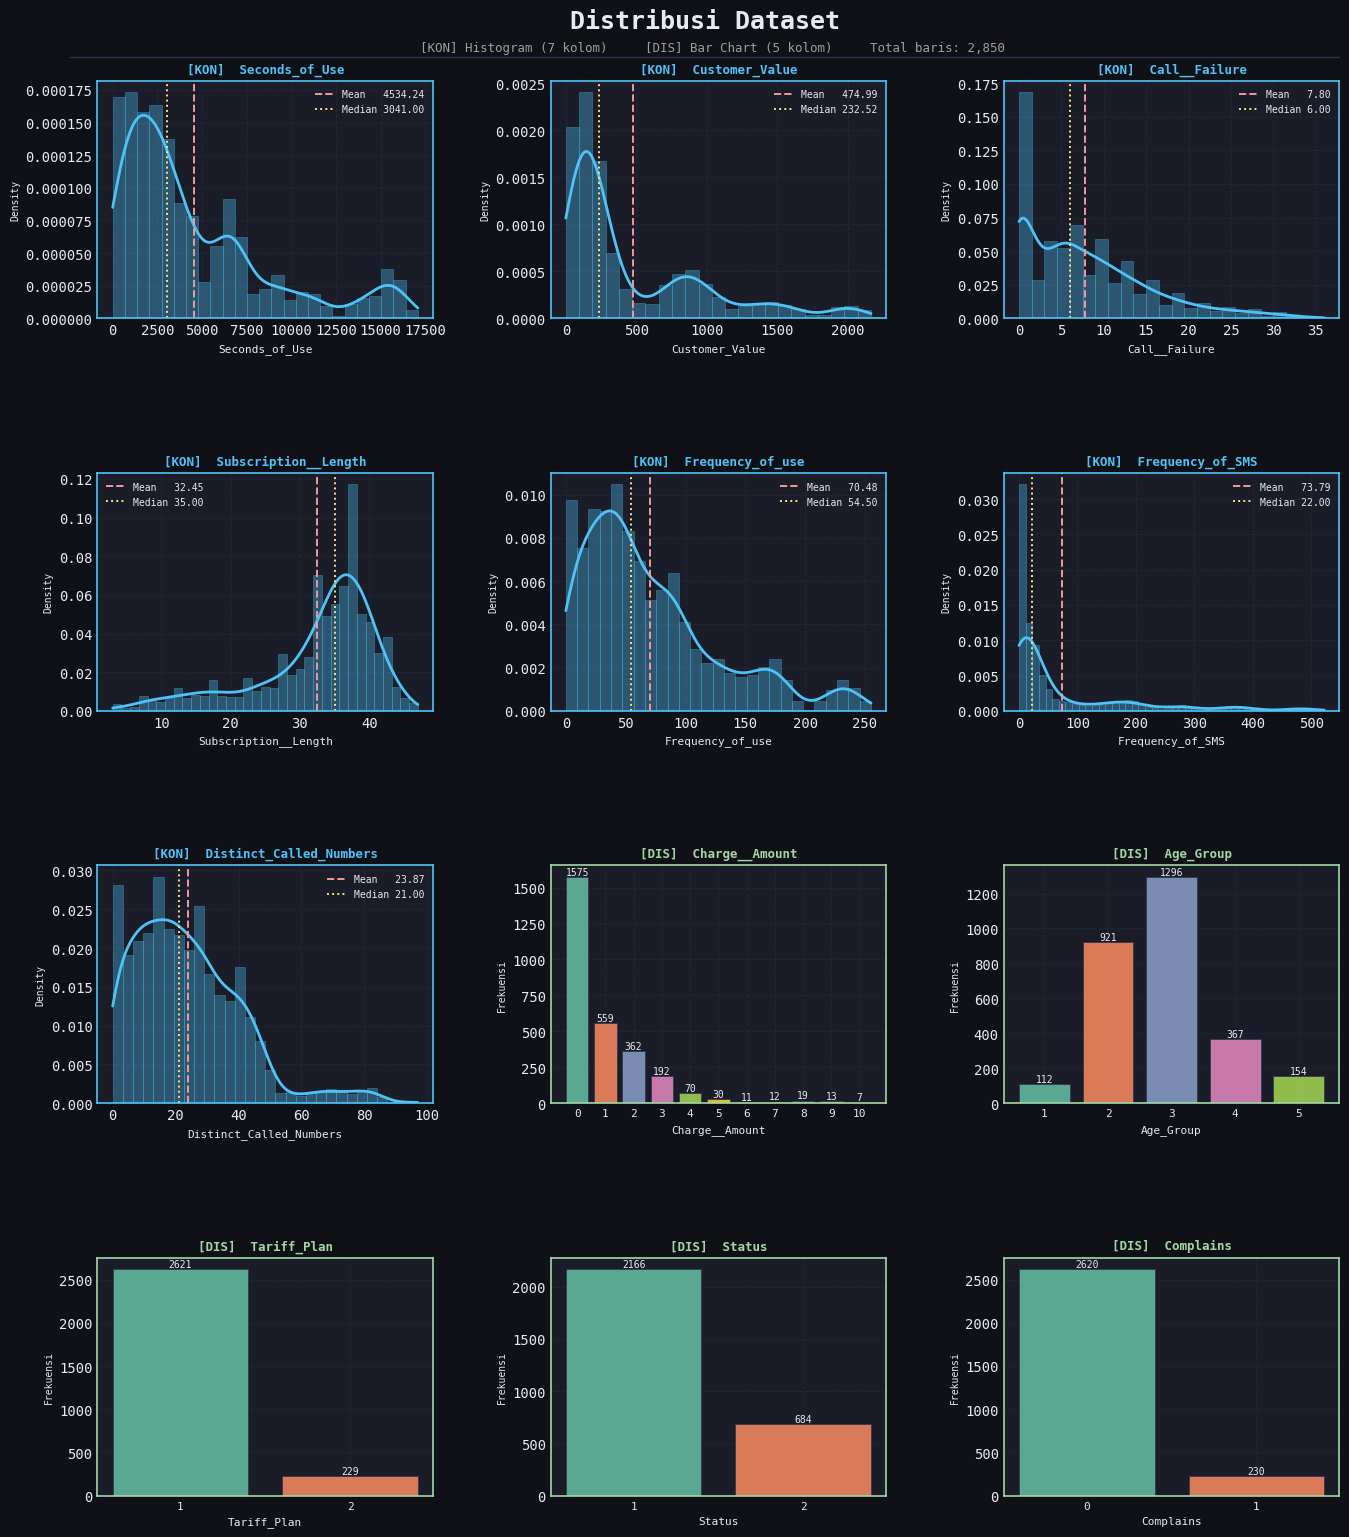

In [ ]:
# ── Definisi Kolom ────────────────────────────────────────────────────────────
def deteksi_kolom(df):
    """
    Kolom dibagi menjadi dua kelompok berdasarkan cara visualisasi
    yang paling komunikatif, bukan semata-mata definisi statistik.

    Pakai histogram + KDE : fitur dengan nilai unik banyak sehingga
                            bentuk distribusinya lebih bermakna.
    Pakai bar chart       : fitur kategorikal atau ordinal dengan
                            nilai unik sedikit sehingga frekuensi
                            tiap nilai masih bisa dibaca jelas.
    """
    pakai_histogram = [
        'Seconds_of_Use',
        'Customer_Value',
        'Call__Failure',
        'Subscription__Length',
        'Frequency_of_use',
        'Frequency_of_SMS',
        'Distinct_Called_Numbers',
    ]
    pakai_bar = [
        'Charge__Amount',
        'Age_Group',
        'Age',
        'Tariff_Plan',
        'Status',
        'Complains',
    ]
    pakai_histogram = [c for c in pakai_histogram if c in df.columns]
    pakai_bar       = [c for c in pakai_bar       if c in df.columns]
    return pakai_histogram, pakai_bar


# ── Plot Histogram + KDE ──────────────────────────────────────────────────────
def plot_kontinu(ax, series: pd.Series, accent_kontinu: str):
    data = series.dropna()
    ax.hist(data, bins="auto", color=accent_kontinu, alpha=0.35,
            edgecolor=accent_kontinu, linewidth=0.6, density=True)
    try:
        kde = gaussian_kde(data)
        xs  = np.linspace(data.min(), data.max(), 300)
        ax.plot(xs, kde(xs), color=accent_kontinu, linewidth=2)
    except Exception:
        pass
    ax.axvline(data.mean(),   color="#ef9a9a", linewidth=1.4,
               linestyle="--", label=f"Mean   {data.mean():.2f}")
    ax.axvline(data.median(), color="#ffe082", linewidth=1.4,
               linestyle=":",  label=f"Median {data.median():.2f}")
    ax.legend(fontsize=7, framealpha=0.2)
    ax.set_xlabel(series.name, fontsize=8)
    ax.set_ylabel("Density", fontsize=7)
    ax.grid(True, axis="y")


# ── Plot Bar Chart ────────────────────────────────────────────────────────────
def plot_diskrit(ax, series: pd.Series, palette_diskrit: str, text_color: str):
    vc     = series.value_counts().sort_index()
    colors = sns.color_palette(palette_diskrit, len(vc))
    bars   = ax.bar(range(len(vc)), vc.values, color=colors,
                    edgecolor="#2e3250", linewidth=0.6, alpha=0.85)
    for bar, val in zip(bars, vc.values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.5,
                str(val), ha="center", va="bottom",
                fontsize=7, color=text_color)
    ax.set_xticks(range(len(vc)))
    ax.set_xticklabels([str(v)[:12] for v in vc.index], fontsize=8)
    ax.set_xlabel(series.name, fontsize=8)
    ax.set_ylabel("Frekuensi", fontsize=7)
    ax.grid(True, axis="y")


# ── Fungsi Utama ──────────────────────────────────────────────────────────────
def visualisasi_distribusi(df: pd.DataFrame, cols_per_row: int = 3,
                            accent_kontinu: str = "#4fc3f7",
                            accent_diskrit: str = "#a5d6a7",
                            palette_diskrit: str = "Set2"):
    histogram_cols, bar_cols = deteksi_kolom(df)
    semua = ([("histogram", c) for c in histogram_cols] +
             [("bar",       c) for c in bar_cols])

    if not semua:
        print("Tidak ada kolom yang dapat divisualisasikan.")
        return

    n_plot = len(semua)
    n_rows = ceil(n_plot / cols_per_row)
    n_cols = min(n_plot, cols_per_row)
    fig_w  = n_cols * 4.5
    fig_h  = n_rows * 3.6 + 1.5

    fig = plt.figure(figsize=(fig_w, fig_h), facecolor=BG_COLOR)

    fig.text(0.5, 0.985, "Distribusi Dataset",
             ha="center", va="top", fontsize=18, fontweight="bold",
             color=TEXT_COLOR)
    fig.text(0.5, 0.965,
             f"  [KON] Histogram ({len(histogram_cols)} kolom)     "
             f"[DIS] Bar Chart ({len(bar_cols)} kolom)     "
             f"Total baris: {len(df):,}",
             ha="center", va="top", fontsize=9, color="#9e9e9e")
    fig.add_artist(
        plt.Line2D([0.03, 0.97], [0.955, 0.955],
                   transform=fig.transFigure,
                   color="#2e3250", linewidth=1)
    )

    gs = gridspec.GridSpec(
        n_rows, n_cols, figure=fig,
        top=0.94, bottom=0.05,
        left=0.05, right=0.97,
        hspace=0.65, wspace=0.35
    )

    for idx, (tipe, col) in enumerate(semua):
        r, c = divmod(idx, n_cols)
        ax   = fig.add_subplot(gs[r, c])

        border_clr = accent_kontinu if tipe == "histogram" else accent_diskrit
        for spine in ax.spines.values():
            spine.set_edgecolor(border_clr)
            spine.set_linewidth(1.2)

        ax.set_title(
            f"[{'KON' if tipe=='histogram' else 'DIS'}]  {col}",
            fontsize=9, fontweight="bold", pad=6,
            color=border_clr
        )

        if tipe == "histogram":
            plot_kontinu(ax, df[col], accent_kontinu)
        else:
            plot_diskrit(ax, df[col], palette_diskrit, TEXT_COLOR)

        n_miss = df[col].isna().sum()
        if n_miss:
            ax.annotate(f"! {n_miss} NaN", xy=(0.98, 0.96),
                        xycoords="axes fraction", ha="right", va="top",
                        fontsize=7, color="#ef9a9a")

    for idx in range(n_plot, n_rows * n_cols):
        r, c = divmod(idx, n_cols)
        fig.add_subplot(gs[r, c]).set_visible(False)

    plt.show()
    plt.close(fig)


# ── Jalankan ──────────────────────────────────────────────────────────────────
# BG_COLOR, PANEL_COLOR, TEXT_COLOR sudah aktif dari apply_dark_theme() di cell pertama
visualisasi_distribusi(df, cols_per_row=3)

### **Insight Distribusi Dataset (Univariat)**

Kolom dibagi menjadi dua kelompok berdasarkan cara visualisasi yang paling komunikatif:

1. **Histogram + KDE** digunakan untuk fitur kontinu atau fitur dengan rentang nilai unik yang banyak, sehingga bentuk distribusinya (simetris, menceng, atau bimodal) lebih bermakna untuk dianalisis. Garis **merah putus-putus** menunjukkan rata-rata (*Mean*) dan garis **kuning titik-titik** menunjukkan nilai tengah (*Median*).
2. **Bar Chart** digunakan untuk fitur kategorikal atau ordinal dengan nilai unik sedikit, sehingga frekuensi tiap nilai dapat dibaca dengan jelas untuk melihat ketimpangan kelas (*class imbalance*).

---

### **1. Fitur Numerik Kontinu (Histogram & KDE)**

**`Seconds_of_Use`, `Frequency_of_use`, dan `Frequency_of_SMS`**
Ketiga metrik aktivitas penggunaan ini menunjukkan distribusi yang sangat **menceng ke kanan (*right-skewed*)**. Terdapat puncak yang sangat besar di nilai-nilai rendah (bahkan pada `Frequency_of_SMS` puncaknya nyaris berada di angka 0). Rata-rata (*Mean*) selalu tertarik jauh lebih besar daripada *Median*. Ini mengartikan bahwa mayoritas pelanggan adalah pengguna pasif/kasual, sementara terdapat segelintir kecil pelanggan (*power users*) yang memiliki intensitas penggunaan sangat ekstrem.

**`Customer_Value`**
Distribusinya juga condong ke kanan (*right-skewed*) namun menunjukkan pola **bimodal (memiliki dua puncak)**. Puncak pertama berada di rentang nilai rendah (mendekati 0) dan puncak kedua berada di rentang nilai sekitar 500-1000. Ini mengindikasikan secara alami terdapat dua segmen pelanggan yang sangat berbeda dalam dataset ini: segmen bernilai rendah dan segmen bernilai menengah-tinggi.

**`Distinct_Called_Numbers`**
Distribusi fitur ini juga **menceng ke kanan (*right-skewed*)** dengan ekor yang memanjang mendekati angka 100, namun bentuknya sedikit lebih merata dan tidak seekstrem fitur penggunaan lainnya. Mayoritas pelanggan menghubungi sekitar 21 nomor berbeda (*Median* = 21).

**`Call__Failure`**
Bentuk distribusinya sangat menceng ke kanan. Sebagian besar pelanggan memiliki tingkat kegagalan panggilan yang sangat minim (berkumpul di angka 0-10), dan hanya sedikit pelanggan yang mengalami kegagalan panggilan tinggi di atas 20 kali.

**`Subscription__Length`**
Ini adalah satu-satunya fitur numerik yang distribusinya **menceng ke kiri (*left-skewed*)**. Puncak populasinya berada di angka yang tinggi (sekitar 30–40 bulan). Ini merupakan sinyal positif bagi bisnis bahwa mayoritas data ini berisi pelanggan lama atau loyalis, bukan pelanggan baru.

---

### **2. Fitur Kategorikal & Ordinal (Bar Chart)**

**`Complains`**
Sangat tidak seimbang (*highly imbalanced*). Hanya **230** dari 2.850 pelanggan (sekitar 8%) yang pernah mengajukan komplain. Ketimpangan ini perlu diwaspadai karena fitur dengan variansi rendah dapat berdampak pada stabilitas model prediksi.

**`Tariff_Plan`**
Didominasi secara ekstrem oleh Paket 1 (*Plan 1*) dengan **2.621 pelanggan** (92%), dibandingkan Paket 2 yang hanya diisi oleh **229 pelanggan**. Distribusi monolitik ini menunjukkan model mungkin akan kesulitan mempelajari pola perilaku pelanggan dari Paket 2.

**`Status`**
Proporsinya terbagi menjadi **2.166 pelanggan** (Status 1) dan **684 pelanggan** (Status 2). Terdapat ketimpangan, namun rasionya masih cukup sehat untuk dianalisis lebih lanjut terkait hubungannya dengan target *Churn*.

**`Age_Group` dan `Age`**
Membentuk distribusi yang menyerupai kurva normal pada demografi usia. Didominasi oleh kelompok 3 (merepresentasikan usia ~30 tahun) dengan **1.296 pelanggan**, disusul kelompok 2 (\~25 tahun) dengan **921 pelanggan**. Karena `Age` dan `Age_Group` merepresentasikan informasi yang persis sama, besar kemungkinan salah satunya bersifat redundan.

**`Charge__Amount`**
Sangat tidak seimbang dan didominasi oleh nilai 0 dengan **1.575 pelanggan** (lebih dari 50% populasi). Kategori lainnya menyusut secara eksponensial.

---

### **Kesimpulan Utama (Key Takeaways)**

Dari eksplorasi distribusi ini, terdapat tiga poin tindakan (*action items*) utama untuk langkah pemrosesan selanjutnya:

1. **Kebutuhan Transformasi Skala:** Hampir seluruh fitur penggunaan (*Usage Features*) memiliki distribusi yang menceng sangat kuat ke kanan (*skewness* tinggi). Jika pemodelan menggunakan algoritma parametrik/linier (seperti *Logistic Regression*), fitur-fitur ini wajib ditransformasi (misalnya dengan *Log Transform* atau *Box-Cox*) agar distribusinya lebih simetris. *(Catatan: Ini opsional jika menggunakan model berbasis pohon seperti CatBoost/XGBoost).*
2. **Penanganan Fitur Berisiko (Low Variance):** Fitur seperti `Tariff_Plan`, `Complains`, dan `Charge__Amount` sangat didominasi oleh satu kelas mayoritas. Fitur-fitur ini perlu dievaluasi lebih jauh melalui analisis Bivariat untuk memastikan apakah mereka memiliki daya pembeda (*predictive power*) terhadap *Churn*, atau justru hanya menjadi *noise*.
3. **Penyaringan Redundansi:** Adanya pola yang mirip pada fitur (`Age` dengan `Age_Group`, atau `Seconds_of_Use` dengan `Frequency_of_use`) harus divalidasi pada uji Korelasi Multivariat untuk mendeteksi multikolinearitas sebelum masuk ke algoritma.

## Distribusi Target

In [ ]:
churn_pct = df['Churn'].value_counts(normalize=True) * 100
print(f"Tidak Churn (0): {churn_pct[0]:.1f}%")
print(f"Churn (1):       {churn_pct[1]:.1f}%")

Tidak Churn (0): 84.4%
Churn (1):       15.6%


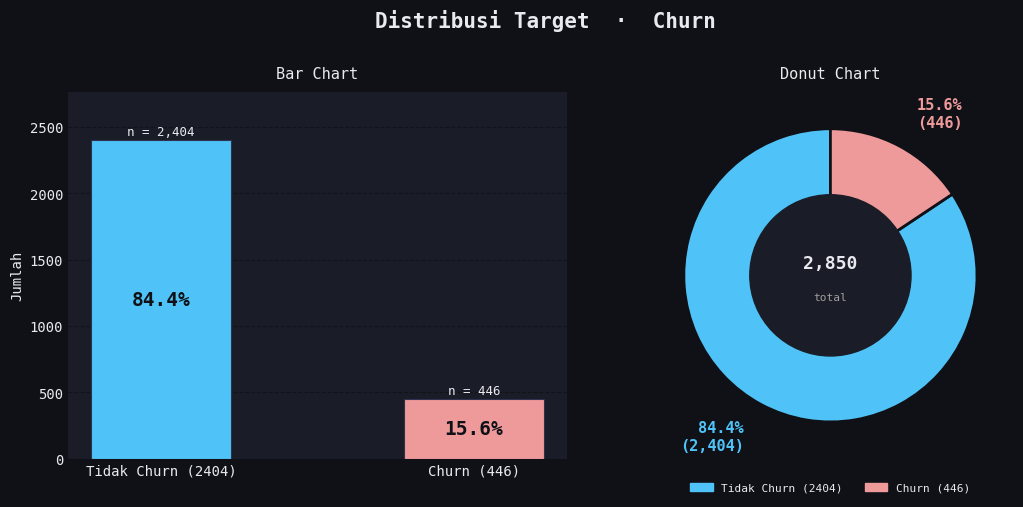

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Catatan: BG_COLOR, PANEL_COLOR, TEXT_COLOR sudah aktif dari
# apply_dark_theme() di cell pertama. TARGET = 'Churn' juga sudah didefinisikan di sana.

COLOR_0 = "#4fc3f7"   # Tidak Churn
COLOR_1 = "#ef9a9a"   # Churn

def grafik_churn(df: pd.DataFrame, target_col: str = TARGET):
    counts  = df[target_col].value_counts().sort_index()
    labels  = [f"Tidak Churn ({v})" if k == 0 else f"Churn ({v})"
               for k, v in counts.items()]
    colors  = [COLOR_0 if k == 0 else COLOR_1 for k in counts.index]
    total   = counts.sum()
    pcts    = counts / total * 100

    fig, (ax_bar, ax_pie) = plt.subplots(
        1, 2, figsize=(11, 5), facecolor=BG_COLOR
    )
    fig.suptitle(f"Distribusi Target  ·  {target_col}",
                 fontsize=15, fontweight="bold", color=TEXT_COLOR, y=1.01)

    # ── Bar Chart
    bars = ax_bar.bar(labels, counts.values, color=colors,
                      edgecolor="#2e3250", linewidth=0.8, width=0.45)

    for bar, pct, cnt in zip(bars, pcts, counts.values):
        ax_bar.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() / 2,
            f"{pct:.1f}%",
            ha="center", va="center",
            fontsize=14, fontweight="bold", color=BG_COLOR
        )
        ax_bar.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + total * 0.005,
            f"n = {cnt:,}",
            ha="center", va="bottom",
            fontsize=9, color=TEXT_COLOR
        )

    ax_bar.set_ylabel("Jumlah", fontsize=10)
    ax_bar.set_title("Bar Chart", fontsize=11, pad=10)
    ax_bar.set_ylim(0, counts.max() * 1.15)
    ax_bar.grid(True, axis="y", linestyle="--", alpha=0.3, color="#000000")
    ax_bar.grid(False, axis="x")
    ax_bar.spines[["top", "right"]].set_visible(False)

    # ── Donut Chart
    wedge_props = {"linewidth": 2, "edgecolor": BG_COLOR}
    wedges, _ = ax_pie.pie(
        counts.values,
        colors=colors,
        startangle=90,
        wedgeprops=wedge_props,
        radius=1,
    )

    for wedge, pct, cnt, lbl in zip(wedges, pcts, counts.values, labels):
        angle  = (wedge.theta1 + wedge.theta2) / 2
        x      = 1.25 * np.cos(np.radians(angle))
        y      = 1.25 * np.sin(np.radians(angle))
        ha     = "left" if x > 0 else "right"
        ax_pie.text(x, y, f"{pct:.1f}%\n({cnt:,})",
                    ha=ha, va="center",
                    fontsize=11, fontweight="bold",
                    color=wedge.get_facecolor())

    hole = plt.Circle((0, 0), 0.55, color=PANEL_COLOR)
    ax_pie.add_patch(hole)
    ax_pie.text(0, 0.08, f"{total:,}", ha="center", va="center",
                fontsize=13, fontweight="bold", color=TEXT_COLOR)
    ax_pie.text(0, -0.15, "total", ha="center", va="center",
                fontsize=8, color="#9e9e9e")

    ax_pie.set_title("Donut Chart", fontsize=11, pad=10)

    legend_patches = [
        mpatches.Patch(color=c, label=l)
        for c, l in zip(colors, labels)
    ]
    ax_pie.legend(handles=legend_patches, loc="lower center",
                  bbox_to_anchor=(0.5, -0.12), ncol=2,
                  fontsize=8, framealpha=0.15)

    plt.tight_layout()
    plt.show()
    plt.close(fig)


grafik_churn(df, target_col=TARGET)

### Distribusi Target: 'Churn'

Dari total **2.850 pelanggan** (setelah dilakukan pembersihan data untuk mencegah duplikasi dan kebocoran informasi), distribusi kelas target adalah sebagai berikut:

| Kelas | Jumlah | Persentase |
|---|---|---|
| Tidak Churn | 2.404 | 84.4% |
| Churn | 446 | 15.6% |

Dataset ini termasuk **imbalanced (tidak seimbang)** karena kelas *churn* hanya mewakili 15.6% dari total data. Artinya, untuk setiap 1 pelanggan yang *churn*, terdapat lebih dari 5 pelanggan yang tidak *churn* (rasio sekitar 1 : 5,4).

Kondisi ini umum ditemukan pada kasus *churn* di industri telekomunikasi dan wajib diperhatikan dalam pemodelan, karena algoritma standar cenderung akan bias (lebih condong memprediksi kelas mayoritas) jika tidak ditangani. Strategi penanganan yang dapat dipertimbangkan dalam tahap eksperimen mencakup teknik *SMOTE oversampling*, *random undersampling*, maupun pengaturan bobot kelas tingkat algoritma (seperti pada CatBoost melalui parameter `auto_class_weights`).

# B. Outlier & Extreme Value

## **Analisis Outlier**

### Dasar Pengelompokan

Dalam analisis outlier, pembagian fitur tidak didasarkan pada cardinality (jumlah nilai unik) seperti pada visualisasi distribusi sebelumnya, melainkan pada **apakah nilai ekstrem pada fitur tersebut secara statistik bermakna sebagai outlier**.

Ada dua pertanyaan kunci yang menentukan apakah sebuah fitur perlu dianalisis outlier-nya:

**1. Apakah nilai fitur merepresentasikan besaran yang bisa dibandingkan secara magnitude?**

Fitur seperti `Frequency_of_use` menyimpan nilai berupa jumlah penggunaan. Selisih antara nilai 10 dan 500 memiliki makna yang nyata secara kuantitatif. Nilai 500 di sini bisa jadi jauh di luar pola umum dan layak disebut outlier.

Sebaliknya, fitur seperti `Status` menyimpan nilai 1 dan 2 yang merepresentasikan kategori, bukan besaran. Nilai 2 tidak berarti "dua kali lebih besar" dari nilai 1. Tidak ada konsep nilai ekstrem di sini karena semua nilai adalah label yang valid.

**2. Apakah metode statistik berbasis jarak (IQR, Z-score) masih relevan diterapkan?**

Metode IQR bekerja dengan mengukur seberapa jauh sebuah nilai dari kuartil tengah distribusi. Ini hanya bermakna jika nilai-nilai dalam fitur memiliki urutan dan jarak yang bisa dihitung. Fitur dengan nilai kategoris atau ordinal yang terbatas tidak memenuhi syarat ini.

___

### **Pembagian Fitur**

Berdasarkan dua pertanyaan di atas, fitur dibagi menjadi dua kelompok:

#### Kelompok 1: Perlu Analisis Outlier

Fitur-fitur berikut merepresentasikan besaran kuantitatif sehingga nilai ekstrem di ujung distribusinya bermakna secara statistik dan perlu diidentifikasi:

| Fitur | Alasan |
|---|---|
| `Seconds_of_Use` | Durasi penggunaan dalam satuan detik, nilai sangat tinggi bisa jadi anomali |
| `Customer_Value` | Nilai pelanggan dalam satuan numerik, distribusi sangat skewed dengan ekor panjang |
| `Call_Failure` | Jumlah kegagalan panggilan, nilai ekstrem tinggi bisa merepresentasikan gangguan teknis tidak normal |
| `Subscription_Length` | Lama berlangganan dalam bulan, nilai di luar rentang wajar perlu dicermati |
| `Frequency_of_use` | Jumlah penggunaan layanan, meski diskrit nilainya merepresentasikan besaran yang bisa dibandingkan |
| `Frequency_of_SMS` | Jumlah SMS yang dikirim, distribusi sangat skewed dengan potensi outlier di nilai tinggi |
| `Distinct_Called_Numbers` | Jumlah nomor unik yang dihubungi, meski diskrit tetap merepresentasikan besaran kuantitatif |

Perlu diperhatikan bahwa `Frequency_of_use`, `Frequency_of_SMS`, dan `Distinct_Called_Numbers` secara teknis adalah fitur diskrit. Namun ketiganya tetap dimasukkan ke kelompok ini karena nilainya merepresentasikan besaran yang bisa diukur jaraknya, sehingga IQR masih valid dan relevan diterapkan.

#### Kelompok 2: Tidak Perlu Analisis Outlier

Fitur-fitur berikut merepresentasikan kategori atau label, sehingga tidak ada konsep nilai ekstrem yang bermakna secara statistik:

| Fitur | Alasan |
|---|---|
| `Complains` | Hanya bernilai 0 atau 1, semua nilai adalah label valid |
| `Charge_Amount` | Kode tingkatan tarif (0 sampai 10), bukan besaran kontinu |
| `Age_Group` | Label kelompok usia (1 sampai 5), nilai 5 tidak berarti lebih ekstrem dari nilai 1 |
| `Age_Binning` | Nilai hasil pengelompokan (*binning*) usia yang bersifat diskrit (misal: 15, 25, 30), bukan besaran kontinu murni |
| `Tariff_Plan` | Hanya bernilai 1 atau 2, merepresentasikan jenis paket |
| `Status` | Hanya bernilai 1 atau 2, merepresentasikan status akun |

___

### **Metode yang Digunakan**

Analisis outlier menggunakan kombinasi tiga lapis pendekatan yang saling melengkapi.

**Lapisan 1: Deteksi dengan IQR**

Outlier diidentifikasi menggunakan metode **IQR (Interquartile Range)**:

```
Batas Bawah  =  Q1  -  1.5 * IQR
Batas Atas   =  Q3  +  1.5 * IQR
```

Data yang berada di luar batas tersebut dikategorikan sebagai outlier. Batas ini berlaku sama untuk seluruh data tanpa memisahkan kelas, sehingga memungkinkan kita untuk langsung membaca **pada rentang nilai berapa** pelanggan churn dan tidak churn berada.

**Lapisan 2: Validasi dengan Chi-Square dan Odds Ratio**

Setelah outlier terdeteksi, dua metrik digunakan untuk memvalidasi apakah temuan tersebut benar-benar bermakna:

**Chi-Square + p-value** menguji apakah hubungan antara status outlier dan churn terjadi secara nyata atau hanya kebetulan. Jika p-value di bawah 0.05 maka hubungannya signifikan secara statistik.

**Odds Ratio (OR)** mengukur seberapa besar kemungkinan pelanggan yang masuk kategori outlier untuk churn dibandingkan pelanggan non-outlier. OR di atas 1 berarti outlier lebih berisiko, OR di bawah 1 berarti outlier justru lebih aman.

```
OR = (outlier & churn  x  normal & tidak churn) / (outlier & tidak churn  x  normal & churn)
```

**Lapisan 3: Kekuatan Hubungan dengan Point-Biserial Correlation**

**Point-Biserial Correlation (PBR)** mengukur seberapa kuat hubungan antara nilai numerik fitur secara keseluruhan dengan status churn.

| Nilai PBR | Kekuatan Hubungan |
|---|---|
| 0.00 sampai 0.10 | Sangat Lemah |
| 0.10 sampai 0.30 | Lemah |
| 0.30 sampai 0.50 | Sedang |
| Di atas 0.50 | Kuat |

Ketiga lapisan ini bekerja bersama: IQR menemukan outlier, Chi-Square dan OR memvalidasi apakah outlier tersebut berhubungan dengan churn, dan PBR mengukur seberapa dalam hubungan nilai fitur itu sendiri terhadap churn secara keseluruhan.

In [ ]:
cat = [
    'Complains',
    'Tariff_Plan',
    'Status',
    'Age_Group',
    'Age_Binning',
    'Charge__Amount'
]

for col in cat:
    if col in df.columns:
        df[col] = df[col].astype('category')

---
## Program: Eksplorasi Outlier dengan Batas Nilai yang Sama (IQR Global)

### Apa yang dilakukan?

Program ini mendeteksi outlier menggunakan **IQR (Interquartile Range)** yang dihitung dari **seluruh data** tanpa memisahkan kelas. Artinya batas outlier berlaku sama untuk semua pelanggan, baik yang churn maupun tidak.

Pendekatan ini dipilih sebagai langkah pertama karena memungkinkan kita untuk melihat **pada rentang nilai berapa** pelanggan churn dan tidak churn berada, menggunakan batas yang sama sebagai acuan. Ini membuat perbandingannya langsung dan konkret secara bisnis.





## **Eksekusi Analisis Outlier Otomatis (Tiga Lapis Validasi)**

### Apa yang dilakukan program ini?
Program ini melakukan pemindaian otomatis pada seluruh fitur kuantitatif untuk mendeteksi *outlier* menggunakan metode **IQR Global** (dihitung dari keseluruhan populasi data tanpa pemisahan kelas target). Setelah *outlier* terdeteksi, program langsung melakukan serangkaian uji hipotesis statistik untuk mengukur hubungan *outlier* tersebut dengan status *Churn*.

### Mengapa ini diperlukan?
Mendeteksi *outlier* secara visual (menggunakan *Boxplot*) saja tidak cukup untuk mengambil keputusan perlakuan data. Kita membutuhkan bukti matematis yang solid. Program ini dirancang untuk menjawab pertanyaan kritis: *"Apakah pelanggan yang perilakunya sangat ekstrem (outlier) memiliki kecenderungan churn yang berbeda secara signifikan dibandingkan pelanggan normal?"*

### Apa yang dihasilkan?
Untuk setiap fitur, program akan menghasilkan:
1. **Visualisasi Dasbor 3 Panel:** Terdiri dari *Strip Plot* (sebaran titik data individual), *KDE Plot* (kepadatan kurva), dan *Bar Chart* (perbandingan *Churn Rate* secara langsung).
2. **Validasi Statistik:** Mencetak metrik *p-value* (via *Chi-Square*), *Odds Ratio* (OR), dan *Point-Biserial Correlation* (PBR) beserta interpretasi kekuatannya.
3. **Kesimpulan Otomatis (Insight Badge):** Memberikan label keputusan instan (misal: `[!] Outlier lebih berisiko churn` atau `[+] Outlier lebih aman`) berdasarkan ambang batas toleransi perbedaan *churn rate* (minimal 20% deviasi dari *baseline*).
4. **Tabel Ringkasan Akhir:** Rekapitulasi seluruh metrik dari semua fitur untuk memudahkan penentuan strategi *Feature Engineering* selanjutnya.


 OUTLIER ANALYSIS: Call__Failure
  Batas bawah        : -15.50  |  Batas atas : 28.50
  Jumlah outlier     : 44 (1.5% dari data)
  Churn rate outlier : 20.5%
  Churn rate normal  : 15.6%
  Selisih            : +4.9%
  p-value            : 0.499611  (tidak signifikan)
  Odds Ratio         : 1.394
  Point-Biserial r   : 0.0033  (Sangat Lemah)
  Insight            : [!] Outlier lebih berisiko churn
------------------------------------------------------------


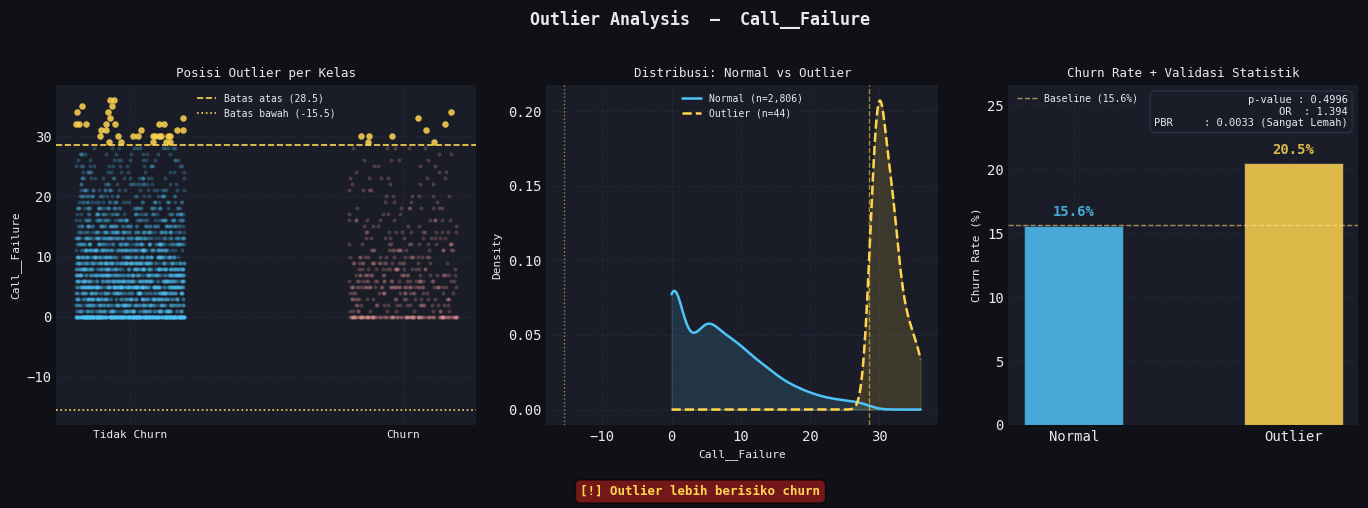


 OUTLIER ANALYSIS: Subscription__Length
  Batas bawah        : 15.50  |  Batas atas : 51.50
  Jumlah outlier     : 208 (7.3% dari data)
  Churn rate outlier : 28.4%
  Churn rate normal  : 14.6%
  Selisih            : +13.7%
  p-value            : 0.000000  (signifikan)
  Odds Ratio         : 2.307
  Point-Biserial r   : -0.0380  (Sangat Lemah)
  Insight            : [!] Outlier lebih berisiko churn
------------------------------------------------------------


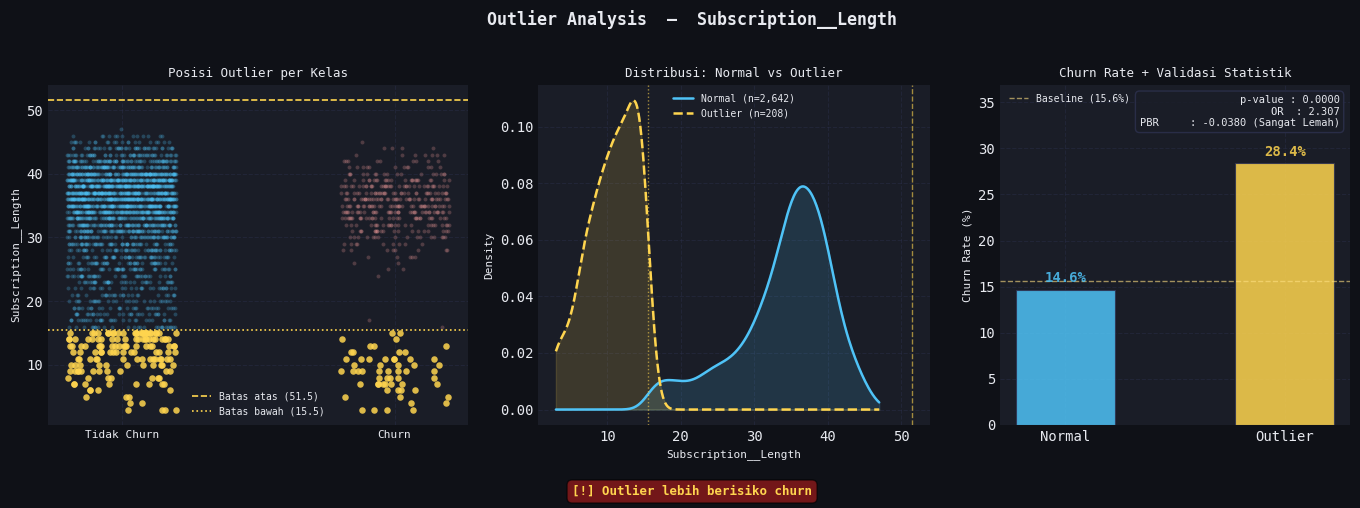


 OUTLIER ANALYSIS: Seconds_of_Use
  Batas bawah        : -6103.12  |  Batas atas : 14061.88
  Jumlah outlier     : 189 (6.6% dari data)
  Churn rate outlier : 0.0%
  Churn rate normal  : 16.8%
  Selisih            : -16.8%
  p-value            : 0.000000  (signifikan)
  Odds Ratio         : 0.000
  Point-Biserial r   : -0.2960  (Lemah)
  Insight            : [+] Outlier lebih aman
------------------------------------------------------------


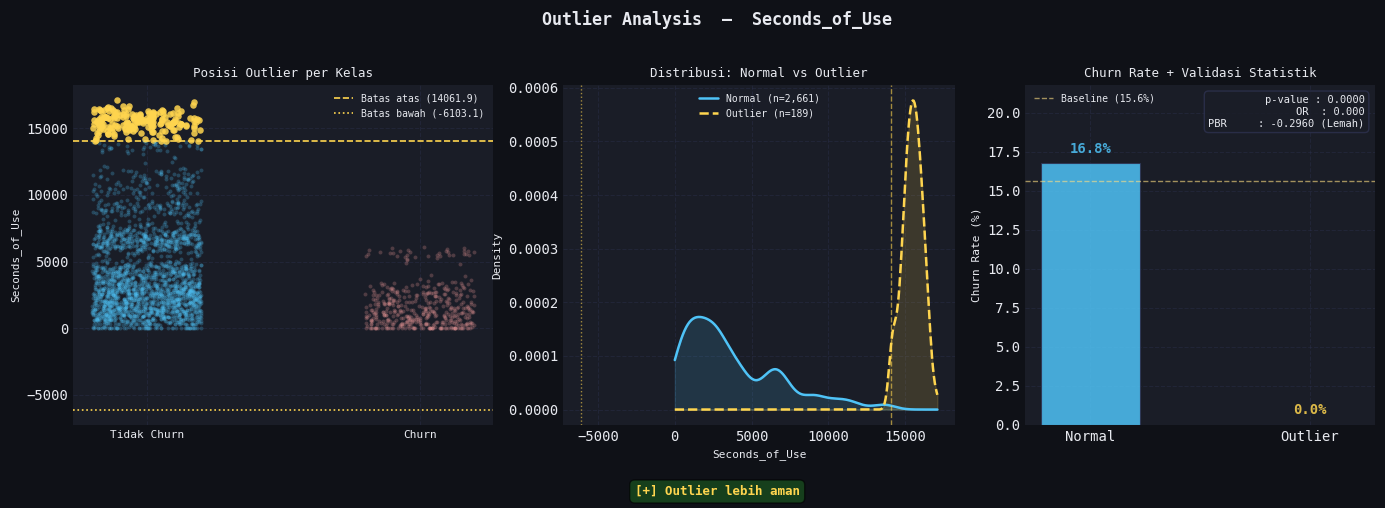


 OUTLIER ANALYSIS: Frequency_of_use
  Batas bawah        : -74.00  |  Batas atas : 198.00
  Jumlah outlier     : 118 (4.1% dari data)
  Churn rate outlier : 0.0%
  Churn rate normal  : 16.3%
  Selisih            : -16.3%
  p-value            : 0.000003  (signifikan)
  Odds Ratio         : 0.000
  Point-Biserial r   : -0.2986  (Lemah)
  Insight            : [+] Outlier lebih aman
------------------------------------------------------------


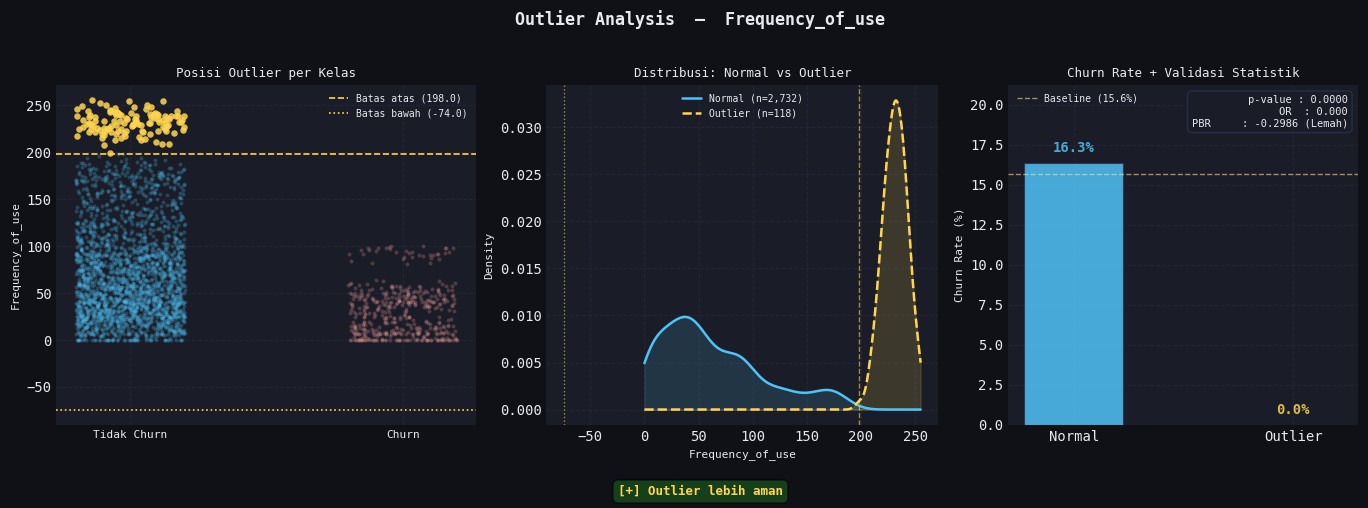


 OUTLIER ANALYSIS: Frequency_of_SMS
  Batas bawah        : -114.50  |  Batas atas : 209.50
  Jumlah outlier     : 333 (11.7% dari data)
  Churn rate outlier : 0.0%
  Churn rate normal  : 17.7%
  Selisih            : -17.7%
  p-value            : 0.000000  (signifikan)
  Odds Ratio         : 0.000
  Point-Biserial r   : -0.2189  (Lemah)
  Insight            : [+] Outlier lebih aman
------------------------------------------------------------


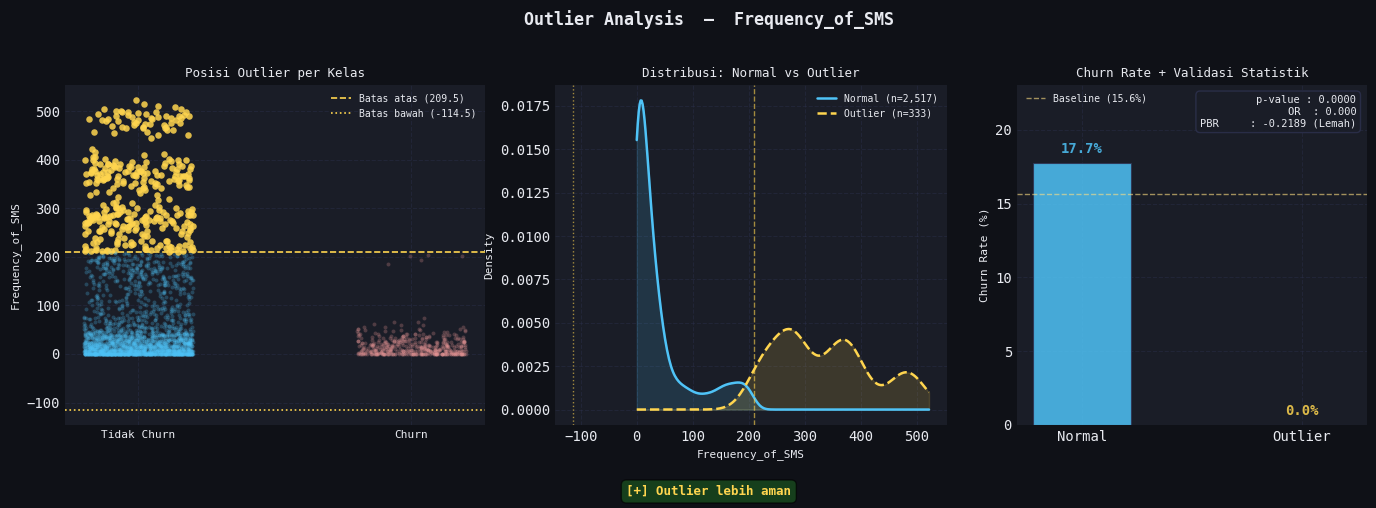


 OUTLIER ANALYSIS: Distinct_Called_Numbers
  Batas bawah        : -23.50  |  Batas atas : 68.50
  Jumlah outlier     : 82 (2.9% dari data)
  Churn rate outlier : 0.0%
  Churn rate normal  : 16.1%
  Selisih            : -16.1%
  p-value            : 0.000143  (signifikan)
  Odds Ratio         : 0.000
  Point-Biserial r   : -0.2703  (Lemah)
  Insight            : [+] Outlier lebih aman
------------------------------------------------------------


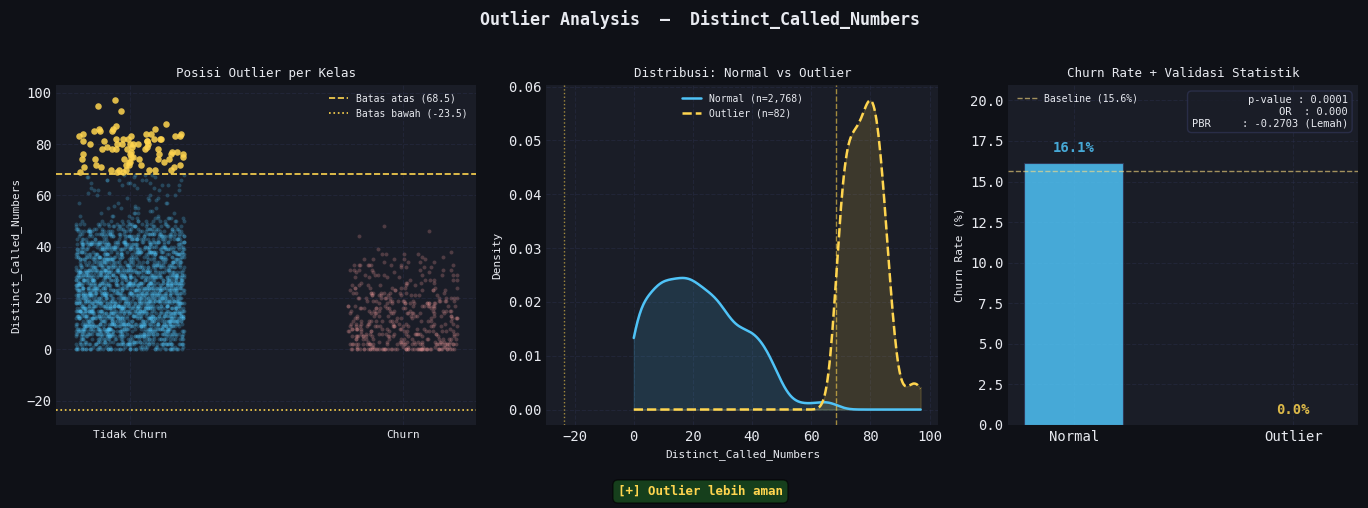


 OUTLIER ANALYSIS: Customer_Value
  Batas bawah        : -891.30  |  Batas atas : 1798.91
  Jumlah outlier     : 104 (3.6% dari data)
  Churn rate outlier : 0.0%
  Churn rate normal  : 16.2%
  Selisih            : -16.2%
  p-value            : 0.000014  (signifikan)
  Odds Ratio         : 0.000
  Point-Biserial r   : -0.2871  (Lemah)
  Insight            : [+] Outlier lebih aman
------------------------------------------------------------


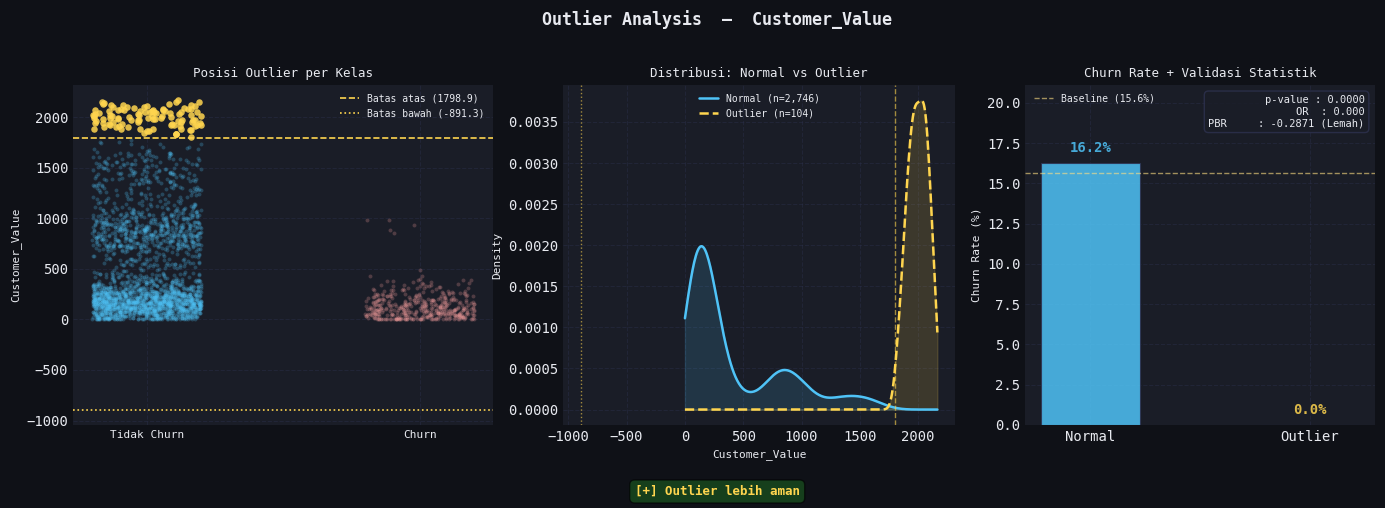


 RINGKASAN OUTLIER SELURUH FITUR
                         N Outlier  % dari Data  Batas Bawah  Batas Atas  Churn Rate Outlier (%)  Churn Rate Normal (%)  Selisih (%)   p-value  Odds Ratio     PBR  Kekuatan PBR                           Insight
Fitur                                                                                                                                                                                                             
Call__Failure                   44         1.54       -15.50       28.50                   20.45                  15.57         4.88  0.499611       1.394  0.0033  Sangat Lemah  [!] Outlier lebih berisiko churn
Subscription__Length           208         7.30        15.50       51.50                   28.37                  14.65        13.72  0.000000       2.307 -0.0380  Sangat Lemah  [!] Outlier lebih berisiko churn
Seconds_of_Use                 189         6.63     -6103.12    14061.88                    0.00                  16.76   

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Catatan: BG_COLOR, PANEL_COLOR, TEXT_COLOR, GRID_COLOR sudah aktif
# secara global dari apply_dark_theme() di cell pertama notebook.
# TARGET sudah didefinisikan sekali di cell pertama sebagai nama kolom target.

ACCENT_0    = "#4fc3f7"   # Tidak Churn
ACCENT_1    = "#ef9a9a"   # Churn
ACCENT_OUT  = "#ffd54f"   # Outlier

num_cols   = [c for c in df.columns
              if pd.api.types.is_numeric_dtype(df[c]) and c != TARGET]
label_map  = {v: lbl for v, lbl in
              zip(sorted(df[TARGET].unique()), ["Tidak Churn", "Churn"])}
baseline   = df[TARGET].mean() * 100
threshold  = baseline * 0.20

def get_outlier_mask(series):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR    = Q3 - Q1
    return (series < Q1 - 1.5*IQR) | (series > Q3 + 1.5*IQR), Q1, Q3, IQR

def hitung_odds_ratio(tabel):
    """Hitung Odds Ratio dari tabel kontingensi 2x2."""
    a = tabel.iloc[1, 1]   # outlier & churn
    b = tabel.iloc[1, 0]   # outlier & tidak churn
    c = tabel.iloc[0, 1]   # normal  & churn
    d = tabel.iloc[0, 0]   # normal  & tidak churn
    if b == 0 or c == 0:
        return np.nan
    return (a * d) / (b * c)

def interpretasi_pbr(r):
    """Interpretasi kekuatan Point-Biserial Correlation."""
    r = abs(r)
    if r >= 0.5:
        return "Kuat"
    elif r >= 0.3:
        return "Sedang"
    elif r >= 0.1:
        return "Lemah"
    return "Sangat Lemah"

# ─────────────────────────────────────────────────────────────────────────────
summary_rows = []

for name in num_cols:
    mask, Q1, Q3, IQR = get_outlier_mask(df[name])
    lower, upper      = Q1 - 1.5*IQR, Q3 + 1.5*IQR

    n_out   = mask.sum()
    n_total = len(df)

    if n_out == 0:
        print(f"[{name}] Tidak ada outlier.\n")
        continue

    df_out    = df[mask]
    df_nonout = df[~mask]
    cr_out    = df_out[TARGET].mean() * 100
    cr_nonout = df_nonout[TARGET].mean() * 100
    delta     = cr_out - cr_nonout

    tabel            = pd.crosstab(mask, df[TARGET])
    chi2, pval, _, _ = chi2_contingency(tabel)
    or_val = hitung_odds_ratio(tabel)

    valid_idx    = df[name].dropna().index
    pbr_corr, pbr_pval = pointbiserialr(
        df.loc[valid_idx, name],
        df.loc[valid_idx, TARGET]
    )
    pbr_strength = interpretasi_pbr(pbr_corr)

    insight = (
        '[!] Outlier lebih berisiko churn' if delta >  threshold else
        '[+] Outlier lebih aman'           if delta < -threshold else
        '[-] Tidak ada perbedaan signifikan'
    )

    summary_rows.append({
        'Fitur'                  : name,
        'N Outlier'              : n_out,
        '% dari Data'            : round(n_out / n_total * 100, 2),
        'Batas Bawah'            : round(lower, 2),
        'Batas Atas'             : round(upper, 2),
        'Churn Rate Outlier (%)' : round(cr_out, 2),
        'Churn Rate Normal (%)'  : round(cr_nonout, 2),
        'Selisih (%)'            : round(delta, 2),
        'p-value'                : round(pval, 6),
        'Odds Ratio'             : round(or_val, 3) if not np.isnan(or_val) else 'N/A',
        'PBR'                    : round(pbr_corr, 4),
        'Kekuatan PBR'           : pbr_strength,
        'Insight'                : insight,
    })

    print(f"\n{'='*60}")
    print(f" OUTLIER ANALYSIS: {name}")
    print(f"{'='*60}")
    print(f"  Batas bawah        : {lower:.2f}  |  Batas atas : {upper:.2f}")
    print(f"  Jumlah outlier     : {n_out} ({n_out/n_total*100:.1f}% dari data)")
    print(f"  Churn rate outlier : {cr_out:.1f}%")
    print(f"  Churn rate normal  : {cr_nonout:.1f}%")
    print(f"  Selisih            : {delta:+.1f}%")
    print(f"  p-value            : {pval:.6f}  {'(signifikan)' if pval < 0.05 else '(tidak signifikan)'}")
    print(f"  Odds Ratio         : {or_val:.3f}" if not np.isnan(or_val) else "  Odds Ratio  : N/A")
    print(f"  Point-Biserial r   : {pbr_corr:.4f}  ({pbr_strength})")
    print(f"  Insight            : {insight}")
    print(f"{'-'*60}")

    fig = plt.figure(figsize=(14, 5), facecolor=BG_COLOR)
    fig.suptitle(f"Outlier Analysis  —  {name}",
                 fontsize=12, fontweight="bold", color=TEXT_COLOR)

    ax1 = fig.add_axes([0.04, 0.15, 0.30, 0.68])
    ax2 = fig.add_axes([0.39, 0.15, 0.28, 0.68])
    ax3 = fig.add_axes([0.72, 0.15, 0.25, 0.68])

    for ax in [ax1, ax2, ax3]:
        ax.set_facecolor(PANEL_COLOR)
        for sp in ax.spines.values():
            sp.set_edgecolor(GRID_COLOR)

    jitter = np.random.uniform(-0.2, 0.2, len(df))
    colors = np.where(mask, ACCENT_OUT,
             np.where(df[TARGET] == 1, ACCENT_1, ACCENT_0))
    sizes  = np.where(mask, 22, 8)
    alphas = np.where(mask, 0.85, 0.25)

    for i, (churn, x_j, col, sz, al) in enumerate(
            zip(df[TARGET], jitter, colors, sizes, alphas)):
        ax1.scatter(churn + x_j, df[name].iloc[i],
                    c=col, s=sz, alpha=float(al), linewidths=0)

    ax1.axhline(upper, color=ACCENT_OUT, linewidth=1.2, linestyle='--',
                label=f'Batas atas ({upper:.1f})')
    ax1.axhline(lower, color=ACCENT_OUT, linewidth=1.2, linestyle=':',
                label=f'Batas bawah ({lower:.1f})')
    ax1.set_xticks(list(label_map.keys()))
    ax1.set_xticklabels(list(label_map.values()), fontsize=8)
    ax1.set_ylabel(name, fontsize=8)
    ax1.set_title("Posisi Outlier per Kelas", fontsize=9, pad=6)
    ax1.legend(fontsize=7, framealpha=0.2)
    ax1.grid(True, axis='y')

    for subset, lbl, color, ls in [
        (df_nonout[name], f"Normal (n={len(df_nonout):,})", ACCENT_0, '-'),
        (df_out[name],    f"Outlier (n={n_out:,})",         ACCENT_OUT, '--'),
    ]:
        subset = subset.dropna()
        if len(subset) > 1:
            try:
                kde = gaussian_kde(subset)
                xs  = np.linspace(df[name].min(), df[name].max(), 300)
                ax2.fill_between(xs, kde(xs), alpha=0.15, color=color)
                ax2.plot(xs, kde(xs), color=color, linewidth=1.8,
                         linestyle=ls, label=lbl)
            except Exception:
                pass

    ax2.axvline(upper, color=ACCENT_OUT, linewidth=1, linestyle='--', alpha=0.6)
    ax2.axvline(lower, color=ACCENT_OUT, linewidth=1, linestyle=':', alpha=0.6)
    ax2.set_xlabel(name, fontsize=8)
    ax2.set_ylabel("Density", fontsize=8)
    ax2.set_title("Distribusi: Normal vs Outlier", fontsize=9, pad=6)
    ax2.legend(fontsize=7, framealpha=0.2)
    ax2.grid(True, axis='y')

    bar_vals   = [cr_nonout, cr_out]
    bar_colors = [ACCENT_0, ACCENT_OUT]
    bars = ax3.bar(["Normal", "Outlier"], bar_vals, color=bar_colors,
                   edgecolor=GRID_COLOR, linewidth=0.8, width=0.45, alpha=0.85)

    for bar, val in zip(bars, bar_vals):
        ax3.text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.5,
                 f"{val:.1f}%", ha='center', va='bottom',
                 fontsize=10, fontweight='bold', color=bar.get_facecolor())

    or_text  = f"OR  : {or_val:.3f}" if not np.isnan(or_val) else "OR  : N/A"
    ax3.text(0.97, 0.97,
             f"p-value : {pval:.4f}\n{or_text}\nPBR     : {pbr_corr:.4f} ({pbr_strength})",
             transform=ax3.transAxes, ha='right', va='top',
             fontsize=7.5, color=TEXT_COLOR,
             bbox=dict(boxstyle='round,pad=0.4', facecolor=PANEL_COLOR,
                       edgecolor=GRID_COLOR, alpha=0.8))

    ax3.axhline(baseline, color="#ffe082", linewidth=1,
                linestyle='--', alpha=0.6, label=f'Baseline ({baseline:.1f}%)')
    ax3.set_ylabel("Churn Rate (%)", fontsize=8)
    ax3.set_title("Churn Rate + Validasi Statistik", fontsize=9, pad=6)
    ax3.set_ylim(0, max(max(bar_vals) * 1.3, 5))
    ax3.legend(fontsize=7, framealpha=0.2)
    ax3.grid(True, axis='y')

    badge_color = (
        "#b71c1c" if delta >  threshold else
        "#1b5e20" if delta < -threshold else
        "#37474f"
    )
    fig.text(0.5, 0.01, insight,
             ha='center', fontsize=9, fontweight='bold',
             color=ACCENT_OUT if abs(delta) > threshold else TEXT_COLOR,
             bbox=dict(boxstyle='round,pad=0.4', facecolor=badge_color, alpha=0.6))

    plt.show()
    plt.close(fig)

# ── Tabel Ringkasan ───────────────────────────────────────────────────────────
if summary_rows:
    print("\n" + "="*60)
    print(" RINGKASAN OUTLIER SELURUH FITUR")
    print("="*60)
    summary_df = pd.DataFrame(summary_rows).set_index('Fitur')
    print(summary_df.to_string())

## Hasil Program

| Fitur | Batas Bawah | Batas Atas | Churn Rate Outlier | Churn Rate Normal | Selisih | p-value | Odds Ratio | PBR |
|---|---|---|---|---|---|---|---|---|
| `Call__Failure` | -15.50 | 28.50 | 20.5% | 15.6% | +4.9% | 0.4996 | 1.394 | 0.0033 |
| `Subscription__Length` | 15.50 | 51.50 | 28.4% | 14.6% | +13.7% | 0.0000 | 2.307 | -0.0380 |
| `Seconds_of_Use` | -6,103.12 | 14,061.88 | 0.0% | 16.8% | -16.8% | 0.0000 | 0.000 | -0.2960 |
| `Frequency_of_use` | -74.00 | 198.00 | 0.0% | 16.3% | -16.3% | 0.0000 | 0.000 | -0.2986 |
| `Frequency_of_SMS` | -114.50 | 209.50 | 0.0% | 17.7% | -17.7% | 0.0000 | 0.000 | -0.2189 |
| `Distinct_Called_Numbers` | -23.50 | 68.50 | 0.0% | 16.1% | -16.1% | 0.0001 | 0.000 | -0.2703 |
| `Customer_Value` | -891.30 | 1,798.91 | 0.0% | 16.2% | -16.2% | 0.0000 | 0.000 | -0.2871 |

> \* OR = 0.000 pada fitur usage merupakan estimasi batas akibat nol kejadian churn pada grup outlier; interpretasinya tetap valid secara arah (outlier lebih aman), namun magnitude persisnya tidak presisi tanpa koreksi kontinuitas.

> \* Batas Bawah bernilai negatif (`Call__Failure`, `Seconds_of_Use`, `Frequency_of_use`, `Frequency_of_SMS`, `Distinct_Called_Numbers`, `Customer_Value`) tidak bermakna praktis karena kelima fitur ini secara alami tidak bisa bernilai negatif sehingga secara efektif tidak ada outlier bawah pada fitur-fitur tersebut. Satu-satunya batas bawah yang menghasilkan outlier nyata adalah `Subscription__Length` (15.50 bulan).

___

### Insight Bisnis

Dari hasil ini ada dua pola utama yang terbaca dengan jelas:

**Pelanggan dengan penggunaan sangat tinggi tidak churn sama sekali.** Tidak ada satupun pelanggan yang churn di antara mereka yang `Frequency_of_use` lebih dari 198 kali, `Frequency_of_SMS` lebih dari 209 kali, `Seconds_of_Use` lebih dari 14.061 detik, atau `Distinct_Called_Numbers` lebih dari 68 nomor. Keempat fitur ini juga dikonfirmasi signifikan secara statistik dengan p-value jauh di bawah 0.05. Ini adalah threshold konkret yang bisa langsung digunakan oleh tim bisnis untuk mengidentifikasi segmen pelanggan paling loyal.

**Pelanggan baru sangat rentan churn.** `Subscription__Length` dengan outlier ke bawah yaitu masa berlangganan **kurang dari 15.5 bulan** (lihat kolom Batas Bawah) memiliki churn rate 28.4% dibanding normal 14.6%, dengan Odds Ratio 2.307 yang berarti pelanggan baru **2.3 kali lebih mungkin churn**. p-value 0.000 mengkonfirmasi temuan ini bukan kebetulan.

___

### Catatan dari Metrik Validasi

**`Call__Failure`** meskipun selisih churn rate-nya +4.9% dan insight awal menyebut outlier berisiko, p-value-nya **0.4996 (tidak signifikan)** dan PBR hanya **0.0033 (Sangat Lemah)**. Artinya temuan ini kemungkinan besar hanya kebetulan dan tidak bisa dijadikan dasar keputusan.

**`Subscription__Length`** meski terbukti signifikan dan OR-nya kuat, nilai PBR-nya hanya **-0.038 (Sangat Lemah)**. Ini menunjukkan bahwa hubungan antara nilai fitur secara keseluruhan dengan churn memang lemah, tapi outlier-nya secara spesifik tetap bermakna. Artinya bukan semua rentang nilai `Subscription__Length` yang berpengaruh, melainkan hanya nilai-nilai ekstrem di ujung distribusinya (di bawah 15.5 bulan).

**Fitur usage** (`Seconds_of_Use`, `Frequency_of_use`, `Frequency_of_SMS`, `Distinct_Called_Numbers`, `Customer_Value`) semuanya memiliki PBR negatif di kisaran -0.22 sampai -0.30 (Lemah). Tanda negatif berarti semakin tinggi nilai fitur, semakin kecil kemungkinan pelanggan untuk churn. Meski kekuatannya tergolong lemah, arahnya konsisten di semua fitur usage dan dikonfirmasi signifikan secara statistik.

___

### Keterbatasan

Karena batas IQR dihitung dari seluruh data tanpa memisahkan kelas, hasilnya masih condong ke distribusi kelas mayoritas yaitu Non-Churn sebesar 84.4%. Temuan seperti churn rate 0% pada fitur usage sudah dikonfirmasi signifikan lewat p-value, namun tetap perlu diinterpretasikan dengan hati-hati mengingat ketidakseimbangan kelas yang cukup besar.

# C. Penanganan Outlier


## **Interpretasi Hasil Outlier per Fitur**

Setiap fitur diinterpretasikan menggunakan tiga metrik secara bersamaan:

**OR (Odds Ratio)** melihat dari sudut pandang grup outlier itu sendiri, seberapa besar kemungkinan outlier untuk churn dibanding non-outlier.

**p-value** mengkonfirmasi apakah temuan OR tersebut nyata atau hanya kebetulan akibat sampel yang kecil.

**PBR (Point-Biserial Correlation)** melihat seluruh rentang nilai fitur dari ujung ke ujung, apakah ada tren hubungan yang konsisten dengan churn secara keseluruhan.

___

### `Call__Failure`

```
OR      : 1.394   PBR : 0.0033   p-value : 0.4996
```

**OR** mengatakan outlier `Call__Failure` yaitu pelanggan dengan kegagalan panggilan lebih dari 28 kali, **39% lebih mungkin churn** dibanding yang bukan outlier. Angka ini terlihat cukup besar.

**p-value** 0.4996 mengatakan bahwa perbedaan tersebut **hampir pasti hanya kebetulan**. Hanya ada 44 outlier dari 2.850 data (1.5%), sampel yang terlalu kecil untuk menghasilkan pola yang stabil.

**PBR** 0.0033 yang hampir nol mengkonfirmasi bahwa di seluruh rentang nilai `Call__Failure`, tidak ada tren yang konsisten antara jumlah kegagalan panggilan dengan kemungkinan churn.

Ketiganya menunjuk ke arah yang sama. Call__Failure tidak membawa sinyal bermakna terhadap target churn. Karena bukan merupakan noise/error, nilai outlier ini tetap **dipertahankan** apa adanya (tidak di-drop / tidak di-cap), namun disadari bahwa fitur ini kemungkinan tidak akan menjadi prediktor utama dalam model pemelajaran mesin nanti.
___

### `Subscription__Length`

```
OR      : 2.307   PBR : -0.0380   p-value : 0.0000
```

**OR** 2.307 mengatakan pelanggan dengan masa berlangganan di luar rentang normal, terutama yang sangat pendek di bawah 15.5 bulan, **2.3 kali lebih mungkin churn** dibanding pelanggan dengan masa berlangganan normal.

**p-value** 0.0000 mengkonfirmasi bahwa perbedaan ini **bukan kebetulan**. Dengan 208 outlier dan selisih churn rate +13.7%, pola ini cukup konsisten untuk dipercaya.

**PBR** -0.038 tergolong sangat lemah, yang berarti secara keseluruhan tidak ada tren linear yang kuat antara lama berlangganan dengan churn. Ini masuk akal karena bukan seluruh rentang nilai yang berpengaruh, melainkan **hanya nilai-nilai ekstrem di ujung bawah distribusinya** yang sangat berisiko.

Kesimpulannya OR kuat dan terkonfirmasi signifikan, meski PBR lemah. Outlier ini membawa sinyal nyata sehingga **dipertahankan**.

___

### `Seconds_of_Use`

```
OR      : 0.000   PBR : -0.2960   p-value : 0.0000
```

**OR** 0.000 berarti di antara 189 pelanggan yang penggunaan detiknya sangat tinggi di atas 14.061 detik, **tidak ada satupun yang churn**. Ini bukan angka yang ambigu, melainkan sinyal yang sangat tegas.

**p-value** 0.0000 mengkonfirmasi bahwa ketiadaan churn di grup outlier ini **bukan kebetulan** dan bermakna secara statistik.

**PBR** -0.296 menambahkan konteks yang penting. Tanda negatif berarti **semakin tinggi durasi penggunaan, semakin kecil kemungkinan churn** secara konsisten di seluruh rentang nilai, bukan hanya di grup outlier. Kekuatannya tergolong lemah tapi arahnya jelas dan konsisten.

Ketiga metrik sepakat. Pelanggan dengan penggunaan sangat tinggi adalah segmen paling loyal dan outlier-nya **dipertahankan**.

___

### `Frequency_of_use`

```
OR      : 0.000   PBR : -0.2986   p-value : 0.0000
```

**OR** 0.000 berarti dari 118 pelanggan yang frekuensi penggunaannya sangat tinggi di atas 198 kali, **tidak ada satupun yang churn**. Pola yang sama persis dengan `Seconds_of_Use`.

**p-value** 0.0000 mengkonfirmasi temuan ini **signifikan secara statistik**.

**PBR** -0.2986 adalah yang terbesar dalam hal nilai absolut di antara semua fitur, menunjukkan bahwa tren semakin sering digunakan semakin kecil kemungkinan churn berlaku **secara konsisten di seluruh rentang nilai**, bukan hanya di grup outlier.

Ini adalah fitur usage dengan sinyal paling kuat dan konsisten. Outlier-nya **dipertahankan**.

___

### `Frequency_of_SMS`

```
OR      : 0.000   PBR : -0.2189   p-value : 0.0000
```

**OR** 0.000 berarti dari 333 pelanggan yang frekuensi SMS-nya sangat tinggi di atas 209 kali, **tidak ada satupun yang churn**. Ini juga kelompok outlier terbesar yaitu 11.7% dari total data.

**p-value** 0.0000 mengkonfirmasi pola ini **bukan kebetulan**.

**PBR** -0.2189 menunjukkan tren negatif yang konsisten, meski sedikit lebih lemah dibanding `Frequency_of_use`. Pelanggan yang lebih aktif menggunakan SMS secara umum lebih kecil kemungkinannya untuk churn.

Pola yang konsisten dengan fitur usage lainnya. Outlier-nya **dipertahankan**.

___

### `Distinct_Called_Numbers`

```
OR      : 0.000   PBR : -0.2703   p-value : 0.0001
```

**OR** 0.000 berarti dari 82 pelanggan yang menghubungi lebih dari 68 nomor berbeda, **tidak ada satupun yang churn**.

**p-value** 0.0001 mengkonfirmasi temuan ini **signifikan**, meski sedikit lebih tinggi dibanding fitur usage lainnya karena jumlah outlier-nya lebih kecil yaitu hanya 82 orang.

**PBR** -0.2703 menunjukkan tren negatif yang cukup konsisten. Pelanggan yang menghubungi lebih banyak nomor berbeda secara umum lebih kecil kemungkinannya untuk churn, yang masuk akal karena menunjukkan keterlibatan aktif dengan layanan.

Pola konsisten dan terkonfirmasi signifikan. Outlier-nya **dipertahankan**.

___

### `Customer_Value`

```
OR      : 0.000   PBR : -0.2871   p-value : 0.0000
```

**OR** 0.000 berarti dari 104 pelanggan dengan nilai pelanggan sangat tinggi di atas 1.798, **tidak ada satupun yang churn**.

**p-value** 0.0000 mengkonfirmasi temuan ini **signifikan secara statistik**.

**PBR** -0.2871 menunjukkan bahwa tren semakin tinggi nilai pelanggan semakin kecil kemungkinan churn berlaku **secara konsisten di seluruh rentang nilai**. Ini sangat masuk akal secara bisnis karena pelanggan bernilai tinggi biasanya adalah pelanggan yang paling aktif menggunakan layanan, konsisten dengan pola yang ditemukan di fitur usage lainnya.

Ketiga metrik sepakat dan konsisten. Outlier-nya **dipertahankan**.

___

### Ringkasan Interpretasi

| Fitur | OR | p-value | PBR | Kesimpulan |
|---|---|---|---|---|
| `Call__Failure` | 1.394 | 0.4996 | 0.0033 | Tidak bermakna, kemungkinan kebetulan |
| `Subscription__Length` | 2.307 | 0.0000 | -0.0380 | Bermakna, outlier bawah sangat berisiko |
| `Seconds_of_Use` | 0.000 | 0.0000 | -0.2960 | Bermakna, outlier atas sangat loyal |
| `Frequency_of_use` | 0.000 | 0.0000 | -0.2986 | Bermakna, sinyal loyalitas terkuat |
| `Frequency_of_SMS` | 0.000 | 0.0000 | -0.2189 | Bermakna, outlier atas sangat loyal |
| `Distinct_Called_Numbers` | 0.000 | 0.0001 | -0.2703 | Bermakna, outlier atas sangat loyal |
| `Customer_Value` | 0.000 | 0.0000 | -0.2871 | Bermakna, konsisten dengan fitur usage |

## Deteksi Overlap Antar Data Outlier

In [ ]:
# 1. Tentukan kondisi outlier berdasarkan batas atas dari tabel Anda
outlier_sec  = df['Seconds_of_Use'] > 14061.88
outlier_freq = df['Frequency_of_use'] > 198.00
outlier_sms  = df['Frequency_of_SMS'] > 209.50
outlier_dcn  = df['Distinct_Called_Numbers'] > 68.50
outlier_cv   = df['Customer_Value'] > 1798.91

# 2. Masukkan fitur-fitur yang akan dibuang ke dalam dictionary
kandidat_fitur_overlap = {
    'Frequency_of_use': outlier_freq,
    'Frequency_of_SMS': outlier_sms,
    'Distinct_Called_Numbers': outlier_dcn,
    'Customer_Value': outlier_cv
}

print("============================================================")
print("  BUKTI IRISAN (OVERLAP) OUTLIER KLASTER PEMAKAIAN")
print("  Representasi Utama: Seconds_of_Use")
print("============================================================\n")

# 3. Looping untuk menghitung overlap masing-masing fitur
for nama_fitur, kondisi_outlier in kandidat_fitur_overlap.items():
    total_outlier_fitur_ini = df[kondisi_outlier].shape[0]

    # Hitung berapa orang yang menjadi outlier di fitur ini DAN JUGA di Seconds_of_Use
    irisan = df[outlier_sec & kondisi_outlier].shape[0]

    # Hitung persentase
    persentase_overlap = (irisan / total_outlier_fitur_ini) * 100 if total_outlier_fitur_ini > 0 else 0

    print(f"Fitur: {nama_fitur}")
    print(f" - Total Outlier        : {total_outlier_fitur_ini} orang")
    print(f" - Yang JUGA outlier di Seconds_of_Use : {irisan} orang")
    print(f" - Tingkat Overlap      : {persentase_overlap:.1f}%\n")

  BUKTI IRISAN (OVERLAP) OUTLIER KLASTER PEMAKAIAN
  Representasi Utama: Seconds_of_Use

Fitur: Frequency_of_use
 - Total Outlier        : 118 orang
 - Yang JUGA outlier di Seconds_of_Use : 118 orang
 - Tingkat Overlap      : 100.0%

Fitur: Frequency_of_SMS
 - Total Outlier        : 333 orang
 - Yang JUGA outlier di Seconds_of_Use : 0 orang
 - Tingkat Overlap      : 0.0%

Fitur: Distinct_Called_Numbers
 - Total Outlier        : 82 orang
 - Yang JUGA outlier di Seconds_of_Use : 56 orang
 - Tingkat Overlap      : 68.3%

Fitur: Customer_Value
 - Total Outlier        : 104 orang
 - Yang JUGA outlier di Seconds_of_Use : 0 orang
 - Tingkat Overlap      : 0.0%



In [ ]:
# 1. Tentukan kondisi outlier berdasarkan batas atas
outlier_sms = df['Frequency_of_SMS'] > 209.50
outlier_cv  = df['Customer_Value'] > 1798.91

# 2. Hitung total outlier masing-masing
total_sms = df[outlier_sms].shape[0]
total_cv  = df[outlier_cv].shape[0]

# 3. Hitung irisan (orang yang merupakan outlier di KEDUANYA)
irisan_sms_cv = df[outlier_sms & outlier_cv].shape[0]

# 4. Hitung persentase overlap terhadap masing-masing populasi
persentase_dari_sms = (irisan_sms_cv / total_sms) * 100 if total_sms > 0 else 0
persentase_dari_cv  = (irisan_sms_cv / total_cv) * 100 if total_cv > 0 else 0

print("============================================================")
print("  BUKTI IRISAN: Frequency_of_SMS vs Customer_Value")
print("============================================================\n")

print(f"Total Outlier Frequency_of_SMS : {total_sms} orang")
print(f"Total Outlier Customer_Value   : {total_cv} orang\n")

print(f"Jumlah orang yang beririsan (Outlier di keduanya): {irisan_sms_cv} orang\n")

print(f"Artinya:")
print(f" - {persentase_dari_cv:.1f}% outlier Customer_Value adalah outlier SMS.")
print(f" - {persentase_dari_sms:.1f}% outlier SMS adalah outlier Customer_Value.")
print("\n============================================================")

  BUKTI IRISAN: Frequency_of_SMS vs Customer_Value

Total Outlier Frequency_of_SMS : 333 orang
Total Outlier Customer_Value   : 104 orang

Jumlah orang yang beririsan (Outlier di keduanya): 104 orang

Artinya:
 - 100.0% outlier Customer_Value adalah outlier SMS.
 - 31.2% outlier SMS adalah outlier Customer_Value.



### Kesimpulan Penanganan Outlier

Berdasarkan hasil analisis, kita mengambil keputusan strategis untuk **TIDAK MENGHAPUS** baris maupun kolom apa pun. Semua fitur asli dipertahankan karena setiap rentang data (baik normal maupun ekstrem) membawa sinyal prediktif yang berharga.

Sebagai gantinya, kita melakukan **Supervised Feature Engineering** dengan menambahkan fitur *flagging* untuk memperkuat sinyal dari kelompok ekstrem agar lebih mudah ditangkap oleh model.

| Fitur Asli | Aksi Kolom Asli | Keputusan Feature Engineering | Alasan |
|---|---|---|---|
| `Subscription__Length` | **Pertahankan** | Buat *Flag* Merah | Sinyal risiko *churn* sangat kuat pada *outlier* (<15.50 bulan). |
| `Seconds_of_Use` | **Pertahankan** | Buat *Flag* Hijau 1 (Call) | *Outlier* 100% loyal. Mewakili kekuatan sinyal klaster panggilan. |
| `Distinct_Called_Numbers` | **Pertahankan** | Gabung ke *Flag* Hijau 1 | *Outlier* digabung dengan `Seconds_of_Use` untuk mengamankan 26 pelanggan loyal unik. |
| `Frequency_of_use` | **Pertahankan** | Tidak dibuatkan *flag* khusus | *Outlier*-nya sudah terwakili 100% oleh *flag* `Seconds_of_Use`. Kolom asli tetap dipertahankan untuk analisis rentang normal. |
| `Frequency_of_SMS` | **Pertahankan** | Buat *Flag* Hijau 2 (SMS) | Sinyal loyalitas 333 *outlier*-nya sangat kuat dan tidak beririsan dengan klaster panggilan. |
| `Customer_Value` | **Pertahankan** | Tidak dibuatkan *flag* khusus | *Outlier*-nya sudah terwakili 100% oleh *flag* SMS. Kolom asli tetap dipertahankan. |
| `Call__Failure` | **Pertahankan** | Tidak diapa-apakan | Dibiarkan natural. P-value *outlier*-nya tidak signifikan secara bivariat, tidak perlu direkayasa. |

___

### Catatan Penting:

> Tidak ada data yang perlu di-Winsorize (capping) ataupun dihapus (baik penghapusan baris maupun kolom). Mayoritas outlier yang ditemukan terbukti bermakna secara statistik, baik sebagai sinyal risiko kuat maupun indikator loyalitas absolut. Untuk fitur seperti `Call__Failure` yang p-value-nya tergolong tidak signifikan secara bivariat, data tetap dipertahankan secara natural. Menghapus baris outlier tersebut akan merusak integritas data pelanggan yang sah, sementara memotong nilainya (capping) berisiko menghilangkan sinyal prediktif tersembunyi yang mungkin baru muncul ketika fitur ini berinteraksi dengan fitur lain secara multivariat.

> Keputusan mempertahankan seluruh data (termasuk outlier) dalam bentuk aslinya ini sangat direkomendasikan dan didukung oleh rencana penggunaan model akhir berbasis pohon (Tree-Based Models) seperti CatBoost, XGBoost, atau Random Forest di tahap pemodelan nanti. Algoritma-algoritma tersebut secara alami kebal (robust) terhadap variansi nilai ekstrem, sehingga kehadiran outlier dan fitur aslinya justru akan memperkaya pembelajaran model tanpa mendistorsi prediksinya.


# **FASE 3: Feature Relationship Analysis**

# A. Bivariate Analysis: Hubungan Setiap Fitur terhadap Churn


 FEATURE: Call__Failure 
                 Count   Mean  Median    Std  Min  Max
Churn                                                 
0 — Tidak Churn   2404  7.792     6.0  7.223    0   36
1 — Churn          446  7.859     6.0  7.869    0   34
--------------------------------------------------


/tmp/ipykernel_4650/1782804756.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


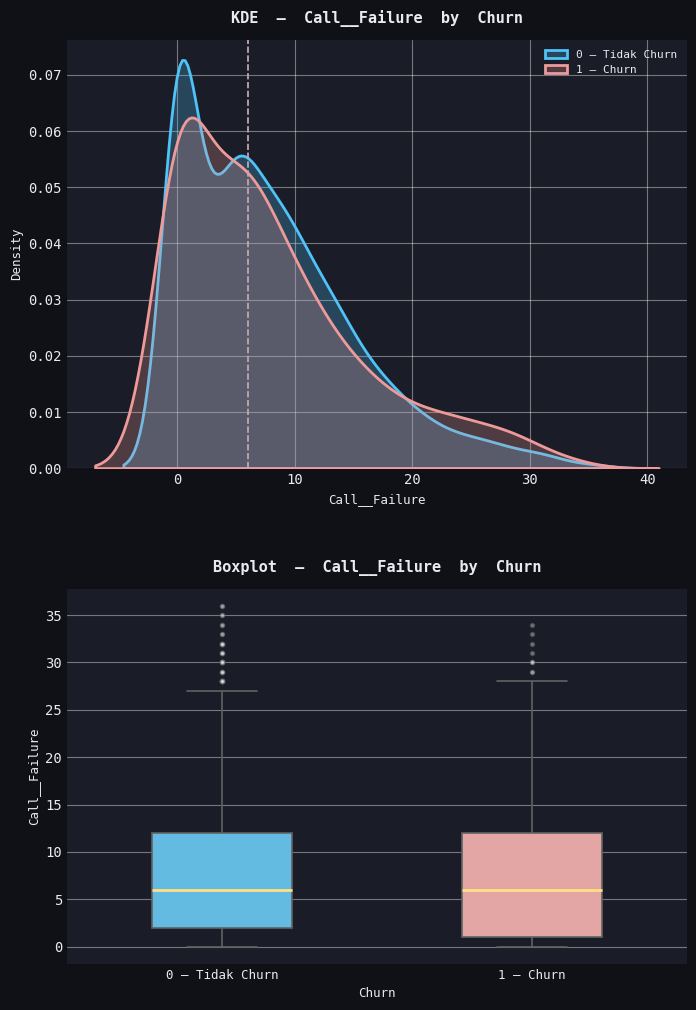


 FEATURE: Complains 
           count  Churn_Count  Churn_Rate (%)  Contribution_to_Total_Churn (%)
Complains                                                                     
0           2620          256        9.770992                        57.399103
1            230          190       82.608696                        42.600897
--------------------------------------------------


/tmp/ipykernel_4650/1782804756.py:106: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(name)[TARGET]


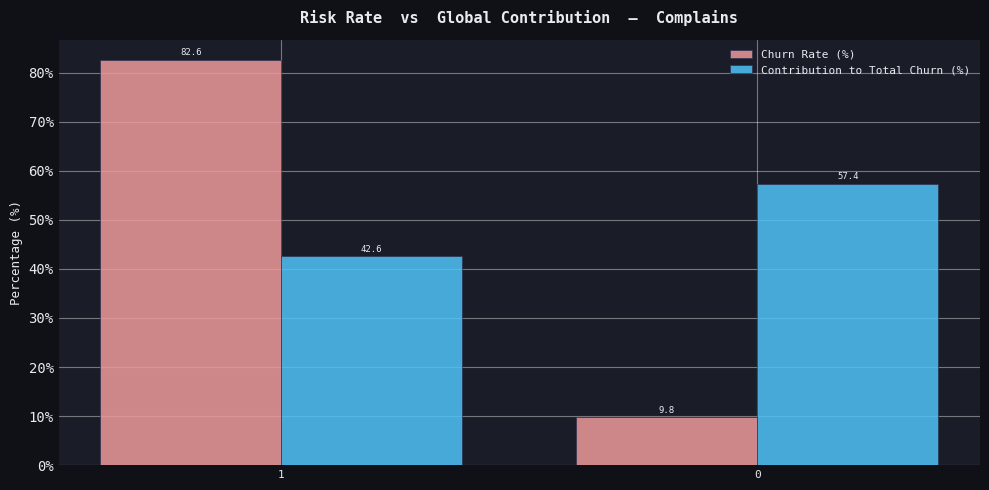


 FEATURE: Subscription__Length 
                 Count    Mean  Median    Std  Min  Max
Churn                                                  
0 — Tidak Churn   2404  32.596    35.0  8.508    3   47
1 — Churn          446  31.684    35.0  9.776    3   45
--------------------------------------------------


/tmp/ipykernel_4650/1782804756.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


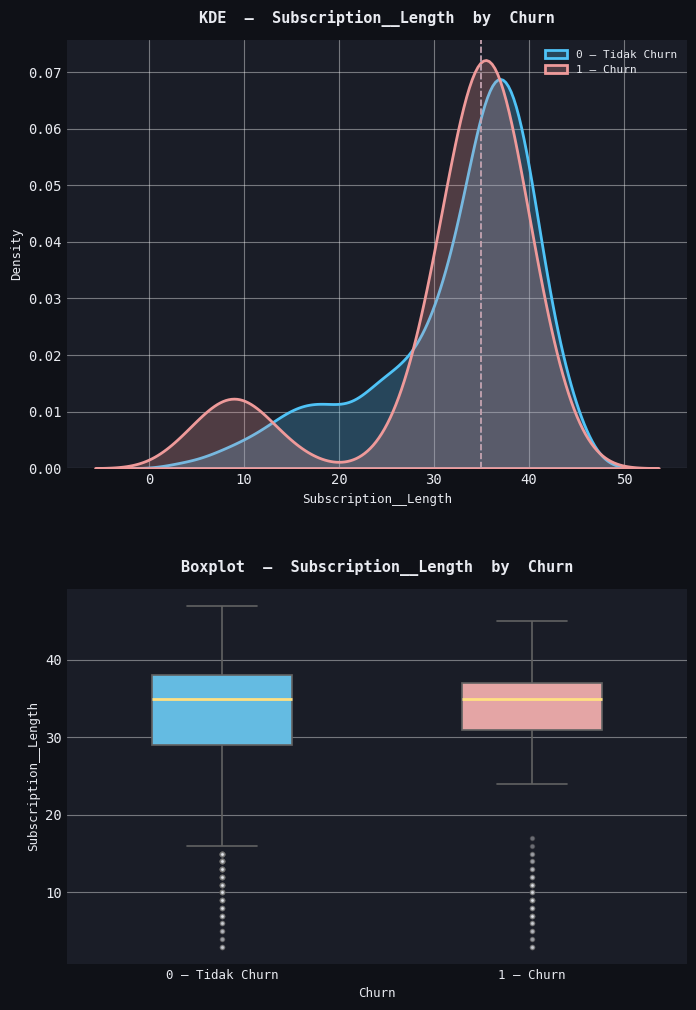


 FEATURE: Charge__Amount 
                count  Churn_Count  Churn_Rate (%)  \
Charge__Amount                                       
0                1575          374       23.746032   
1                 559           42        7.513417   
2                 362           22        6.077348   
3                 192            7        3.645833   
4                  70            1        1.428571   
5                  30            0        0.000000   
6                  11            0        0.000000   
7                  12            0        0.000000   
8                  19            0        0.000000   
9                  13            0        0.000000   
10                  7            0        0.000000   

                Contribution_to_Total_Churn (%)  
Charge__Amount                                   
0                                     83.856502  
1                                      9.417040  
2                                      4.932735  
3                   

/tmp/ipykernel_4650/1782804756.py:106: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(name)[TARGET]


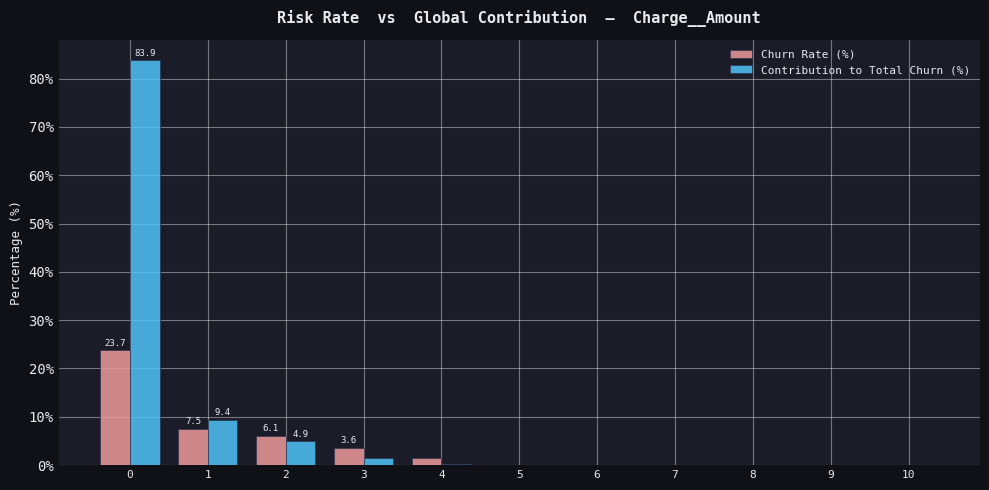


 FEATURE: Seconds_of_Use 
                 Count      Mean  Median       Std  Min    Max
Churn                                                         
0 — Tidak Churn   2404  5069.588  3596.5  4317.853    0  17090
1 — Churn          446  1648.661  1256.5  1532.911    0   6123
--------------------------------------------------


/tmp/ipykernel_4650/1782804756.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


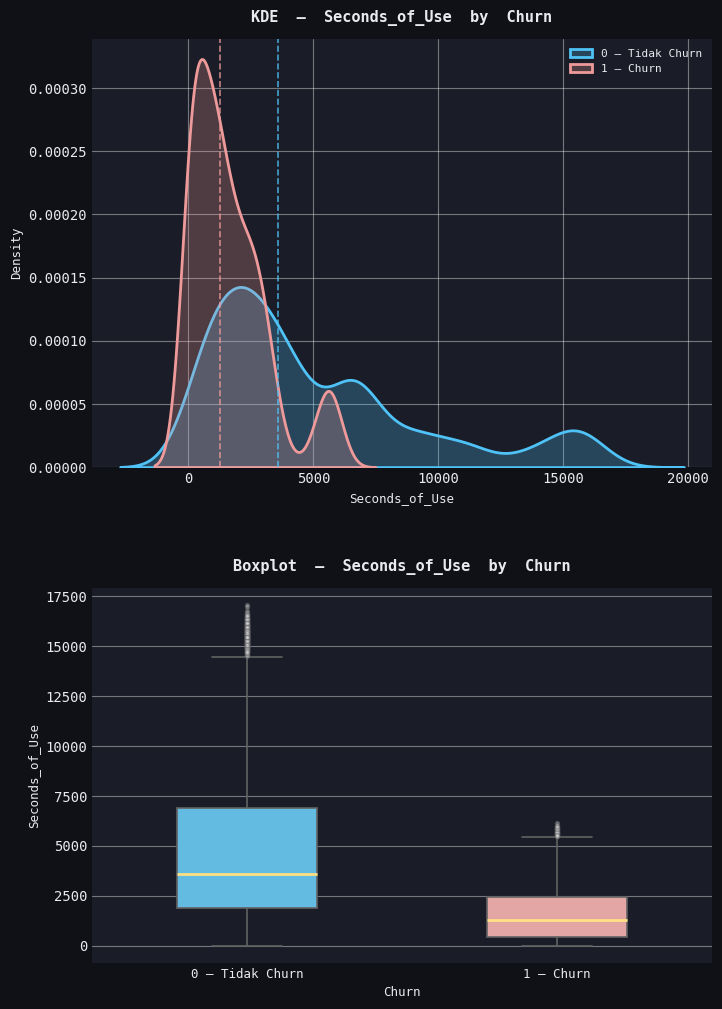


 FEATURE: Frequency_of_use 
                 Count    Mean  Median     Std  Min  Max
Churn                                                   
0 — Tidak Churn   2404  77.866    64.0  58.584    0  255
1 — Churn          446  30.697    29.0  26.091    0  100
--------------------------------------------------


/tmp/ipykernel_4650/1782804756.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


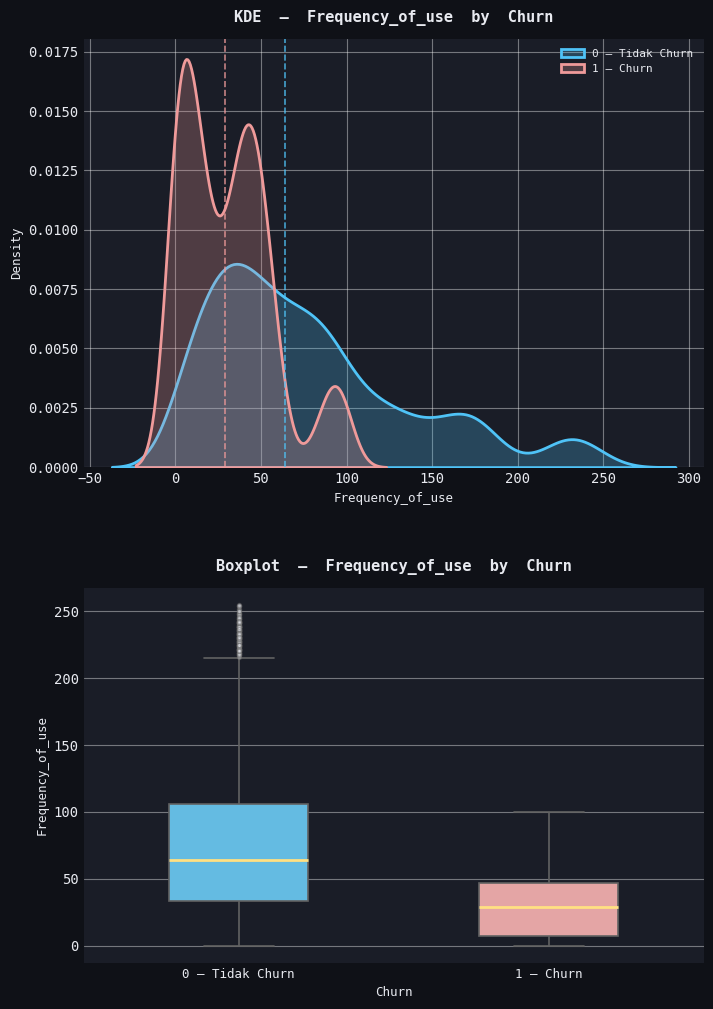


 FEATURE: Frequency_of_SMS 
                 Count    Mean  Median      Std  Min  Max
Churn                                                    
0 — Tidak Churn   2404  84.354    26.0  118.599    0  522
1 — Churn          446  16.850    11.0   24.331    0  204
--------------------------------------------------


/tmp/ipykernel_4650/1782804756.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


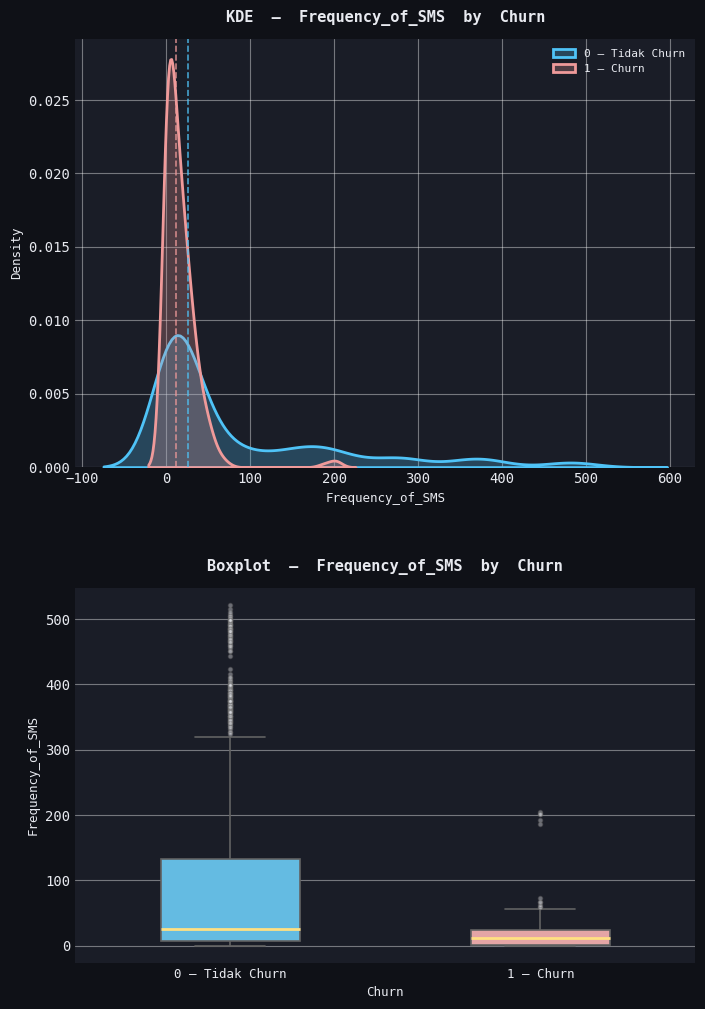


 FEATURE: Distinct_Called_Numbers 
                 Count    Mean  Median     Std  Min  Max
Churn                                                   
0 — Tidak Churn   2404  25.872    24.0  17.415    0   97
1 — Churn          446  13.081    11.0  10.800    0   48
--------------------------------------------------


/tmp/ipykernel_4650/1782804756.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


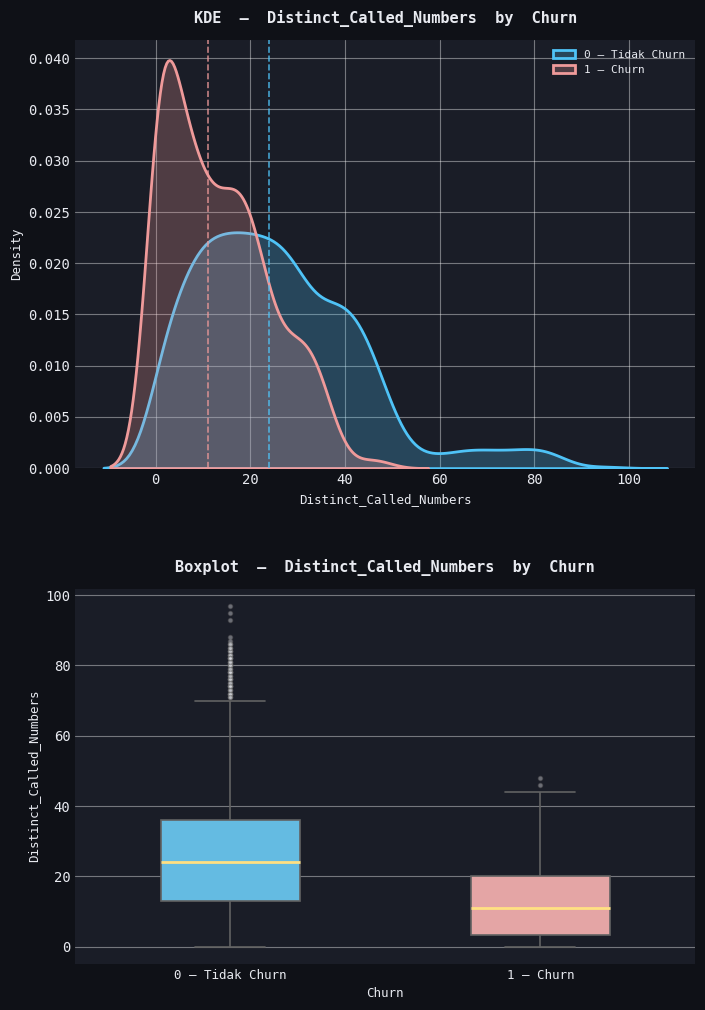


 FEATURE: Age_Group 
           count  Churn_Count  Churn_Rate (%)  Contribution_to_Total_Churn (%)
Age_Group                                                                     
3           1296          213       16.435185                        47.757848
2            921          157       17.046688                        35.201794
4            367           74       20.163488                        16.591928
5            154            2        1.298701                         0.448430
1            112            0        0.000000                         0.000000
--------------------------------------------------


/tmp/ipykernel_4650/1782804756.py:106: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(name)[TARGET]


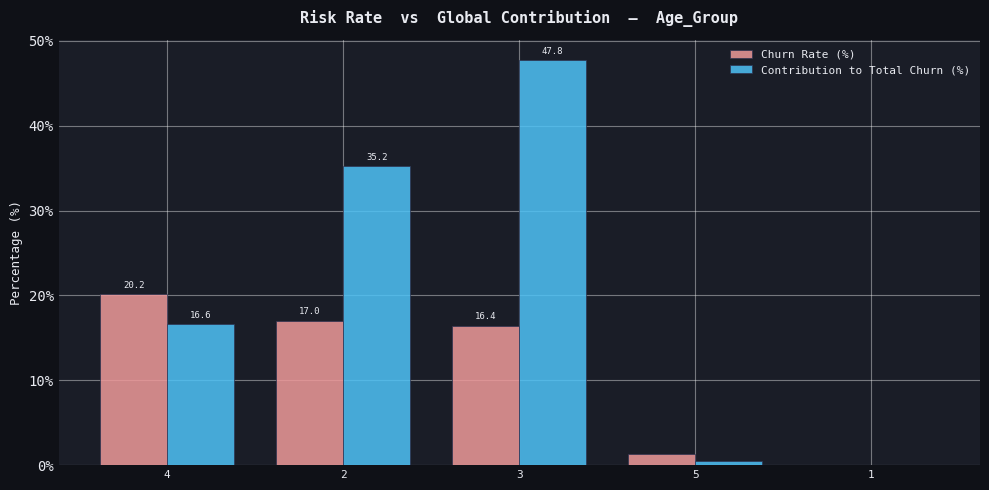


 FEATURE: Tariff_Plan 
             count  Churn_Count  Churn_Rate (%)  \
Tariff_Plan                                       
1             2621          440       16.787486   
2              229            6        2.620087   

             Contribution_to_Total_Churn (%)  
Tariff_Plan                                   
1                                  98.654709  
2                                   1.345291  
--------------------------------------------------


/tmp/ipykernel_4650/1782804756.py:106: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(name)[TARGET]


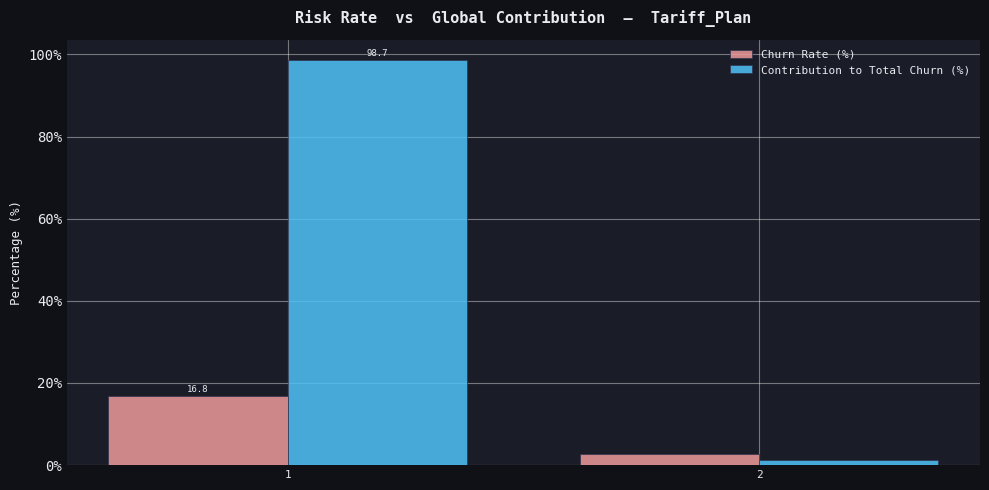


 FEATURE: Status 
        count  Churn_Count  Churn_Rate (%)  Contribution_to_Total_Churn (%)
Status                                                                     
2         684          325       47.514620                        72.869955
1        2166          121        5.586334                        27.130045
--------------------------------------------------


/tmp/ipykernel_4650/1782804756.py:106: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(name)[TARGET]


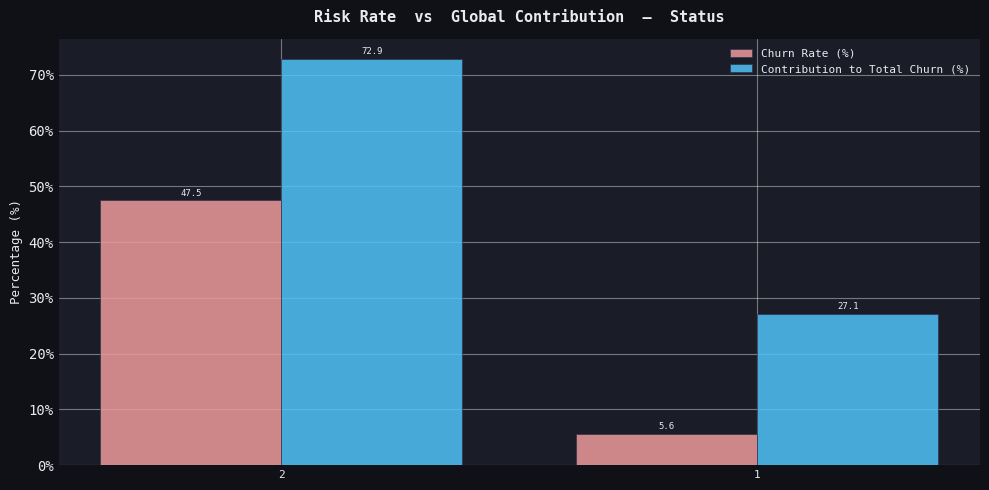


 FEATURE: Age_Binning 
             count  Churn_Count  Churn_Rate (%)  \
Age_Binning                                       
30            1296          213       16.435185   
25             921          157       17.046688   
45             367           74       20.163488   
55             154            2        1.298701   
15             112            0        0.000000   

             Contribution_to_Total_Churn (%)  
Age_Binning                                   
30                                 47.757848  
25                                 35.201794  
45                                 16.591928  
55                                  0.448430  
15                                  0.000000  
--------------------------------------------------


/tmp/ipykernel_4650/1782804756.py:106: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(name)[TARGET]


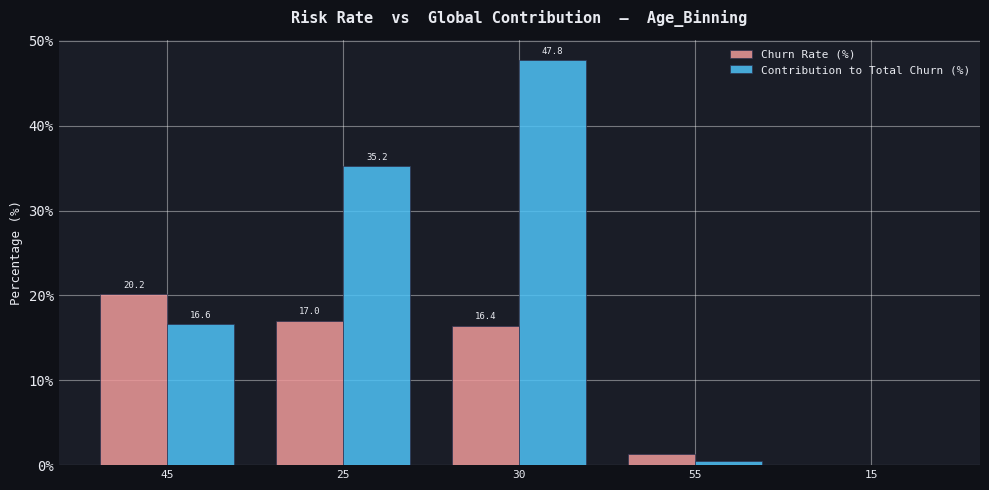


 FEATURE: Customer_Value 
                 Count     Mean   Median      Std  Min       Max
Churn                                                           
0 — Tidak Churn   2404  538.591  271.540  533.607  0.0  2165.280
1 — Churn          446  132.176  102.565  130.934  0.0   987.255
--------------------------------------------------


/tmp/ipykernel_4650/1782804756.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


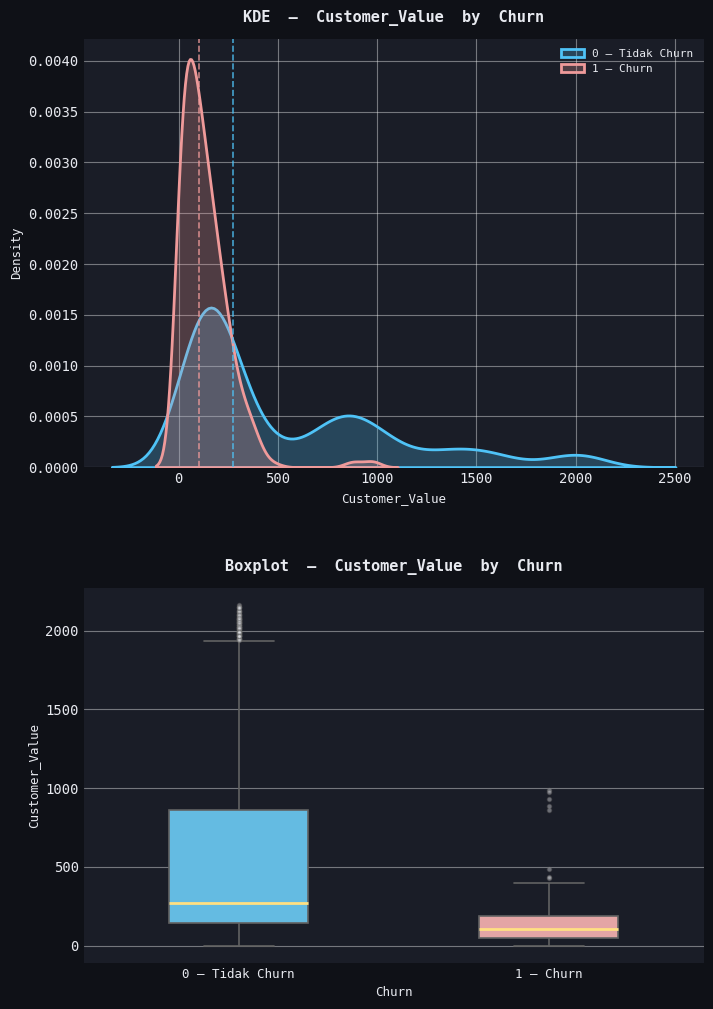

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Catatan: TARGET, BG_COLOR, PANEL_COLOR, TEXT_COLOR sudah aktif dari
# apply_dark_theme() dan definisi TARGET di cell pertama notebook.

ACCENT_0   = "#4fc3f7"   # Tidak Churn
ACCENT_1   = "#ef9a9a"   # Churn
GRID_COLOR = "#2e3250"

total_all_churn = df[TARGET].sum()

for name in df.columns:
    if name in [TARGET, 'id']:
        continue

    print(f"\n{'='*50}")
    print(f" FEATURE: {name} ")
    print('='*50)

    # =========================================================================
    # NUMERIK KONTINU
    # =========================================================================
    if pd.api.types.is_numeric_dtype(df[name]):

        # ── Statistik deskriptif per kelas ───────────────────────────────────
        desc_stats = (
            df.groupby(TARGET)[name]
            .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
            .rename(index={0: '0 — Tidak Churn', 1: '1 — Churn'})
        )
        desc_stats.columns = ['Count', 'Mean', 'Median', 'Std', 'Min', 'Max']
        print(desc_stats.round(3))
        print("-" * 50)

        # ── Visualisasi: KDE (atas) + Boxplot (bawah) — subplot terpisah ───────
        fig, (ax_kde, ax_box) = plt.subplots(
            2, 1,
            figsize=(8, 12),
            facecolor=BG_COLOR,
            gridspec_kw={'height_ratios': [1.6, 1.4], 'hspace': 0.3}
        )

        class_labels = {0: '0 — Tidak Churn', 1: '1 — Churn'}
        palette_map  = {0: ACCENT_0, 1: ACCENT_1}

        # — KDE plot —
        for cls, color in palette_map.items():
            subset = df[df[TARGET] == cls][name].dropna()
            sns.kdeplot(
                subset, ax=ax_kde,
                color=color, fill=True, alpha=0.25,
                linewidth=2, label=class_labels[cls]
            )
            ax_kde.axvline(
                subset.median(), color=color,
                linestyle='--', linewidth=1.2, alpha=0.8
            )

        ax_kde.set_title(
            f"KDE  —  {name}  by  {TARGET}",
            fontsize=11, fontweight="bold", pad=12
        )
        ax_kde.set_xlabel(name, fontsize=9)
        ax_kde.set_ylabel("Density", fontsize=9)
        ax_kde.grid(True, axis="y")
        ax_kde.legend(fontsize=8, framealpha=0.2)
        ax_kde.set_facecolor(PANEL_COLOR)
        for spine in ax_kde.spines.values():
            spine.set_edgecolor(GRID_COLOR)

        # — Boxplot —
        sns.boxplot(
            data=df, x=TARGET, y=name, ax=ax_box,
            hue=TARGET,
            palette=palette_map,
            orient='v',
            width=0.45,
            linewidth=1.2,
            legend=False,
            flierprops=dict(marker='o', markerfacecolor=TEXT_COLOR,
                            markersize=3, alpha=0.4, linestyle='none'),
            medianprops=dict(color="#ffe082", linewidth=2),
        )

        ax_box.set_title(
            f"Boxplot  —  {name}  by  {TARGET}",
            fontsize=11, fontweight="bold", pad=12
        )
        ax_box.set_xlabel(TARGET, fontsize=9)
        ax_box.set_ylabel(name, fontsize=9)
        ax_box.set_xticks([0, 1])
        ax_box.set_xticklabels(["0 — Tidak Churn", "1 — Churn"], fontsize=9)
        ax_box.grid(True, axis="y")
        ax_box.set_facecolor(PANEL_COLOR)
        for spine in ax_box.spines.values():
            spine.set_edgecolor(GRID_COLOR)

        plt.tight_layout()
        plt.show()
        plt.close(fig)

    # =========================================================================
    # KATEGORIKAL  (tidak diubah sama sekali)
    # =========================================================================
    else:
        count_stats = (
            df.groupby(name)[TARGET]
            .agg(['count', 'sum'])
            .rename(columns={'sum': 'Churn_Count'})
        )
        count_stats['Churn_Rate (%)']                  = (count_stats['Churn_Count'] / count_stats['count']) * 100
        count_stats['Contribution_to_Total_Churn (%)'] = (count_stats['Churn_Count'] / total_all_churn) * 100

        print(count_stats.sort_values(by='Churn_Count', ascending=False))
        print("-" * 50)

        stats_plot = (
            count_stats[['Churn_Rate (%)', 'Contribution_to_Total_Churn (%)']]
            .sort_values(by='Churn_Rate (%)', ascending=False)
        )

        x      = range(len(stats_plot))
        width  = 0.38
        labels = [str(v)[:14] for v in stats_plot.index]

        fig, ax = plt.subplots(figsize=(10, 5), facecolor=BG_COLOR)
        ax.set_facecolor(PANEL_COLOR)

        bars1 = ax.bar([i - width/2 for i in x], stats_plot['Churn_Rate (%)'],
                       width=width, color=ACCENT_1, alpha=0.85,
                       label='Churn Rate (%)', edgecolor=GRID_COLOR, linewidth=0.6)
        bars2 = ax.bar([i + width/2 for i in x], stats_plot['Contribution_to_Total_Churn (%)'],
                       width=width, color=ACCENT_0, alpha=0.85,
                       label='Contribution to Total Churn (%)', edgecolor=GRID_COLOR, linewidth=0.6)

        for bar in list(bars1) + list(bars2):
            h = bar.get_height()
            if h >= 3:
                ax.text(bar.get_x() + bar.get_width() / 2, h + 0.5,
                        f"{h:.1f}", ha='center', va='bottom',
                        fontsize=6.5, color=TEXT_COLOR)

        ax.set_title(f"Risk Rate  vs  Global Contribution  —  {name}",
                     fontsize=11, fontweight="bold", pad=12)
        ax.set_ylabel("Percentage (%)", fontsize=9)
        ax.set_xticks(list(x))
        ax.set_xticklabels(labels, fontsize=8)
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.0f%%'))
        ax.grid(True, axis='y')
        ax.legend(fontsize=8, framealpha=0.2)

        for spine in ax.spines.values():
            spine.set_edgecolor(GRID_COLOR)

        plt.tight_layout()
        plt.show()
        plt.close(fig)

## Laporan Analisis Bivariate: Churn Pelanggan Telekomunikasi

---

## 1. **Gambaran Umum Dataset**

Dataset terdiri dari **2.850 pelanggan** dengan **1 variabel target** (`Churn`) dan sejumlah fitur prediktor yang mencakup perilaku penggunaan, demografi, serta atribut kontrak pelanggan.

Distribusi target:
*   **Tidak Churn (0):** 2.404 pelanggan (84,4%)
*   **Churn (1):** 446 pelanggan (15,6%)

Dataset menunjukkan **ketidakseimbangan kelas (class imbalance)** yang cukup signifikan, sehingga perlu diperhatikan saat memilih metrik evaluasi model prediksi. Pendekatan ini menyarankan untuk menghindari ketergantungan metrik akurasi (*accuracy*) dan lebih berfokus pada evaluasi *precision*, *recall*, *F1-score*, atau *AUC-ROC*.

---

## 2. **Analisis Fitur Kategorikal**

### 2.1 `Complains` : Sinyal Terkuat

| Nilai | Count | Churn Count | Churn Rate | Kontribusi ke Total Churn |
|---|---|---|---|---|
| 0 (No complaint) | 2.620 | 256 | 9,77% | 57,40% |
| 1 (Complaint) | 230 | 190 | **82,61%** | 42,60% |

**Insight:**
Fitur ini adalah yang paling diskriminatif dalam seluruh dataset. Pelanggan yang pernah mengajukan komplain memiliki probabilitas churn sebesar **82,6%**, yang berarti mereka hampir pasti berhenti berlangganan. Meskipun jumlah pelanggan yang komplain hanya 230 orang (8,1% dari total), mereka menyumbang **42,6%** dari seluruh kejadian churn. Hal ini mengindikasikan bahwa penanganan komplain secara proaktif dan cepat merupakan salah satu intervensi operasional paling efektif untuk menekan angka churn.

---

### 2.2 `Status` : Indikator Keaktifan Akun

| Nilai | Count | Churn Count | Churn Rate | Kontribusi ke Total Churn |
|---|---|---|---|---|
| 2 (non-active) | 684 | 325 | **47,51%** | 72,87% |
| 1 (active) | 2.166 | 121 | 5,59% | 27,13% |

**Insight:**
Status 2 (akun non-aktif atau suspended) memiliki churn rate hampir **50%** dan mendominasi kontribusi churn secara global sebesar **72,9%**. Artinya, sebagian besar probabilitas churn sudah bisa ditangkap hanya dari status akun pelanggan. Fitur ini memiliki kekuatan prediktif yang sangat tinggi dan akan menjadi salah satu pembagi (*node*) teratas dalam algoritma pemodelan pohon keputusan.

---

### 2.3 `Tariff_Plan` : Ketimpangan Antar Paket

| Nilai | Count | Churn Count | Churn Rate | Kontribusi ke Total Churn |
|---|---|---|---|---|
| 1 (Pay as you go) | 2.621 | 440 | 16,79% | **98,65%** |
| 2 (Contractual) | 229 | 6 | 2,62% | 1,35% |

**Insight:**
Hampir semua churn terkonsentrasi di Plan 1, meskipun churn rate-nya berada di angka 16,8%. Plan 2 memiliki churn rate sangat rendah (2,6%), menunjukkan bahwa pelanggan Plan 2 jauh lebih loyal. Perlu dilakukan investigasi bisnis lebih lanjut mengenai apakah Plan 2 menawarkan benefit yang lebih kompetitif, atau apakah demografi segmen pelanggan Plan 2 memang memiliki karakteristik retensi yang lebih baik.

---

### 2.4 `Age_Group` dan `Age_Binning` : Redundansi Fitur

| Age_Group | Age_Binning | Count | Churn Rate | Kontribusi |
|---|---|---|---|---|
| 1 | 15 | 112 | 0,00% | 0,00% |
| 2 | 25 | 921 | 17,05% | 35,20% |
| 3 | 30 | 1.296 | 16,44% | 47,76% |
| 4 | 45 | 367 | 20,16% | 16,59% |
| 5 | 55 | 154 | 1,30% | 0,45% |

**Insight:**
Kedua fitur ini merepresentasikan informasi yang identik secara semantik dan hanya berbeda format *encoding*, sehingga disarankan untuk menggunakan salah satu saja guna menghindari masalah multikolinearitas. Churn rate terdistribusi relatif merata di kelompok usia 25 hingga 45 (16% hingga 20%), dengan puncak minor di kelompok usia 45. Kelompok usia paling muda (15) dan paling tua (55+) hampir tidak churn, namun jumlah sampel pada rentang tersebut terlalu kecil untuk digeneralisasi.

---

### 2.5 `Charge__Amount` : Tagihan Pengguna

| Nilai | Churn Rate | Kontribusi |
|---|---|---|
| 0 | 23,75% | 83,86% |
| 1 | 7,51% | 9,42% |
| 2 | 6,08% | 4,93% |
| ≥ 3 | ≤ 3,65% | < 2% |

**Insight:**
Terdapat hubungan terbalik antara nilai tagihan dan churn rate, di mana pelanggan dengan tagihan 0 (paling rendah) justru paling banyak churn. Kemungkinan besar ini bukanlah hubungan kausalitas langsung, melainkan akibat dari frekuensi penggunaan layanan. Pelanggan yang pasif secara otomatis memiliki tagihan rendah dan terbukti lebih mudah untuk meninggalkan layanan.

---

## 3. **Analisis Fitur Numerik**

### 3.1 `Seconds_of_Use` : Durasi Penggunaan

| Kelas | Mean | Median | Std |
|---|---|---|---|
| Tidak Churn | 5.069 | 3.596 | 4.317 |
| Churn | **1.648** | **1.256** | 1.532 |

**Insight:**
Ini adalah salah satu fitur numerik paling informatif. Pelanggan churn hanya menggunakan layanan sekitar sepertiga dari durasi pelanggan normal (median 1.256 berbanding 3.596 detik). Distribusi kepadatan (*KDE plot*) dari kedua kelas tidak banyak tumpang tindih, menjadikan fitur ini kandidat kuat sebagai variabel prediktor.

---

### 3.2 `Frequency_of_use` : Frekuensi Penggunaan

| Kelas | Mean | Median | Std |
|---|---|---|---|
| Tidak Churn | 77,87 | 64 | 58,58 |
| Churn | **30,70** | **29** | 26,09 |

**Insight:**
Pelanggan churn menggunakan layanan kurang dari separuh frekuensi pelanggan setia (median 29 berbanding 64 kali). Pola ini sangat konsisten dengan `Seconds_of_Use` dan semakin memperkuat identifikasi pelanggan churn sebagai pengguna yang pasif.

---

### 3.3 `Distinct_Called_Numbers` : Jumlah Nomor Unik yang Dihubungi

| Kelas | Mean | Median | Std |
|---|---|---|---|
| Tidak Churn | 25,87 | 24 | 17,41 |
| Churn | **13,08** | **11** | 10,80 |

**Insight:**
Pelanggan churn menghubungi jumlah nomor yang jauh lebih sedikit (median 11 berbanding 24). Hal ini menunjukkan cakupan jaringan kontak yang lebih sempit dan mengindikasikan minimnya keterikatan terhadap layanan komunikasi seluler secara keseluruhan.

---

### 3.4 `Frequency_of_SMS` : Frekuensi SMS

| Kelas | Mean | Median | Std |
|---|---|---|---|
| Tidak Churn | 84,35 | 26 | 118,60 |
| Churn | **16,85** | **11** | 24,33 |

**Insight:**
Tren penurunan aktivitas yang serupa ditemukan pada penggunaan SMS. Pelanggan churn secara signifikan lebih jarang mengirim pesan. Namun, standar deviasi yang sangat besar (118 untuk kelas tidak churn) menandakan sebaran yang menceng (*skewed*) dengan keberadaan *outlier*, sehingga fitur ini tergolong lebih memiliki variansi *noise* dibandingkan fitur penggunaan lainnya.

---

### 3.5 `Customer_Value` : Nilai Pelanggan

| Kelas | Mean | Median | Std |
|---|---|---|---|
| Tidak Churn | 538,59 | 271,54 | 533,61 |
| Churn | **132,18** | **102,57** | 130,93 |

**Insight:**
Pemisahan distribusi antar kelas sangat tegas. Median pelanggan churn (102,57) hanya berkisar 37% dari metrik pelanggan tidak churn (271,54). Kendati informatif, perlu dilakukan pengujian korelasi (*multivariate analysis*) dengan fitur penggunaan seperti `Seconds_of_Use` untuk memastikan fitur ini tidak memicu overestimasi performa akibat redundansi turunan data.

---

### 3.6 `Call__Failure` : Jumlah Kegagalan Panggilan

| Kelas | Mean | Median | Std |
|---|---|---|---|
| Tidak Churn | 7,79 | 6 | 7,22 |
| Churn | 7,86 | 6 | 7,87 |

**Insight:**
Distribusi statistik antara kedua kelas nyaris identik dari segi rata-rata, median, hingga standar deviasi. Secara evaluasi tunggal (*bivariate*), fitur ini tidak menyumbangkan informasi diskriminatif yang mampu membedakan pelanggan churn dari populasi normal.

---

### 3.7 `Subscription__Length` : Lama Berlangganan

| Kelas | Mean | Median | Std |
|---|---|---|---|
| Tidak Churn | 32,60 | 35 | 8,51 |
| Churn | 31,68 | 35 | 9,78 |

**Insight:**
Secara rata-rata populasi, fitur ini tampak tidak memberikan separasi kelas yang memuaskan (keduanya memiliki median identik di angka 35). Namun, mengacu pada temuan analisis *outlier* sebelumnya, terdapat sinyal kerentanan yang tersembunyi pada ujung sebaran data. Pelanggan baru dengan masa berlangganan ekstrem rendah (di bawah batas 15,5 bulan) memiliki risiko churn 2,3 kali lipat lebih tinggi. Oleh karenanya, fitur ini menyimpan fungsi prediktif spesifik dan patut dipertahankan.

---

## 4. **Ringkasan Prioritas Fitur**

| Prioritas | Fitur | Alasan |
|---|---|---|
| Sangat Kuat | `Complains`, `Status`, `Customer_Value` | Pemisahan kelas ekstrem dengan churn rate atau distribusi numerik yang jauh berbeda. |
| Kuat | `Seconds_of_Use`, `Frequency_of_use`, `Distinct_Called_Numbers` | Konsisten memperlihatkan pola pengguna pasif yang berkorelasi positif dengan probabilitas churn. |
| Menengah | `Tariff_Plan`, `Frequency_of_SMS`, `Age_Group` | Mengandung sinyal klasifikasi namun disertai *noise* atau ketidakseimbangan proporsi sampel. |
| Kondisional | `Subscription__Length` | Meskipun pusat datanya terpusat di titik yang sama, rentang nilai batas bawahnya sangat esensial untuk mendeteksi *churn* pelanggan baru. |
| Lemah | `Call__Failure` | Sangat minim perbedaan matematis antar kelas. |
| Waspada | `Age_Binning`, `Age_Group`, `Customer_Value` | Memiliki kecurigaan redundansi logika; wajib dievaluasi ulang pada tahap pengujian korelasi multivariat. |

---

## 5. **Profil Pelanggan Berisiko Churn**

Berdasarkan seluruh hasil analisis distribusi fitur, rancangan profil pelanggan dengan probabilitas *churn* tertinggi tergambarkan melalui indikator-indikator riwayat berikut:

*   Pernah mengajukan keluhan layanan (*komplain*).
*   Memiliki riwayat pembaruan status akun sebagai non-aktif atau ditangguhkan (*Status = 2*).
*   Berlangganan di bawah ketentuan paket dasar (*Tariff Plan 1*).
*   Memiliki intensitas penggunaan yang sangat rendah secara durasi, frekuensi pemanggilan, maupun cakupan nomor tujuan.
*   Total pengeluaran tagihan bulanan berada pada persentil terendah (*Charge Amount mendekati angka 0*).
*   Memiliki rekam metrik *Customer Value* yang rendah (di bawah ambang batas 103).
*   Dikategorikan sebagai pelanggan baru dengan jejak masa berlangganan di bawah 15 bulan.

In [ ]:
cat = [
    'Complains',
    'Tariff_Plan',
    'Status',
    'Age_Group',
    'Age_Binning',
    'Charge__Amount'
]

for col in cat:
    if col in df.columns:
        df[col] = df[col].astype('int64')

# B. Uji Korelasi & Asosiasi

## **Method: Spearman**

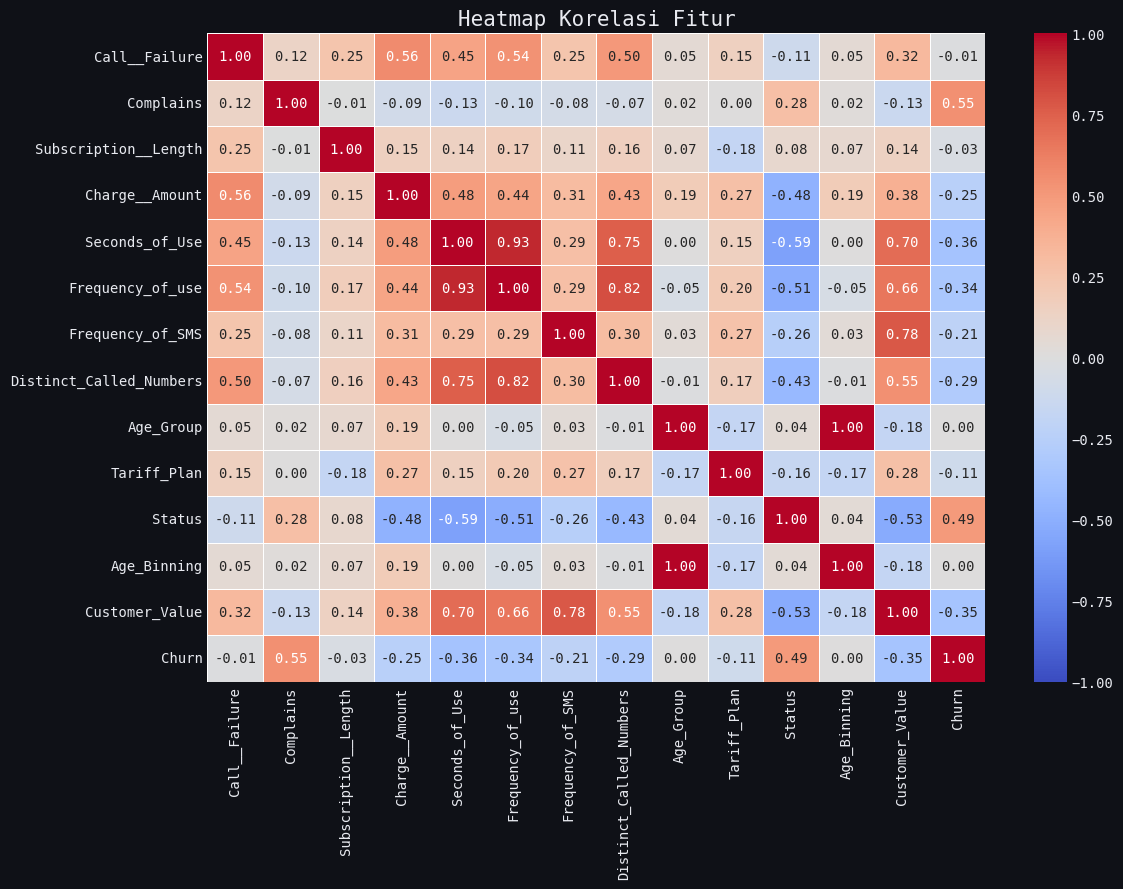

In [ ]:
plt.figure(figsize=(12, 9))
corr = df.corr(method='spearman')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, vmin=-1, vmax=1)
plt.title('Heatmap Korelasi Fitur', fontsize=15)
plt.tight_layout()
plt.show()

## **Method: Pearson & Point-Biserial Correlation**

  POINT-BISERIAL CORRELATION — SETIAP FITUR VS CHURN
                  Fitur  Korelasi  Abs Korelasi  P-Value Signifikan
              Complains    0.5461        0.5461   0.0000         Ya
                 Status    0.4929        0.4929   0.0000         Ya
       Frequency_of_use   -0.2986        0.2986   0.0000         Ya
         Seconds_of_Use   -0.2960        0.2960   0.0000         Ya
         Customer_Value   -0.2871        0.2871   0.0000         Ya
Distinct_Called_Numbers   -0.2703        0.2703   0.0000         Ya
       Frequency_of_SMS   -0.2189        0.2189   0.0000         Ya
         Charge__Amount   -0.2017        0.2017   0.0000         Ya
            Tariff_Plan   -0.1060        0.1060   0.0000         Ya
   Subscription__Length   -0.0380        0.0380   0.0426         Ya
            Age_Binning   -0.0115        0.0115   0.5397      Tidak
              Age_Group   -0.0059        0.0059   0.7533      Tidak
          Call__Failure    0.0033        0.0033   0.8598      T

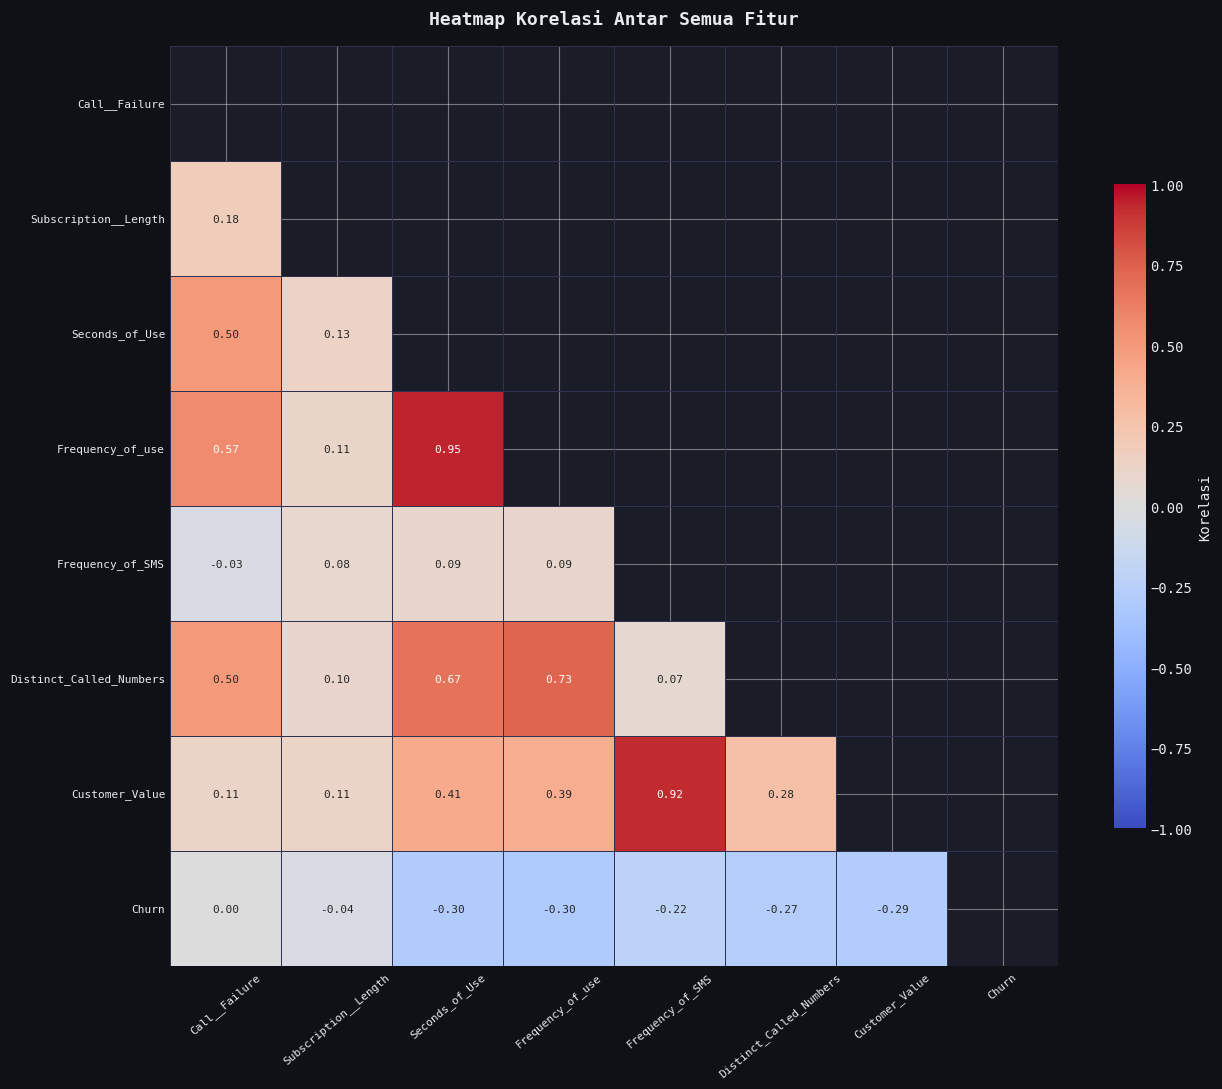

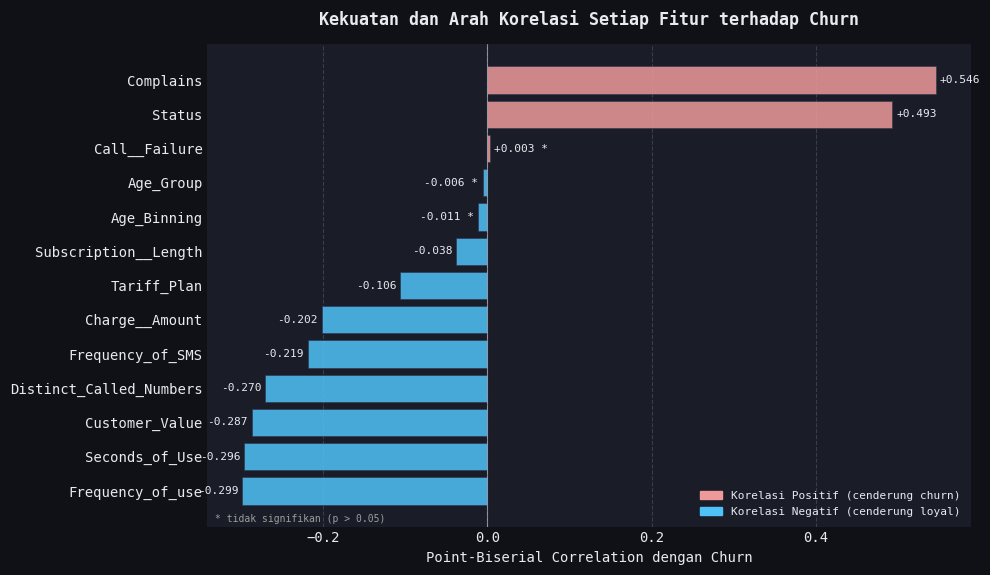


  RINGKASAN KORELASI FITUR VS CHURN

Top 5 Fitur Paling Berkorelasi dengan Churn:
  Complains                      r = +0.5461  → cenderung CHURN
  Status                         r = +0.4929  → cenderung CHURN
  Frequency_of_use               r = -0.2986  → cenderung LOYAL
  Seconds_of_Use                 r = -0.2960  → cenderung LOYAL
  Customer_Value                 r = -0.2871  → cenderung LOYAL

Fitur dengan Korelasi Menengah (peringkat 6-10):
  Distinct_Called_Numbers        r = -0.2703
  Frequency_of_SMS               r = -0.2189
  Charge__Amount                 r = -0.2017
  Tariff_Plan                    r = -0.1060
  Subscription__Length           r = -0.0380

Fitur Tidak Signifikan (p > 0.05):
  Age_Binning                    r = -0.0115  p = 0.5397
  Age_Group                      r = -0.0059  p = 0.7533
  Call__Failure                  r = +0.0033  p = 0.8598


In [ ]:
from scipy import stats
from scipy.stats import pointbiserialr

# Catatan: TARGET, BG_COLOR, PANEL_COLOR, TEXT_COLOR sudah didefinisikan
# secara global di cell pertama notebook (TARGET = 'Churn').

# ══════════════════════════════════════════════════
# BAGIAN A: Point-Biserial Correlation vs Churn
# ══════════════════════════════════════════════════

print('=' * 60)
print('  POINT-BISERIAL CORRELATION — SETIAP FITUR VS CHURN')
print('=' * 60)

fitur_semua = [c for c in df.columns if c != TARGET]
pb_results  = []

for col in fitur_semua:
    try:
        corr, pval = pointbiserialr(df[TARGET], df[col])
        pb_results.append({
            'Fitur':       col,
            'Korelasi':    round(corr, 4),
            'Abs Korelasi':round(abs(corr), 4),
            'P-Value':     round(pval, 4),
            'Signifikan':  'Ya' if pval < 0.05 else 'Tidak',
        })
    except Exception as e:
        print(f'  Gagal: {col} — {e}')

pb_df = pd.DataFrame(pb_results).sort_values('Abs Korelasi', ascending=False)
print(pb_df.to_string(index=False))

print('\nInterpretasi arah korelasi:')
print('  Positif (+) : nilai fitur tinggi cenderung CHURN')
print('  Negatif (-) : nilai fitur tinggi cenderung TIDAK CHURN')


# ══════════════════════════════════════════════════
# BAGIAN B: Heatmap Korelasi Antar Semua Fitur
# ══════════════════════════════════════════════════

corr_matrix = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(13, 11), facecolor=BG_COLOR)
mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True  # sembunyikan segitiga atas (duplikat)

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    ax=ax,
    linewidths=0.4,
    linecolor='#2e3250',
    annot_kws={'size': 8},
    cbar_kws={'shrink': 0.7, 'label': 'Korelasi'},
)

ax.set_title('Heatmap Korelasi Antar Semua Fitur',
             fontsize=13, fontweight='bold', pad=16)
ax.tick_params(axis='x', rotation=40, labelsize=8)
ax.tick_params(axis='y', rotation=0,  labelsize=8)
plt.tight_layout()
plt.show()


# ══════════════════════════════════════════════════
# BAGIAN C: Bar Chart Korelasi Fitur vs Churn
# ══════════════════════════════════════════════════

pb_plot = pb_df[pb_df['Fitur'] != TARGET].sort_values('Korelasi')
colors  = ['#ef9a9a' if v > 0 else '#4fc3f7' for v in pb_plot['Korelasi']]

fig, ax = plt.subplots(figsize=(10, max(5, len(pb_plot) * 0.45)),
                        facecolor=BG_COLOR)

bars = ax.barh(pb_plot['Fitur'], pb_plot['Korelasi'],
               color=colors, edgecolor='#2e3250', linewidth=0.5, alpha=0.85)

for bar, val, sig in zip(bars, pb_plot['Korelasi'], pb_plot['Signifikan']):
    x_pos = bar.get_width() + (0.005 if val >= 0 else -0.005)
    ha    = 'left' if val >= 0 else 'right'
    label = f'{val:+.3f}' + ('' if sig == 'Ya' else ' *')
    ax.text(x_pos, bar.get_y() + bar.get_height() / 2,
            label, va='center', ha=ha, fontsize=8, color=TEXT_COLOR)

ax.axvline(0, color=TEXT_COLOR, linewidth=0.8, alpha=0.5)
ax.set_xlabel('Point-Biserial Correlation dengan Churn', fontsize=10)
ax.set_title('Kekuatan dan Arah Korelasi Setiap Fitur terhadap Churn',
             fontsize=12, fontweight='bold', pad=14)
ax.grid(True, axis='x', linestyle='--', alpha=0.15, color='#ffffff')
ax.grid(False, axis='y')

leg = [mpatches.Patch(color='#ef9a9a', label='Korelasi Positif (cenderung churn)'),
       mpatches.Patch(color='#4fc3f7', label='Korelasi Negatif (cenderung loyal)'),]
ax.legend(handles=leg, fontsize=8, framealpha=0.15, loc='lower right')
ax.annotate('* tidak signifikan (p > 0.05)', xy=(0.01, 0.01),
            xycoords='axes fraction', fontsize=7, color='#9e9e9e')

plt.tight_layout()
plt.show()


# ══════════════════════════════════════════════════
# BAGIAN D: Ringkasan Fitur Terkuat dan Terlemah
# ══════════════════════════════════════════════════

print('\n' + '=' * 60)
print('  RINGKASAN KORELASI FITUR VS CHURN')
print('=' * 60)

top5    = pb_df[pb_df['Signifikan'] == 'Ya'].head(5)
bottom5 = pb_df[pb_df['Signifikan'] == 'Ya'].tail(5)
tidak_sig = pb_df[pb_df['Signifikan'] == 'Tidak']

print('\nTop 5 Fitur Paling Berkorelasi dengan Churn:')
for _, r in top5.iterrows():
    arah = 'CHURN' if r['Korelasi'] > 0 else 'LOYAL'
    print(f'  {r["Fitur"]:<30} r = {r["Korelasi"]:+.4f}  → cenderung {arah}')

print('\nFitur dengan Korelasi Menengah (peringkat 6-10):')
for _, r in bottom5.iterrows():
    print(f'  {r["Fitur"]:<30} r = {r["Korelasi"]:+.4f}')

if len(tidak_sig) > 0:
    print(f'\nFitur Tidak Signifikan (p > 0.05):')
    for _, r in tidak_sig.iterrows():
        print(f'  {r["Fitur"]:<30} r = {r["Korelasi"]:+.4f}  p = {r["P-Value"]:.4f}')
else:
    print('\nSemua fitur signifikan secara statistik (p < 0.05)')

  UJI NON-LINEAR — Point-Biserial vs Kruskal-Wallis

  Point-Biserial : mengukur hubungan LINEAR saja
  Kruskal-Wallis : mengukur hubungan apapun (linear + non-linear)

  Interpretasi:
  PB tidak sig + KW tidak sig → tidak ada hubungan sama sekali
  PB tidak sig + KW signifikan → ada hubungan NON-LINEAR
  PB signifikan + KW signifikan → hubungan linear + non-linear

  Fitur                        PB r     PB p   KW stat     KW p  Kesimpulan
  ------------------------------------------------------------------------------
  Call__Failure             +0.0033   0.8598     0.614   0.4331  Tidak ada hubungan
  Age_Group                 -0.0059   0.7533     0.067   0.7956  Tidak ada hubungan
  Age_Binning               -0.0115   0.5397     0.067   0.7956  Tidak ada hubungan
  Subscription__Length      -0.0380   0.0426     3.112   0.0777  Lemah linear saja

  KESIMPULAN UJI NON-LINEAR

  Call__Failure
  PB : p=0.8598 → tidak signifikan
  KW : p=0.4331 → tidak signifikan
  → ❌ Tidak ada hubunga

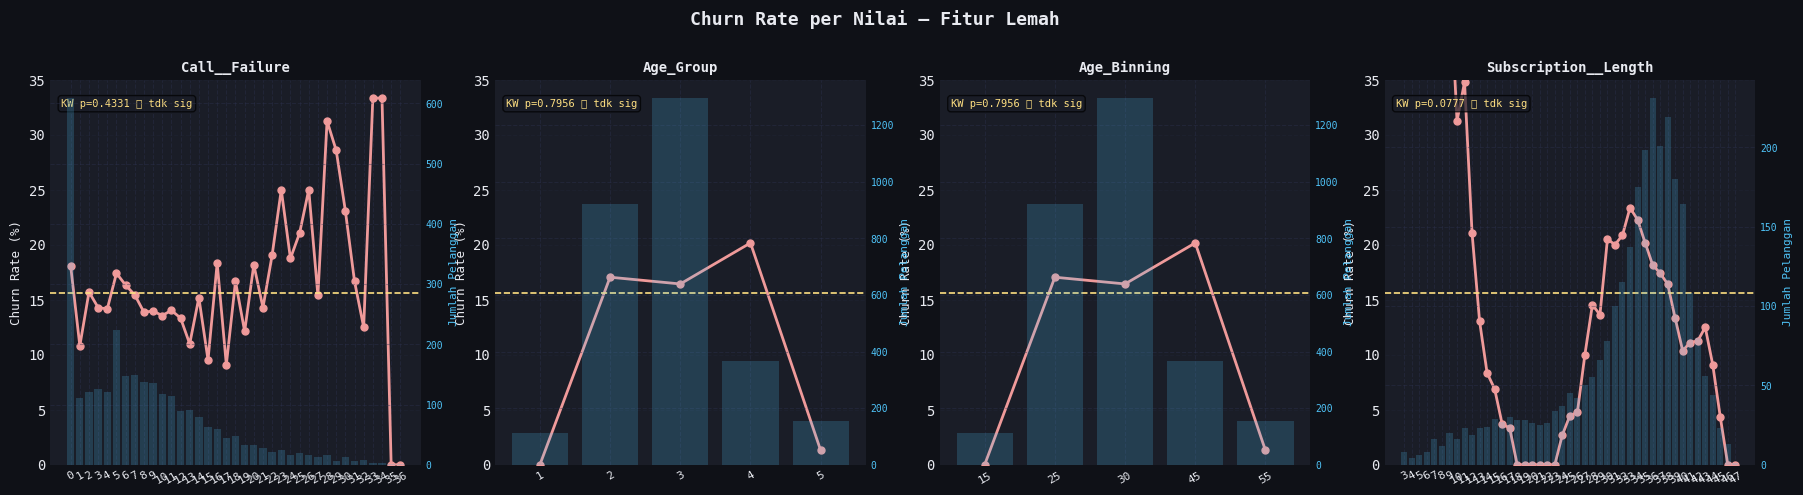

In [ ]:
# Analisis: Uji Non-Linear Fitur Lemah — Kruskal-Wallis

from scipy.stats import kruskal, pointbiserialr
import warnings; warnings.filterwarnings('ignore')

FITUR_LEMAH  = ['Call__Failure', 'Age_Group', 'Age_Binning', 'Subscription__Length']

# ── DRY: pakai fungsi tema yang sudah didefinisikan di cell pertama notebook
BG_COLOR, PANEL_COLOR, TEXT_COLOR, GRID_COLOR = apply_dark_theme()

# ── Hitung PB (atau ambil dari pb_df jika sudah ada)
if 'pb_df' in dir():
    pb_dict = pb_df.set_index('Fitur')[['Korelasi','P-Value']].to_dict('index')
else:
    pb_dict = {}
    for col in FITUR_LEMAH:
        corr, pval = pointbiserialr(df[TARGET], df[col])
        pb_dict[col] = {'Korelasi': round(corr,4), 'P-Value': round(pval,4)}


# ══════════════════════════════════════════════════════
# BAGIAN A: Tabel Perbandingan PB vs Kruskal-Wallis
# ══════════════════════════════════════════════════════

print('=' * 72)
print('  UJI NON-LINEAR — Point-Biserial vs Kruskal-Wallis')
print('=' * 72)
print()
print('  Point-Biserial : mengukur hubungan LINEAR saja')
print('  Kruskal-Wallis : mengukur hubungan apapun (linear + non-linear)')
print()
print('  Interpretasi:')
print('  PB tidak sig + KW tidak sig → tidak ada hubungan sama sekali')
print('  PB tidak sig + KW signifikan → ada hubungan NON-LINEAR')
print('  PB signifikan + KW signifikan → hubungan linear + non-linear')
print()
print(f'  {"Fitur":<25} {"PB r":>7} {"PB p":>8} {"KW stat":>9} '
      f'{"KW p":>8}  {"Kesimpulan"}')
print('  ' + '-' * 78)

kw_results = {}
for col in FITUR_LEMAH:
    if col not in df.columns:
        continue

    grp0      = df[df[TARGET] == 0][col].dropna()
    grp1      = df[df[TARGET] == 1][col].dropna()
    kw_stat, kw_p = kruskal(grp0, grp1)
    kw_results[col] = {'stat': kw_stat, 'p': kw_p}

    pb_r   = pb_dict.get(col, {}).get('Korelasi', 0)
    pb_p   = pb_dict.get(col, {}).get('P-Value',  1)
    pb_sig = pb_p  < 0.05
    kw_sig = kw_p  < 0.05

    if   not pb_sig and not kw_sig: kesimpulan = 'Tidak ada hubungan'
    elif not pb_sig and kw_sig:     kesimpulan = 'Non-linear ← perlu binning'
    elif pb_sig     and kw_sig:     kesimpulan = 'Linear + non-linear'
    else:                           kesimpulan = 'Lemah linear saja'

    print(f'  {col:<25} {pb_r:>+7.4f} {pb_p:>8.4f} {kw_stat:>9.3f} '
          f'{kw_p:>8.4f}  {kesimpulan}')


# ══════════════════════════════════════════════════════
# BAGIAN B: Visualisasi Churn Rate per Nilai
# Untuk melihat secara visual pola non-linear yang mungkin ada
# ══════════════════════════════════════════════════════

fig, axes = plt.subplots(1, len(FITUR_LEMAH),
                          figsize=(5.5 * len(FITUR_LEMAH), 5),
                          facecolor=BG_COLOR)
fig.suptitle('Churn Rate per Nilai — Fitur Lemah',
             fontsize=13, fontweight='bold', y=1.02)

for ax, col in zip(axes, FITUR_LEMAH):
    if col not in df.columns:
        continue

    churn_rate = (df.groupby(col)[TARGET]
                  .mean().reset_index().sort_values(col))
    counts     = df[col].value_counts().sort_index()

    # Bar: frekuensi pelanggan (axis kanan)
    ax2 = ax.twinx()
    ax2.bar(range(len(counts)), counts.values,
            color='#4fc3f7', alpha=0.20)
    ax2.set_ylabel('Jumlah Pelanggan', color='#4fc3f7', fontsize=8)
    ax2.tick_params(axis='y', colors='#4fc3f7', labelsize=7)

    # Line: churn rate (axis kiri)
    x_pos = [list(counts.index).index(v)
              for v in churn_rate[col] if v in list(counts.index)]
    ax.plot(x_pos, churn_rate[TARGET].values * 100,
            color='#ef9a9a', linewidth=2, marker='o', markersize=5)
    ax.axhline(df[TARGET].mean() * 100,
               color='#ffe082', linestyle='--', linewidth=1.2,
               label=f'Avg ({df[TARGET].mean()*100:.1f}%)')

    # Anotasi KW result
    kw_p   = kw_results[col]['p']
    kw_lbl = f'KW p={kw_p:.4f} {"✅ sig" if kw_p < 0.05 else "❌ tdk sig"}'
    ax.annotate(kw_lbl, xy=(0.03, 0.93), xycoords='axes fraction',
                fontsize=7.5, color='#ffe082',
                bbox=dict(boxstyle='round,pad=0.3',
                          facecolor=PANEL_COLOR, alpha=0.7))

    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels([str(v) for v in counts.index],
                        fontsize=8, rotation=30)
    ax.set_ylabel('Churn Rate (%)', fontsize=9)
    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.set_ylim(0, 35)
    ax.grid(True, axis='y', linestyle='--', alpha=0.15, color=GRID_COLOR)


# ══════════════════════════════════════════════════════
# BAGIAN C: Kesimpulan
# ══════════════════════════════════════════════════════

print('\n' + '=' * 72)
print('  KESIMPULAN UJI NON-LINEAR')
print('=' * 72)

for col in FITUR_LEMAH:
    pb_p   = pb_dict.get(col, {}).get('P-Value', 1)
    kw_p   = kw_results[col]['p']
    pb_sig = pb_p < 0.05
    kw_sig = kw_p < 0.05

    if not pb_sig and not kw_sig:
        verdict = '❌ Tidak ada hubungan — kandidat DROP'
    elif not pb_sig and kw_sig:
        verdict = '⚠  Non-linear terdeteksi — pertahankan, lakukan binning'
    else:
        verdict = '✅ Ada hubungan — pertahankan'

    print(f'\n  {col}')
    print(f'  PB : p={pb_p:.4f} → {"signifikan" if pb_sig else "tidak signifikan"}')
    print(f'  KW : p={kw_p:.4f} → {"signifikan" if kw_sig else "tidak signifikan"}')
    print(f'  → {verdict}')

## **Method: Cramér's V**

  CRAMÉR'S V (BIAS-CORRECTED): ASOSIASI FITUR KATEGORIK VS CHURN

  Interpretasi Cramér V:
  < 0.10        : Lemah
  0.10 - 0.30   : Sedang
  > 0.30        : Kuat

  Fitur                      Cramér V    P-Value   Signifikan   Kekuatan  Reliabel*
  ------------------------------------------------------------------------------
  Complains                    0.5441   0.000000           Ya        Kuat  Ya
  Status                       0.4915   0.000000           Ya        Kuat  Ya
  Tariff_Plan                  0.1025   0.000000           Ya      Sedang  Ya
  Charge__Amount               0.2444   0.000000           Ya      Sedang  TIDAK
  Age_Group                    0.1304   0.000000           Ya      Sedang  Ya
  Age_Binning                  0.1304   0.000000           Ya      Sedang  Ya

  * Reliabel = TIDAK berarti ada sel tabel kontingensi dengan expected
    count < 5, melanggar asumsi minimum chi-square. Hasil V dan p-value
    untuk baris ini perlu diinterpretasikan dengan hati-

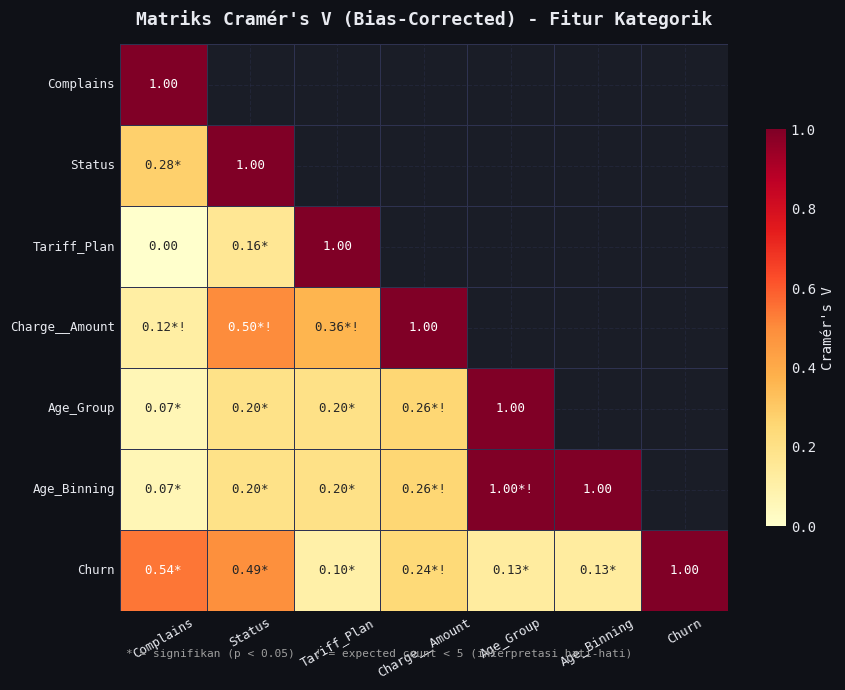

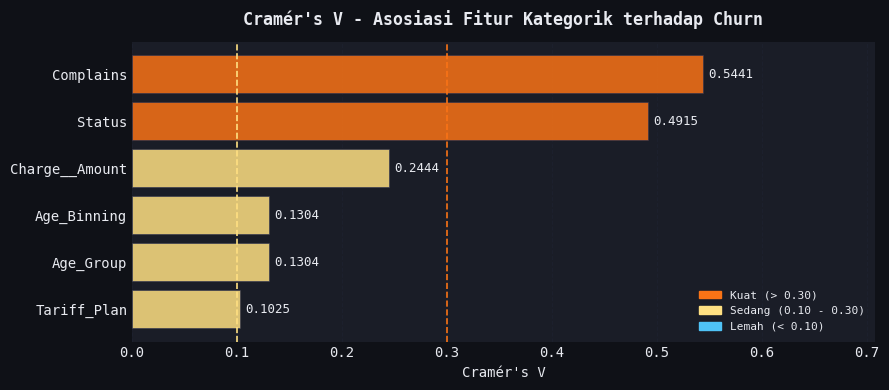


  RINGKASAN CRAMÉR'S V

  Asosiasi KUAT (V >= 0.30) - Pertahankan:
    Complains                 V = 0.5441
    Status                    V = 0.4915

  Asosiasi SEDANG (0.10 <= V < 0.30) - Pertahankan:
    Charge__Amount            V = 0.2444 [!! expected count < 5, interpretasi tidak reliabel]
    Age_Group                 V = 0.1304
    Age_Binning               V = 0.1304
    Tariff_Plan               V = 0.1025

  Pasangan Fitur Kategorik Redundan (V >= 0.50):
    Status x Charge__Amount -> V = 0.5022  REDUNDAN  [!! expected count < 5]
    Age_Group x Age_Binning -> V = 1.0000  REDUNDAN  [!! expected count < 5]


In [ ]:
# Analisis (Lanjutan): Cramér's V Asosiasi Fitur Kategorik

from scipy.stats import chi2_contingency
import warnings; warnings.filterwarnings('ignore')

TARGET = 'Churn'

FITUR_KAT = ['Complains', 'Status', 'Tariff_Plan', 'Charge__Amount',
            'Age_Group', 'Age_Binning']

# ── DRY: pakai fungsi tema yang sudah didefinisikan di cell pertama notebook
BG_COLOR, PANEL_COLOR, TEXT_COLOR, GRID_COLOR = apply_dark_theme()


# ══════════════════════════════════════════════════════
# FUNGSI: Hitung Cramér's V (dengan koreksi bias Bergsma-Wicher)
# ══════════════════════════════════════════════════════

def cramers_v(x, y):
    """
    Menghitung Cramér's V (bias-corrected, Bergsma & Wicher 2013)
    antara dua variabel kategorik.
    Nilai: 0 = tidak ada asosiasi, 1 = asosiasi sempurna
    Interpretasi umum:
      < 0.10 : lemah
      0.10 - 0.30 : sedang
      > 0.30 : kuat

    Mengembalikan juga flag 'reliabel' = False jika ada sel dengan
    expected count < 5 (melanggar asumsi minimum chi-square).
    """
    ct = pd.crosstab(x, y)
    chi2, p, dof, expected = chi2_contingency(ct)
    n = ct.sum().sum()

    # Cek asumsi minimum expected count chi-square
    reliabel = (expected >= 5).all()

    # Cramér's V mentah
    r, k = ct.shape
    phi2 = chi2 / n

    # Koreksi bias Bergsma-Wicher
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr    = r - ((r - 1) ** 2) / (n - 1)
    k_corr    = k - ((k - 1) ** 2) / (n - 1)
    min_dim_corr = min(r_corr - 1, k_corr - 1)

    v = np.sqrt(phi2_corr / min_dim_corr) if min_dim_corr > 0 else 0

    return round(v, 4), round(p, 6), reliabel


# ══════════════════════════════════════════════════════
# BAGIAN A: Cramér's V setiap fitur kategorik vs Churn
# ══════════════════════════════════════════════════════

print('=' * 75)
print("  CRAMÉR'S V (BIAS-CORRECTED): ASOSIASI FITUR KATEGORIK VS CHURN")
print('=' * 75)
print()
print('  Interpretasi Cramér V:')
print('  < 0.10        : Lemah')
print('  0.10 - 0.30   : Sedang')
print('  > 0.30        : Kuat')
print()
print(f'  {"Fitur":<25} {"Cramér V":>9} {"P-Value":>10} '
      f'{"Signifikan":>12} {"Kekuatan":>10}  {"Reliabel*"}')
print('  ' + '-' * 78)

cv_results = []
for col in FITUR_KAT:
    if col not in df.columns:
        continue
    v, p, reliabel = cramers_v(df[col], df[TARGET])

    if   v < 0.10: kekuatan = 'Lemah'
    elif v < 0.30: kekuatan = 'Sedang'
    else:          kekuatan = 'Kuat'

    sig = 'Ya' if p < 0.05 else 'Tidak'
    rel_note = 'Ya' if reliabel else 'TIDAK'

    cv_results.append({
        'Fitur':     col,
        'Cramér V':  v,
        'P-Value':   p,
        'Signifikan': sig,
        'Kekuatan':  kekuatan,
        'Reliabel':  reliabel,
    })
    print(f'  {col:<25} {v:>9.4f} {p:>10.6f} {sig:>12}  {kekuatan:>10}  {rel_note}')

print('\n  * Reliabel = TIDAK berarti ada sel tabel kontingensi dengan expected')
print('    count < 5, melanggar asumsi minimum chi-square. Hasil V dan p-value')
print('    untuk baris ini perlu diinterpretasikan dengan hati-hati.')

cv_df = pd.DataFrame(cv_results).sort_values('Cramér V', ascending=False)


# ══════════════════════════════════════════════════════
# BAGIAN B: Matriks Cramér's V antar semua fitur kategorik
# ══════════════════════════════════════════════════════

ALL_KAT = FITUR_KAT + [TARGET]
ALL_KAT = [c for c in ALL_KAT if c in df.columns]

n = len(ALL_KAT)
matrix_v = pd.DataFrame(np.zeros((n, n)), index=ALL_KAT, columns=ALL_KAT)
matrix_p = pd.DataFrame(np.ones((n, n)),  index=ALL_KAT, columns=ALL_KAT)
matrix_reliabel = pd.DataFrame(np.ones((n, n), dtype=bool), index=ALL_KAT, columns=ALL_KAT)

for i, col_a in enumerate(ALL_KAT):
    for j, col_b in enumerate(ALL_KAT):
        if i == j:
            matrix_v.iloc[i, j] = 1.0
            matrix_p.iloc[i, j] = 0.0
        elif i < j:
            v, p, reliabel = cramers_v(df[col_a], df[col_b])
            matrix_v.iloc[i, j] = v
            matrix_v.iloc[j, i] = v
            matrix_p.iloc[i, j] = p
            matrix_p.iloc[j, i] = p
            matrix_reliabel.iloc[i, j] = reliabel
            matrix_reliabel.iloc[j, i] = reliabel

# Heatmap Cramér's V
fig, ax = plt.subplots(figsize=(9, 7), facecolor=BG_COLOR)
mask = np.triu(np.ones_like(matrix_v, dtype=bool), k=1)

# Anotasi: nilai V + * jika signifikan + ! jika expected count < 5
annot = pd.DataFrame(index=ALL_KAT, columns=ALL_KAT, dtype=str)
for i in range(n):
    for j in range(n):
        v_val = matrix_v.iloc[i, j]
        p_val = matrix_p.iloc[i, j]
        rel   = matrix_reliabel.iloc[i, j]
        star  = '*' if p_val < 0.05 and i != j else ''
        warn  = '!' if not rel and i != j else ''
        annot.iloc[i, j] = f'{v_val:.2f}{star}{warn}'

sns.heatmap(
    matrix_v, mask=mask, annot=annot, fmt='', cmap='YlOrRd', ax=ax,
    vmin=0, vmax=1, linewidths=0.4, linecolor='#2e3250',
    annot_kws={'size': 9}, cbar_kws={'shrink': 0.7, 'label': "Cramér's V"},
)
ax.set_title("Matriks Cramér's V (Bias-Corrected) - Fitur Kategorik",
             fontsize=13, fontweight='bold', pad=14)
ax.tick_params(axis='x', rotation=30, labelsize=9)
ax.tick_params(axis='y', rotation=0,  labelsize=9)
ax.annotate('* = signifikan (p < 0.05)   ! = expected count < 5 (interpretasi hati-hati)',
            xy=(0.01, -0.08), xycoords='axes fraction', fontsize=8, color='#9e9e9e')
plt.tight_layout()
plt.show()


# ══════════════════════════════════════════════════════
# BAGIAN C: Bar Chart Cramér's V vs Churn
# (tidak berubah, tetap sama seperti sebelumnya)
# ══════════════════════════════════════════════════════

df_plot = cv_df.sort_values('Cramér V', ascending=True)
colors  = ['#f97316' if v >= 0.30 else
           '#ffe082' if v >= 0.10 else
           '#4fc3f7' for v in df_plot['Cramér V']]

fig, ax = plt.subplots(figsize=(9, max(4, len(df_plot) * 0.6)), facecolor=BG_COLOR)
bars = ax.barh(df_plot['Fitur'], df_plot['Cramér V'],
               color=colors, edgecolor='#2e3250', linewidth=0.5, alpha=0.85)

for bar, val, sig in zip(bars, df_plot['Cramér V'], df_plot['Signifikan']):
    label = f'{val:.4f}' + ('' if sig == 'Ya' else ' (tdk sig)')
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
            label, va='center', ha='left', fontsize=9, color=TEXT_COLOR)

ax.axvline(0.10, color='#ffe082', linestyle='--', linewidth=1.2, label='Threshold Sedang (0.10)')
ax.axvline(0.30, color='#f97316', linestyle='--', linewidth=1.2, label='Threshold Kuat (0.30)')
ax.set_xlabel("Cramér's V", fontsize=10)
ax.set_title("Cramér's V - Asosiasi Fitur Kategorik terhadap Churn",
             fontsize=12, fontweight='bold', pad=12)
ax.set_xlim(0, max(df_plot['Cramér V'].max() * 1.3, 0.5))
ax.grid(True, axis='x', linestyle='--', alpha=0.15, color=GRID_COLOR)
ax.grid(False, axis='y')

import matplotlib.patches as mpatches
legend_patches = [
    mpatches.Patch(color='#f97316', label='Kuat (> 0.30)'),
    mpatches.Patch(color='#ffe082', label='Sedang (0.10 - 0.30)'),
    mpatches.Patch(color='#4fc3f7', label='Lemah (< 0.10)'),
]
ax.legend(handles=legend_patches, fontsize=8, framealpha=0.15, loc='lower right')
plt.tight_layout()
plt.show()


# ══════════════════════════════════════════════════════
# BAGIAN D: Ringkasan dan Rekomendasi (dengan cek signifikansi konsisten)
# ══════════════════════════════════════════════════════

print('\n' + '=' * 65)
print("  RINGKASAN CRAMÉR'S V")
print('=' * 65)

kuat   = cv_df[cv_df['Cramér V'] >= 0.30]
sedang = cv_df[(cv_df['Cramér V'] >= 0.10) & (cv_df['Cramér V'] < 0.30)]
lemah  = cv_df[cv_df['Cramér V'] < 0.10]

def print_grup(nama, subset, label_arah):
    if len(subset) > 0:
        print(f'\n  Asosiasi {nama} - {label_arah}:')
        for _, r in subset.iterrows():
            sig_note = '' if r['Signifikan'] == 'Ya' else ' (TIDAK SIGNIFIKAN - jangan jadikan dasar keputusan)'
            rel_note = '' if r['Reliabel'] else ' [!! expected count < 5, interpretasi tidak reliabel]'
            print(f'    {r["Fitur"]:<25} V = {r["Cramér V"]:.4f}{sig_note}{rel_note}')

print_grup('KUAT (V >= 0.30)', kuat, 'Pertahankan')
print_grup('SEDANG (0.10 <= V < 0.30)', sedang, 'Pertahankan')
print_grup('LEMAH (V < 0.10)', lemah, 'Kandidat DROP')

# Cek redundansi antar fitur kategorik
print('\n  Pasangan Fitur Kategorik Redundan (V >= 0.50):')
found = False
for i, col_a in enumerate(ALL_KAT[:-1]):
    for col_b in ALL_KAT[i+1:]:
        if col_b == TARGET:
            continue
        v_val = matrix_v.loc[col_a, col_b]
        rel   = matrix_reliabel.loc[col_a, col_b]
        if v_val >= 0.50:
            rel_note = '' if rel else '  [!! expected count < 5]'
            print(f'    {col_a} x {col_b} -> V = {v_val:.4f}  REDUNDAN{rel_note}')
            found = True
if not found:
    print('    Tidak ada pasangan dengan V >= 0.50')

## **Method: MI (Mutual Information)**

In [ ]:
from sklearn.feature_selection import mutual_info_classif
import pandas as pd
import matplotlib.pyplot as plt

# Pisahkan fitur dan target
X = df.drop(columns=['Churn'])
y = df['Churn']

# Tandai kolom mana yang diskrit/kategorikal (bukan besaran kontinu)
# Konsisten dengan klasifikasi fitur yang sudah dipakai di seluruh notebook ini
FITUR_KATEGORIKAL = [
    'Complains',
    'Tariff_Plan',
    'Status',
    'Age_Group',
    'Age_Binning',
    'Charge__Amount',
]

# Buat mask boolean sesuai urutan kolom di X
discrete_mask = [col in FITUR_KATEGORIKAL for col in X.columns]

# Hitung MI dengan discrete_features eksplisit
mi_scores = mutual_info_classif(
    X, y,
    discrete_features=discrete_mask,
    random_state=180915
)

# Buat dataframe hasil
mi_df = pd.DataFrame({
    'Fitur': X.columns,
    'MI_Score': mi_scores
}).sort_values('MI_Score', ascending=False).reset_index(drop=True)

print("Mutual Information Score per Fitur:")
print(mi_df.to_string(index=False))

Mutual Information Score per Fitur:
                  Fitur  MI_Score
         Seconds_of_Use  0.115611
                 Status  0.104020
              Complains  0.102323
         Customer_Value  0.085929
       Frequency_of_use  0.078089
       Frequency_of_SMS  0.056847
Distinct_Called_Numbers  0.046791
         Charge__Amount  0.037092
   Subscription__Length  0.024656
            Age_Binning  0.014585
              Age_Group  0.014585
            Tariff_Plan  0.007919
          Call__Failure  0.000000


> \* Mutual Information (MI) dihitung dengan discrete_features eksplisit untuk fitur kategorikal/ordinal; validasi: Age_Group dan Age_Binning (duplikat sempurna, Cramér's V=1.0) kini menghasilkan skor identik, mengonfirmasi akurasi estimator

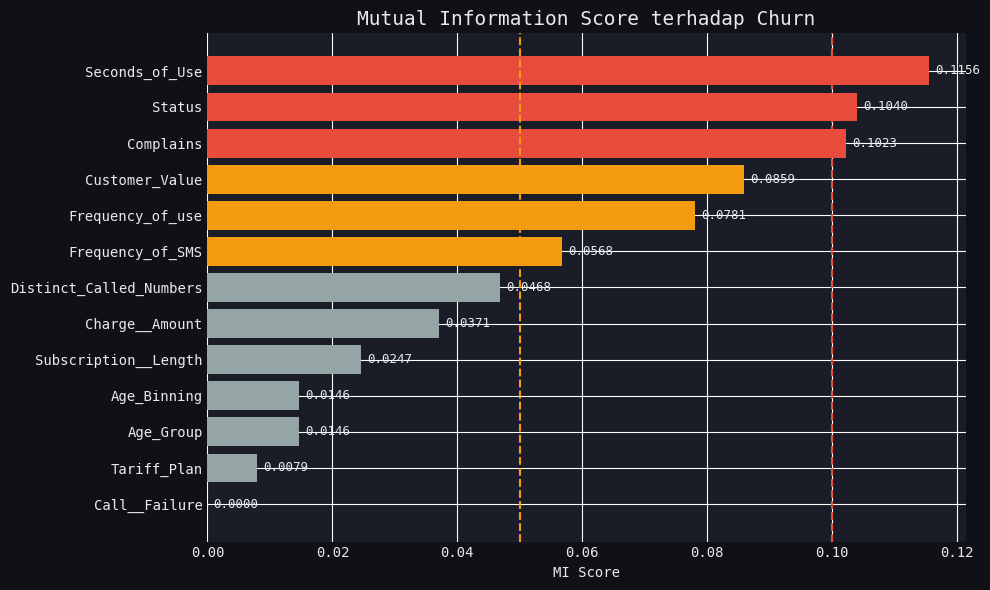

In [ ]:
colors = ['#e74c3c' if v >= 0.1 else '#f39c12' if v >= 0.05 else '#95a5a6'
          for v in mi_df['MI_Score']]

plt.figure(figsize=(10, 6))
bars = plt.barh(mi_df['Fitur'], mi_df['MI_Score'], color=colors)

# Garis batas
plt.axvline(x=0.05, color='#f39c12', linestyle='--', linewidth=1.5, label='Batas Sedang (0.05)')
plt.axvline(x=0.10, color='#e74c3c', linestyle='--', linewidth=1.5, label='Batas Tinggi (0.10)')

# Nilai di ujung bar
for bar, val in zip(bars, mi_df['MI_Score']):
    plt.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=9)

plt.xlabel('MI Score')
plt.title('Mutual Information Score terhadap Churn', fontsize=14)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
# Gabungkan MI dengan korelasi terhadap Churn
corr_churn = df.corr(method='spearman')['Churn'].drop('Churn').abs().reset_index()
corr_churn.columns = ['Fitur', 'Korelasi_Churn']

comparison = mi_df.merge(corr_churn, on='Fitur')
comparison = comparison.sort_values('MI_Score', ascending=False)

print("Perbandingan MI Score vs Korelasi terhadap Churn:")
print(comparison.to_string(index=False))

Perbandingan MI Score vs Korelasi terhadap Churn:
                  Fitur  MI_Score  Korelasi_Churn
         Seconds_of_Use  0.115611        0.360390
                 Status  0.104020        0.492867
              Complains  0.102323        0.546055
         Customer_Value  0.085929        0.353766
       Frequency_of_use  0.078089        0.335867
       Frequency_of_SMS  0.056847        0.214806
Distinct_Called_Numbers  0.046791        0.290830
         Charge__Amount  0.037092        0.247834
   Subscription__Length  0.024656        0.033052
            Age_Binning  0.014585        0.004854
              Age_Group  0.014585        0.004854
            Tariff_Plan  0.007919        0.106000
          Call__Failure  0.000000        0.014686


# C. Validasi Multikolinearitas Lanjutan

In [ ]:
def cek_korelasi_tinggi(df, threshold=0.80):
    corr = df.drop(columns=['Churn']).corr(method= 'spearman').abs()
    pasangan = []
    cols = corr.columns.tolist()

    for i in range(len(cols)):
        for j in range(i+1, len(cols)):
            if corr.iloc[i, j] >= threshold:
                pasangan.append({
                    'Fitur A': cols[i],
                    'Fitur B': cols[j],
                    'Korelasi': round(corr.iloc[i, j], 3)
                })

    return pd.DataFrame(pasangan).sort_values('Korelasi', ascending=False)

pasangan_tinggi = cek_korelasi_tinggi(df, threshold=0.50)
print("Pasangan fitur dengan korelasi > 0.50:")
display(pasangan_tinggi)

Pasangan fitur dengan korelasi > 0.50:


,Fitur A,Fitur B,Korelasi
12,Age_Group,Age_Binning,1.000
3,Seconds_of_Use,Frequency_of_use,0.934
7,Frequency_of_use,Distinct_Called_Numbers,0.816
10,Frequency_of_SMS,Customer_Value,0.776
4,Seconds_of_Use,Distinct_Called_Numbers,0.752
6,Seconds_of_Use,Customer_Value,0.702
9,Frequency_of_use,Customer_Value,0.660
5,Seconds_of_Use,Status,0.585
0,Call__Failure,Charge__Amount,0.565
11,Distinct_Called_Numbers,Customer_Value,0.545


## VIF (Variance Inflation Factor)

In [ ]:
# Pisahkan fitur (tanpa target Churn)
X = df.drop(columns=['Churn'])

# Pastikan semua kolom numerik
X = X.select_dtypes(include='number')

In [ ]:
from statsmodels.tools.tools import add_constant

# 1. Tambahkan konstanta ke dalam dataframe X
X_vif = add_constant(X)

vif_data = pd.DataFrame()
# 2. Ambil nama kolom dari X_vif (akan ada tambahan kolom 'const')
vif_data['Fitur'] = X_vif.columns
vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i)
                   for i in range(X_vif.shape[1])]

# Urutkan dan buang baris 'const' karena kita tidak butuh nilai VIF untuk konstanta
vif_data = vif_data[vif_data['Fitur'] != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)

# Tambahkan label status (Fungsi Anda sudah benar)
def vif_status(v):
    if v > 10: return '🔴 Tinggi - Evaluasi fitur sebelum dihapus'
    elif v > 5: return '⚠️ Sedang - Perlu dipertimbangkan'
    else: return '✅ Aman'

vif_data['Status'] = vif_data['VIF'].apply(vif_status)
display(vif_data)

,Fitur,VIF,Status
0,Customer_Value,53.203847,🔴 Tinggi - Evaluasi fitur sebelum dihapus
1,Frequency_of_SMS,41.569974,🔴 Tinggi - Evaluasi fitur sebelum dihapus
2,Seconds_of_Use,22.107064,🔴 Tinggi - Evaluasi fitur sebelum dihapus
3,Frequency_of_use,18.365358,🔴 Tinggi - Evaluasi fitur sebelum dihapus
4,Age_Binning,14.939063,🔴 Tinggi - Evaluasi fitur sebelum dihapus
5,Age_Group,14.231633,🔴 Tinggi - Evaluasi fitur sebelum dihapus
6,Charge__Amount,3.228834,✅ Aman
7,Call__Failure,2.914572,✅ Aman
8,Distinct_Called_Numbers,2.436216,✅ Aman
9,Status,1.843859,✅ Aman


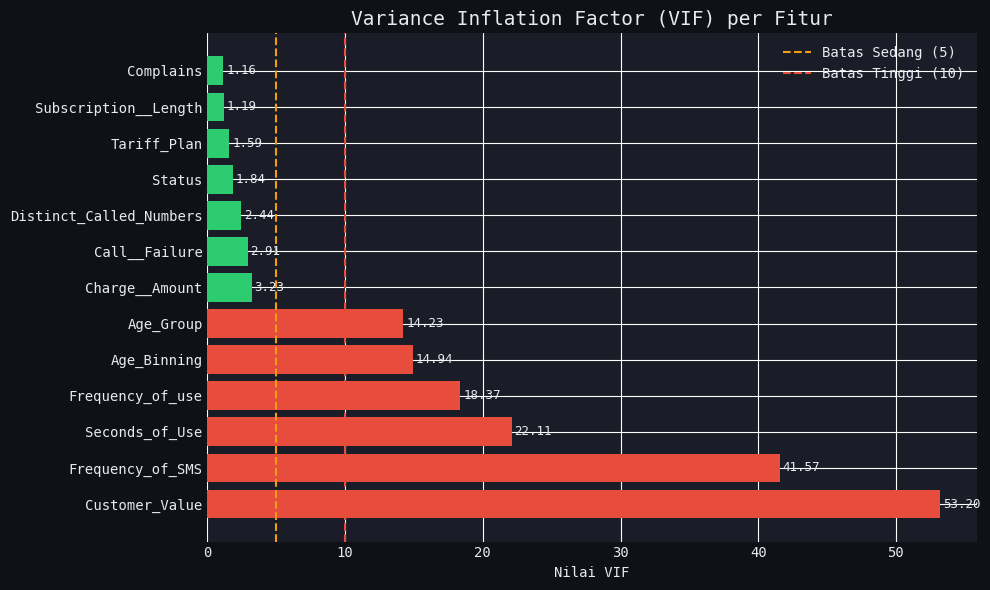

In [ ]:
colors = ['#e74c3c' if v > 10 else '#f39c12' if v > 5 else '#2ecc71'
          for v in vif_data['VIF']]

plt.figure(figsize=(10, 6))
bars = plt.barh(vif_data['Fitur'], vif_data['VIF'], color=colors)

# Garis batas
plt.axvline(x=5,  color='#f39c12', linestyle='--', linewidth=1.5, label='Batas Sedang (5)')
plt.axvline(x=10, color='#e74c3c', linestyle='--', linewidth=1.5, label='Batas Tinggi (10)')

# Tambahkan nilai di ujung bar
for bar, val in zip(bars, vif_data['VIF']):
    plt.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
             f'{val:.2f}', va='center', fontsize=9)

plt.xlabel('Nilai VIF')
plt.title('Variance Inflation Factor (VIF) per Fitur', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

## Kesimpulan Uji Multikolinearitas (Korelasi & VIF)

Analisis multikolinearitas dilakukan melalui dua tahap validasi: pendeteksian pola visual menggunakan matriks korelasi dan pengukuran kuantitatif menggunakan metode *Variance Inflation Factor* (VIF). Keberadaan multikolinearitas yang tinggi dapat mengganggu performa dan interpretasi beberapa algoritma *Machine Learning*.

Berdasarkan penggabungan kedua hasil uji tersebut, ditarik kesimpulan sebagai berikut:

### 1. Tiga Kluster Redundansi Kritis (Wajib Ditangani)
Terdapat tiga pasangan fitur yang secara konsisten menunjukkan korelasi sangat tinggi (> 0.80) dan divalidasi oleh skor VIF yang berada di zona merah (VIF > 10):

*   **Kluster Demografi (`Age_Group` & `Age_Binning`):**
    *   *Korelasi:* 0.96 | *VIF:* ~14.9 & ~14.2 (Pada uji sebelumnya yang lebih luas bernilai > 150)
    *   *Insight:* Hampir pasti merupakan duplikasi fitur mutlak. `Age_Binning` adalah hasil ordinal/pengelompokan dari `Age_Group`. Salah satu wajib dihapus.
*   **Kluster Intensitas Penggunaan (`Seconds_of_Use` & `Frequency_of_use`):**
    *   *Korelasi:* 0.94 | *VIF:* ~22.1 & ~18.3
    *   *Insight:* Keduanya mengukur metrik yang ekuivalen. Pelanggan dengan frekuensi panggilan tinggi secara otomatis mengakumulasi durasi yang tinggi. Menggunakan keduanya secara bersamaan akan menyebabkan informasi tumpang tindih.
*   **Kluster Nilai Pelanggan (`Customer_Value` & `Frequency_of_SMS`):**
    *   *Korelasi:* 0.92 | *VIF:* ~53.2 & ~41.5
    *   *Insight:* Mengonfirmasi hipotesis bahwa `Customer_Value` adalah metrik turunan (rumus formula) yang dihitung langsung dari intensitas layanan, salah satunya `Frequency_of_SMS`. Keduanya tidak boleh berada di dalam satu model secara bersamaan.

### 2. Fitur dengan Asosiasi Menengah (Aman Dipertahankan)
Beberapa fitur memiliki korelasi menengah di Heatmap, namun uji VIF membuktikan bahwa fitur tersebut tidak melanggar ambang batas multikolinearitas (VIF < 5):
*   **`Distinct_Called_Numbers` (VIF 2.4):** Walaupun berkorelasi menengah (0.67 - 0.73) dengan fitur *usage* lainnya, fitur ini terbukti mandiri secara perhitungan regresi dan aman dipertahankan.
*   **`Call__Failure` (VIF 2.9):** Korelasi menengahnya dengan `Frequency_of_use` (0.56) terbukti bersifat semu (*spurious*). Kegagalan panggil yang tinggi terjadi hanya karena probabilitas (frekuensi) meneleponnya juga tinggi. Fitur ini aman secara VIF, meskipun evaluasi sebelumnya (Bivariate/PBR) menunjukkan fitur ini minim daya prediksi terhadap target.

### Keputusan Aksi (Feature Selection)
Untuk membangun model yang efisien, berdimensi rendah, dan terhindar dari *noise*, fitur-fitur redundan dari kluster kritis di atas harus disaring. Keputusan final (*drop*) akan ditentukan dengan mengutamakan fitur yang memiliki nilai korelasi lebih tinggi terhadap metrik target (`Churn`), atau dapat diuji silang terlebih dahulu terhadap metrik evaluasi model awal sebelum dieksekusi secara permanen.

# **Kesimpulan Akhir Analisis Hubungan & Seleksi Fitur**

Analisis ini menggunakan enam metode komprehensif dengan peran berbeda: **Spearman** dan **Pearson** (heatmap korelasi antar-fitur), **Point-Biserial** (korelasi linear fitur numerik vs Churn), **Kruskal-Wallis** (uji non-linear), **Cramér's V** (asosiasi kategorikal, bias-corrected), **Variance Inflation Factor / VIF** (uji multikolinearitas murni), serta **Mutual Information / MI** (pengukuran *Information Gain* total, dihitung dengan `discrete_features` eksplisit untuk fitur kategorikal/ordinal).

### 1. Fitur dengan Hubungan Kuat terhadap Churn
| Fitur | Point-Biserial | Cramér's V | Mutual Info (MI) | Catatan |
|---|---|---|---|---|
| Seconds_of_Use | -0.296 | - | 0.116 | Peringkat #1 pada MI (Sinyal non-linear terkuat) |
| Status | +0.493 | 0.4915 | 0.104 | Prediktor kategorik terkuat |
| Complains | +0.546 | 0.5441 | 0.102 | Konsisten kuat di semua uji statistik |

Ketiga fitur ini adalah prediktor absolut. MI membuktikan bahwa di balik korelasi linearnya yang menengah, `Seconds_of_Use` menyimpan kekuatan prediktif non-linear tertinggi, sehingga wajib dipertahankan.

### 2. Validasi Multikolinearitas & Kluster Fitur Pemakaian (VIF > 10)

*Catatan metodologis: VIF diukur murni untuk mendeteksi redundansi linear antar-fitur secara eksploratif. Model final yang direncanakan nanti menangani multikolinearitas secara native, sehingga hasil VIF di bawah ini digunakan sebagai bahan pertimbangan feature selection, bukan sebagai perintah drop otomatis. Keputusan eksekusi final ada di section 6.*

Uji matriks korelasi (> 0.80) yang divalidasi secara kuantitatif dengan skor VIF membuktikan adanya tiga kluster redundansi kritis:
*   **Kluster Demografi (`Age_Group` & `Age_Binning`):** Korelasi sempurna 0.96 dengan VIF masing-masing sekitar 14.2 dan 14.9. Merupakan duplikasi mutlak format data.
*   **Kluster Intensitas Penggunaan (`Seconds_of_Use` & `Frequency_of_use`):** Korelasi 0.94 dengan VIF tinggi (`Seconds_of_Use` sekitar 22.1 dan `Frequency_of_use` sekitar 18.3). Informasi keduanya tumpang tindih.
*   **Kluster Nilai Pelanggan (`Customer_Value` & `Frequency_of_SMS`):** Korelasi 0.92 dengan VIF paling ekstrem (`Customer_Value` sekitar 53.2 dan `Frequency_of_SMS` sekitar 41.5). Mengonfirmasi bahwa `Customer_Value` adalah metrik turunan (*composite*).

### 3. Fitur yang Terbukti Aman dari Multikolinearitas (VIF < 5)
Meskipun beberapa fitur menunjukkan korelasi menengah secara visual, uji VIF membuktikan bahwa fitur-fitur berikut mandiri secara regresi dan tidak memicu multikolinearitas:
*   **`Distinct_Called_Numbers` (VIF 2.4):** Aman dari multikolinearitas menurut VIF, meski berkorelasi menengah (0.75-0.82) dengan `Seconds_of_Use` dan `Frequency_of_use` pada uji clustering korelasi terpisah (lihat FASE 5). **Fitur ini TIDAK di-drop**, karena VIF rendah adalah pembenaran cukup untuk mempertahankannya (lihat revisi section 6).
*   **`Call__Failure` (VIF 2.9):** Korelasi menengah sebelumnya terbukti bersifat semu (*spurious*) karena frekuensi panggil, namun secara VIF ia aman.
*   **`Charge__Amount`, `Tariff_Plan`, `Subscription__Length`, `Status`, & `Complains`:** Seluruhnya berada di zona aman VIF < 5.

### 4. Fitur Lemah dan Tanpa Hubungan Sama Sekali
*   **Fitur Lemah:** `Charge__Amount` (r = -0.20) dan `Tariff_Plan` (r = -0.11) memiliki korelasi rendah dan skor MI yang marginal (< 0.04). `Subscription__Length` memiliki efek yang sangat kecil dan tidak konsisten di uji non-linear.
*   **Noise Mutlak:** `Call__Failure` tidak lolos uji linear maupun non-linear, diperkuat oleh skor MI yang bernilai **0.000000** (tidak ada informasi sama sekali terhadap *Churn*).
*   **Kasus Khusus, `Age_Group` (dan `Age_Binning`):** Point-Biserial (r=-0.006, p=0.75), Kruskal-Wallis (p=0.80), dan MI (0.0146) seluruhnya menyatakan **tidak ada hubungan**. Namun **Cramér's V bias-corrected mendeteksi asosiasi Sedang dan signifikan (V=0.1304, p<0.001)**. Kontradiksi ini bukan kesalahan pengukuran, melainkan indikasi pola **non-monoton (U-terbalik)**: kelompok usia termuda dan tertua sama-sama churn rendah, sementara kelompok tengah berisiko lebih tinggi.
*   **Kasus Serupa, `Tariff_Plan`:** Point-Biserial menilainya lemah (r=-0.11), tapi Cramér's V bias-corrected menilainya Sedang (V=0.1025), pas di batas bawah kategori. Berbeda dari `Age_Group`, di sini kontribusi churn-nya sangat timpang (98.7% churn terkonsentrasi di Plan 1, n=2621, dibanding Plan 2, n=229), sehingga asosiasi Cramér's V kemungkinan besar didorong oleh ketidakseimbangan proporsi sampel antar level, bukan pola non-monoton yang bermakna seperti `Age_Group`.

### 5. Redundansi Fitur Kategorik

Cramér's V (bias-corrected) mendeteksi dua pasangan asosiasi kuat antar-fitur kategorik:

*   **`Age_Group` x `Age_Binning` (V = 1.0000):** duplikasi sempurna, sudah dikonfirmasi dari korelasi Spearman 1.00 sebelumnya. Temuan ini solid meski turut ditandai expected count kurang dari 5 (wajar, karena keduanya representasi identik dari data yang sama, bukan indikasi masalah data).
*   **`Status` x `Charge__Amount` (V = 0.5022):** redundan, tapi ditandai tidak reliabel (ada sel tabel kontingensi dengan expected count kurang dari 5, kemungkinan besar akibat level `Charge__Amount` 5 sampai 10 yang bersampel sangat kecil, 7 sampai 30 baris). Temuan ini tetap dicatat sebagai indikasi, bukan bukti kuat, dan tidak dijadikan dasar tunggal untuk keputusan drop `Charge__Amount`.

### 6. Rekomendasi Kandidat Feature Selection (Bukan Eksekusi Otomatis)

Catatan: *daftar ini adalah kandidat hasil sintesis EDA, bukan keputusan final yang langsung dieksekusi. Keputusan drop permanen akan divalidasi ulang di notebook selanjutnya melalui uji performa (cross-validation dengan/tanpa fitur).*

| Fitur | Status | Alasan |
|---|---|---|
| `Age_Binning` | Kandidat drop | Duplikat mutlak 100% dari `Age_Group` (VIF tinggi, Cramér's V=1.0 antar keduanya). Simpan salah satu saja. |
| `Age_Group` | Kandidat drop | MI dan PB nyaris nol; meski Cramér's V menunjukkan pola non-monoton (lihat section 4), sinyalnya kemungkinan hanya sampel kecil di ekor distribusi. |
| `Frequency_of_use` | Kandidat drop | Multikolinearitas tinggi dengan `Seconds_of_Use` (VIF 18 sampai 22, korelasi 0.94); `Seconds_of_Use` dipertahankan karena MI lebih unggul (0.116 vs 0.078). |
| `Frequency_of_SMS` | Kandidat drop | Multikolinearitas tinggi (VIF di atas 40) dengan `Customer_Value`; namun perlu dicek ulang di FASE 5, karena analisis clustering korelasi terpisah menunjukkan `Frequency_of_SMS` justru TIDAK satu klaster dengan `Seconds_of_Use`/`Frequency_of_use` (korelasi hanya 0.29 sampai 0.30). VIF tinggi di sini murni karena hubungannya dengan `Customer_Value`, bukan dengan klaster pemakaian. |
| `Distinct_Called_Numbers` | **Dipertahankan** | VIF aman (2.4), MI moderat (0.047). Direvisi dari draft sebelumnya yang salah memasukkan fitur ini ke daftar drop meski tabel section 3 sendiri menyatakan aman. |
| `Call__Failure` | Kandidat drop | Terbukti murni sebagai *noise* di seluruh uji (PB, Kruskal-Wallis, MI=0.0). Ini fitur dengan bukti drop paling kuat di seluruh analisis. |
| `Charge__Amount` | Uji coba tahap model | Cramér's V (0.2444) menunjukkan sinyal Sedang, namun ditandai tidak reliabel akibat sampel kecil di level atas (lihat section 5). Skor lemah di metrik lain. Validasi dengan performa model sebelum diputuskan permanen. |
| `Tariff_Plan` | Uji coba tahap model | Point-Biserial lemah, tapi Cramér's V Sedang (0.1025), kemungkinan didorong ketimpangan sampel antar level (lihat section 4) bukan sinyal murni. Validasi dengan performa model sebelum diputuskan permanen. |

# **FASE 4: Deep Dive Business Insights**

# A. Bivariate Analysis: Single-Feature Segmentation

  CHURN RATE PER SEGMEN — SEMUA FITUR
  Rata-rata keseluruhan: 15.6%

── Complains
  Segmen                   Total   Churn    Rate    vs Avg
  ------------------------------------------------------
  1.0                        230     190   82.6% ↑ 67.0% ⚠
  0.0                       2620     256    9.8% ↓  5.9%

── Status
  Segmen                   Total   Churn    Rate    vs Avg
  ------------------------------------------------------
  2.0                        684     325   47.5% ↑ 31.9% ⚠
  1.0                       2166     121    5.6% ↓ 10.1%

── Tariff Plan
  Segmen                   Total   Churn    Rate    vs Avg
  ------------------------------------------------------
  1.0                       2621     440   16.8% ↑  1.1%
  2.0                        229       6    2.6% ↓ 13.0%

── Age Group
  Segmen                   Total   Churn    Rate    vs Avg
  ------------------------------------------------------
  4.0                        367      74   20.2% ↑  4.5%
  2.0    

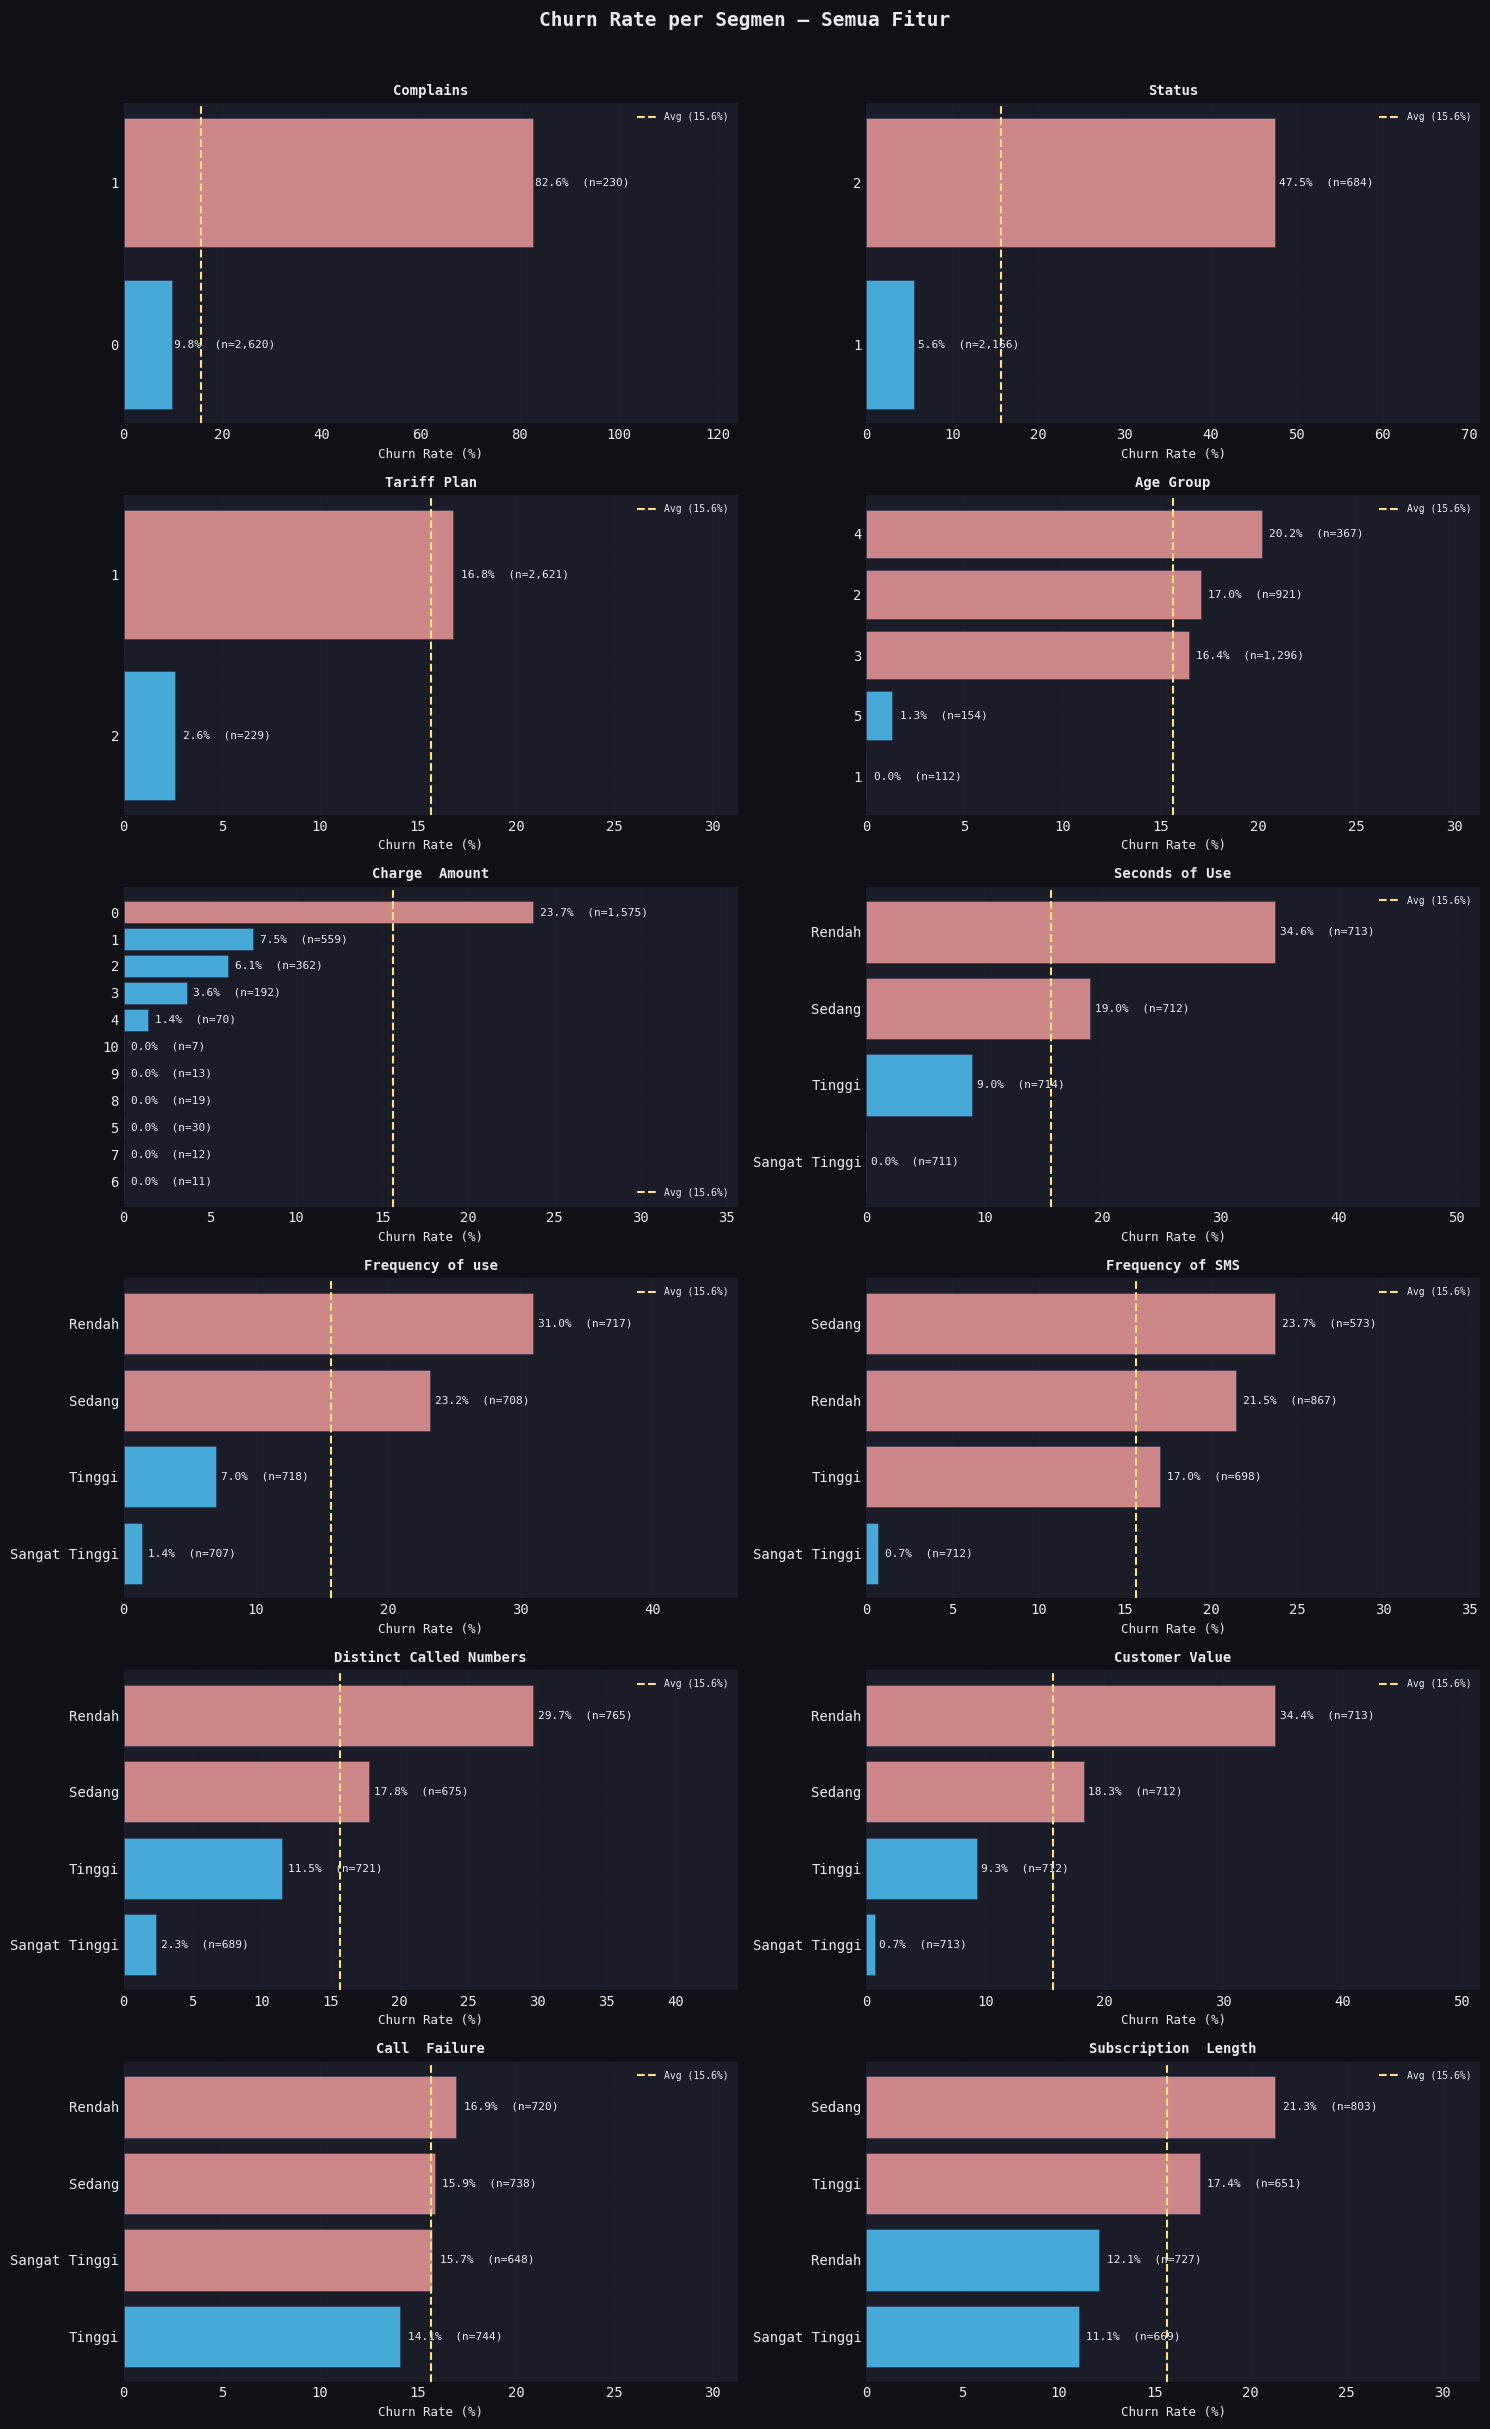


  SEGMEN BERISIKO TINGGI (Churn Rate > 1.5x rata-rata)
  Threshold: 15.6% x 1.5 = 23.5%

Fitur                        Segmen                    Rate      n   vs Avg
----------------------------------------------------------------------------
  Complains                  1.0                      82.6%    230    5.3x
  Status                     2.0                      47.5%    684    3.0x
  Seconds of Use             Rendah                   34.6%    713    2.2x
  Customer Value             Rendah                   34.4%    713    2.2x
  Frequency of use           Rendah                   31.0%    717    2.0x
  Distinct Called Numbers    Rendah                   29.7%    765    1.9x
  Charge  Amount             0.0                      23.7%  1,575    1.5x
  Frequency of SMS           Sedang                   23.7%    573    1.5x


In [ ]:
# Analisis: Segmentasi Semua Fitur vs Churn

from math import ceil

overall_churn = df[TARGET].mean()

COLOR_0 = "#4fc3f7"
COLOR_1 = "#ef9a9a"

# Pakai fungsi tema yang sudah didefinisikan di cell pertama notebook
BG_COLOR, PANEL_COLOR, TEXT_COLOR, GRID_COLOR = apply_dark_theme()


# ══════════════════════════════════════════════════════
# LANGKAH 1: Bin semua fitur numerik kontinu
# ══════════════════════════════════════════════════════

df_seg = df.copy()

# Definisi binning untuk fitur numerik
# n_bins=4 → Rendah / Sedang / Tinggi / Sangat Tinggi
NUMERIC_BINS = {
    'Seconds_of_Use':         4,
    'Frequency_of_use':       4,
    'Frequency_of_SMS':       4,
    'Distinct_Called_Numbers':4,
    'Customer_Value':         4,
    'Call__Failure':          4,
    'Subscription__Length':   4,
}

BIN_LABELS_4 = ['Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi']

for col, n in NUMERIC_BINS.items():
    if col not in df_seg.columns:
        continue
    new_col = col + '_bin'
    # qcut: bin berdasarkan kuantil agar tiap bin jumlahnya seimbang
    try:
        df_seg[new_col] = pd.qcut(
            df_seg[col], q=n,
            labels=BIN_LABELS_4[:n],
            duplicates='drop'
        )
    except Exception:
        df_seg[new_col] = pd.cut(
            df_seg[col], bins=n,
            labels=BIN_LABELS_4[:n]
        )

# Charge Amount sudah diskrit 0-10, bin manual lebih bermakna
if 'Charge__Amount' in df_seg.columns:
    df_seg['Charge__Amount_bin'] = pd.cut(
        df_seg['Charge__Amount'],
        bins=[-1, 0, 2, 5, 10],
        labels=['Level 0', 'Level 1-2', 'Level 3-5', 'Level 6-10']
    )


# ══════════════════════════════════════════════════════
# LANGKAH 2: Definisi semua segmen (kategorik + hasil bin)
# ══════════════════════════════════════════════════════

ALL_SEGMENTS = {
    # ── Kategorik asli
    'Complains':               {0: 'Tidak Komplain', 1: 'Pernah Komplain'},
    'Status':                  {1: 'Status 1',       2: 'Status 2'},
    'Tariff_Plan':             {1: 'Plan 1',          2: 'Plan 2'},
    'Age_Group':               {1: 'Usia 15th', 2: 'Usia 25th',
                                3: 'Usia 30th', 4: 'Usia 45th',
                                5: 'Usia 55th'},
    'Charge__Amount': {i: f'Level {i}' for i in range(11)},
    # ── Hasil binning numerik (pakai nama kolom _bin)
    'Seconds_of_Use_bin':          None,
    'Frequency_of_use_bin':        None,
    'Frequency_of_SMS_bin':        None,
    'Distinct_Called_Numbers_bin': None,
    'Customer_Value_bin':          None,
    'Call__Failure_bin':           None,
    'Subscription__Length_bin':    None,
}

# Filter hanya kolom yang ada
ALL_SEGMENTS = {k: v for k, v in ALL_SEGMENTS.items()
                if k in df_seg.columns}


# ══════════════════════════════════════════════════════
# LANGKAH 3: Tabel Churn Rate semua segmen
# ══════════════════════════════════════════════════════

print('=' * 68)
print('  CHURN RATE PER SEGMEN — SEMUA FITUR')
print(f'  Rata-rata keseluruhan: {overall_churn*100:.1f}%')
print('=' * 68)

for col in ALL_SEGMENTS:
    grp = (df_seg.groupby(col, observed=True)[TARGET]
           .agg(['sum', 'count', 'mean'])
           .reset_index())
    grp.columns = ['Segmen', 'Churn', 'Total', 'Rate']
    grp['Rate%']     = (grp['Rate'] * 100).round(1)
    grp['vs Avg']    = ((grp['Rate'] - overall_churn) * 100).round(1)
    grp = grp.sort_values('Rate%', ascending=False)

    print(f'\n── {col.replace("_bin","").replace("_"," ")}')
    print(f'  {"Segmen":<22} {"Total":>7} {"Churn":>7} {"Rate":>7} {"vs Avg":>9}')
    print('  ' + '-' * 54)
    for _, row in grp.iterrows():
        arrow = '↑' if row['vs Avg'] > 0 else '↓'
        flag  = ' ⚠' if row['Rate%'] > overall_churn * 100 * 1.5 else ''
        print(f'  {str(row["Segmen"]):<22} {int(row["Total"]):>7} '
              f'{int(row["Churn"]):>7} {row["Rate%"]:>6.1f}% '
              f'{arrow}{abs(row["vs Avg"]):>5.1f}%{flag}')


# ══════════════════════════════════════════════════════
# LANGKAH 4: Visualisasi Bar Chart semua segmen
# ══════════════════════════════════════════════════════

seg_list = list(ALL_SEGMENTS.keys())
n_cols   = 2
n_rows   = ceil(len(seg_list) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols,
                          figsize=(15, n_rows * 4),
                          facecolor=BG_COLOR)
axes = axes.flatten()
fig.suptitle('Churn Rate per Segmen — Semua Fitur',
             fontsize=14, fontweight='bold', y=1.01)

for idx, col in enumerate(seg_list):
    ax = axes[idx]

    grp = (df_seg.groupby(col, observed=True)[TARGET]
           .agg(['sum', 'count', 'mean'])
           .reset_index())
    grp.columns = ['Segmen', 'Churn', 'Total', 'Rate']
    grp['Rate%'] = grp['Rate'] * 100
    grp = grp.sort_values('Rate%', ascending=True)

    bar_colors = [COLOR_1 if r > overall_churn * 100 else COLOR_0
                  for r in grp['Rate%']]

    bars = ax.barh(grp['Segmen'].astype(str), grp['Rate%'],
                   color=bar_colors, edgecolor='#2e3250',
                   linewidth=0.5, alpha=0.85)

    for bar, rate, total in zip(bars, grp['Rate%'], grp['Total']):
        ax.text(bar.get_width() + 0.4,
                bar.get_y() + bar.get_height() / 2,
                f'{rate:.1f}%  (n={int(total):,})',
                va='center', ha='left', fontsize=8, color=TEXT_COLOR)

    ax.axvline(overall_churn * 100, color='#ffe082',
               linestyle='--', linewidth=1.5,
               label=f'Avg ({overall_churn*100:.1f}%)')

    title = col.replace('_bin', '').replace('_', ' ')
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_xlabel('Churn Rate (%)', fontsize=9)
    ax.set_xlim(0, max(grp['Rate%'].max() * 1.5, overall_churn * 100 * 2))
    ax.grid(True, axis='x', linestyle='--', alpha=0.15, color=GRID_COLOR)
    ax.grid(False, axis='y')
    ax.legend(fontsize=7, framealpha=0.15)

for idx in range(len(seg_list), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()


# ══════════════════════════════════════════════════════
# LANGKAH 5: Ringkasan Segmen Berisiko Tinggi
# ══════════════════════════════════════════════════════

print('\n' + '=' * 68)
print('  SEGMEN BERISIKO TINGGI (Churn Rate > 1.5x rata-rata)')
print(f'  Threshold: {overall_churn*100:.1f}% x 1.5 = {overall_churn*100*1.5:.1f}%')
print('=' * 68)

high_risk_all = []

for col in ALL_SEGMENTS:
    grp = (df_seg.groupby(col, observed=True)[TARGET]
           .agg(['mean', 'count'])
           .reset_index())
    grp.columns = ['Segmen', 'Rate', 'Total']
    high = grp[grp['Rate'] >= overall_churn * 1.5]

    for _, row in high.iterrows():
        high_risk_all.append({
            'Fitur':    col.replace('_bin','').replace('_',' '),
            'Segmen':   str(row['Segmen']),
            'Rate':     round(row['Rate'] * 100, 1),
            'Total':    int(row['Total']),
            'Multiplier': round(row['Rate'] / overall_churn, 1),
        })

hr_df = pd.DataFrame(high_risk_all).sort_values('Rate', ascending=False)

print(f'\n{"Fitur":<28} {"Segmen":<22} {"Rate":>7} {"n":>6} {"vs Avg":>8}')
print('-' * 76)
for _, r in hr_df.iterrows():
    print(f'  {r["Fitur"]:<26} {r["Segmen"]:<22} '
          f'{r["Rate"]:>6.1f}%  {r["Total"]:>5,}  '
          f'{r["Multiplier"]:>5.1f}x')

## **Analisis Segmentasi**

Analisis segmentasi dilakukan terhadap seluruh fitur untuk mengidentifikasi
kelompok pelanggan mana yang memiliki risiko churn tertinggi. Fitur numerik
kontinu dibagi menjadi empat kuartil (Rendah, Sedang, Tinggi, Sangat Tinggi)
menggunakan quantile-based binning agar setiap kelompok memiliki jumlah
pelanggan yang proporsional. Rata-rata churn rate keseluruhan adalah 15.6%
dan digunakan sebagai garis pembanding di seluruh analisis.

---

### **Fitur Kategorik**

**`Complains`**

Ini adalah temuan paling signifikan di seluruh dataset. Pelanggan yang
pernah melakukan komplain memiliki churn rate 82.6%, atau 5.3x lebih
tinggi dari rata-rata. Dari 230 pelanggan yang pernah komplain, 190 di
antaranya akhirnya churn. Sebaliknya, pelanggan yang tidak pernah komplain
hanya memiliki churn rate 9.8%. Selisih 72.8 poin persentase ini menjadikan
Complains sebagai sinyal churn tunggal terkuat di seluruh dataset.

**`Status`**

Pelanggan dengan Status 2 memiliki churn rate 47.5%, atau 3.0x lebih
tinggi dari rata-rata, dengan total 684 pelanggan di segmen ini. Status 1
sebaliknya sangat aman dengan churn rate hanya 5.6%. Perbedaan ini sangat
signifikan dan mengindikasikan bahwa Status 2 kemungkinan merepresentasikan
kondisi kontrak atau layanan tertentu yang berkorelasi kuat dengan
ketidakpuasan pelanggan. Tim bisnis perlu menginvestigasi lebih lanjut apa
yang membedakan kedua status ini, misalnya apakah ada kendala teknis,
kesulitan pembayaran, atau rendahnya pemahaman produk yang menyebabkan
pelanggan beralih dari Status 1 ke Status 2.

**`Tariff Plan`**

Plan 1 memiliki churn rate 16.8%, sedikit di atas rata-rata, sementara
Plan 2 hanya 2.6%. Namun perlu diperhatikan bahwa Plan 2 hanya memiliki
229 pelanggan (8% dari total) sehingga interpretasi harus dilakukan dengan
hati-hati karena ukuran sampelnya sangat kecil.

**`Age Group`**

Tidak ada pola yang jelas dan konsisten berdasarkan usia. Grup usia 45
tahun memiliki churn rate tertinggi (20.2%) namun selisihnya dari rata-rata
hanya 4.5 poin. Grup usia termuda (15 tahun, n=112) memiliki churn rate 0%
dan grup tertua (55 tahun, n=154) hanya 1.3%, namun kedua kelompok ini
memiliki sampel yang sangat kecil sehingga tidak dapat dijadikan kesimpulan
yang kuat. Secara linear/rank, usia pelanggan tidak menunjukkan hubungan yang bermakna terhadap churn (FASE 3). Namun, pola yang tampak di sini (grup termuda dan tertua paling aman, grup tengah paling berisiko) konsisten dengan temuan Cramér's V bias-corrected (FASE 3) yang mendeteksi asosiasi non-monoton (U-terbalik) bersifat Sedang dan signifikan secara statistik. Sinyal ini tetap perlu diperlakukan hati-hati karena didorong oleh dua segmen ekor bersampel kecil (n=112 dan n=154)

**`Charge Amount`**

Pola yang sangat jelas terlihat: semakin tinggi level tagihan, semakin
rendah churn rate. Level 0 yang berarti tidak dikenakan tagihan memiliki
churn rate tertinggi yaitu 23.7% dengan 1.575 pelanggan, sedangkan Level 5
ke atas semuanya memiliki churn rate 0%. Ini mengindikasikan bahwa
pelanggan dengan tagihan lebih tinggi adalah pengguna aktif yang lebih
terikat dan loyal terhadap layanan.

---

### **Fitur Numerik (Hasil Binning Kuartil)**

**`Seconds of Use` dan `Frequency of Use`**

Keduanya menunjukkan pola yang sangat konsisten: semakin rendah penggunaan,
semakin tinggi risiko churn. Pelanggan dengan Seconds of Use Rendah memiliki
churn rate 34.6% dan Frequency of Use Rendah 31.0%, sedangkan pelanggan
dengan penggunaan Sangat Tinggi masing-masing 0% dan 1.4%. Pola gradien
yang sempurna ini menunjukkan bahwa tingkat aktivitas penggunaan layanan
adalah salah satu prediktor churn yang paling handal di dataset ini.

**`Customer Value`**

Pola yang identik dengan fitur usage. Segmen Rendah memiliki churn rate
34.4% sedangkan Sangat Tinggi hanya 0.7%. Pola ini konsisten dengan
temuan pada fitur penggunaan lainnya, yaitu pelanggan bernilai rendah
adalah pelanggan tidak aktif yang berisiko tinggi churn.

**`Distinct Called Numbers`**

Pola serupa dengan fitur usage lainnya. Segmen Rendah memiliki churn rate
29.7% sedangkan Sangat Tinggi hanya 2.3%. Pelanggan dengan jaringan kontak
yang lebih luas cenderung lebih terikat dengan layanan dan lebih loyal.

**`Frequency of SMS`**

Pola sedikit berbeda dibanding fitur usage lainnya. Segmen Sedang justru
memiliki churn rate tertinggi (23.7%), lebih tinggi dari segmen Rendah
(21.5%). Ini mengindikasikan hubungan yang tidak sepenuhnya linear antara
frekuensi SMS dan churn. Namun segmen Sangat Tinggi tetap memiliki churn
rate sangat rendah (0.7%), konsisten dengan pola fitur usage lainnya.

**`Subscription Length`**

Pola tidak linear dan berbeda dari ekspektasi. Segmen Sedang justru
memiliki churn rate tertinggi (21.3%), bukan segmen Rendah (12.1%).
Pelanggan dengan masa langganan Sangat Tinggi justru lebih aman (11.1%).
Kemungkinan ada interaksi dengan fitur lain seperti Status dan Complains
yang menutupi efek langsung dari durasi langganan, dan akan diinvestigasi lebih lanjut pada analisis kombinasi dua fitur (Section B)

**`Call Failure`**

Churn rate hampir identik di semua segmen, berkisar antara 14.1% hingga
16.9%, tanpa pola yang bermakna. Ini menunjukkan bahwa Call Failure tidak
memiliki hubungan yang bermakna dengan churn di dataset ini dan menjadi
kandidat untuk dipertimbangkan pada tahap feature selection.

---

### **Ringkasan Segmen Berisiko Tinggi**

Delapan segmen teridentifikasi memiliki churn rate di atas 1.5x rata-rata:

| Segmen | Churn Rate | Multiplier |
|---|---|---|
| Complains = Pernah Komplain | 82.6% | 5.3x |
| Status = Status 2 | 47.5% | 3.0x |
| Seconds of Use = Rendah | 34.6% | 2.2x |
| Customer Value = Rendah | 34.4% | 2.2x |
| Frequency of Use = Rendah | 31.0% | 2.0x |
| Distinct Called Numbers = Rendah | 29.7% | 1.9x |
| Frequency of SMS = Sedang | 23.7% | 1.5x |
| Charge Amount = Level 0 | 23.7% | 1.5x |


# B. Multivariate Analysis: Cross-Segmentation

## Analisis Kombinasi Dua Fitur: Heatmap Churn Rate dan Ranking Segmen Ekstrem

Heatmap berikut menampilkan churn rate untuk seluruh kombinasi dua fitur (kategorik x kategorik, kategorik x numerik, dan numerik x numerik) tanpa filter statistik lanjutan selain minimum sampel per sel. Tujuannya sebagai eksplorasi visual awal untuk melihat pola secara menyeluruh. Interpretasi rinci dan tervalidasi (dengan uji stabilitas train/test serta signifikansi statistik) dibahas pada section berikutnya, "Uji Validitas Kombinasi Dua Fitur".

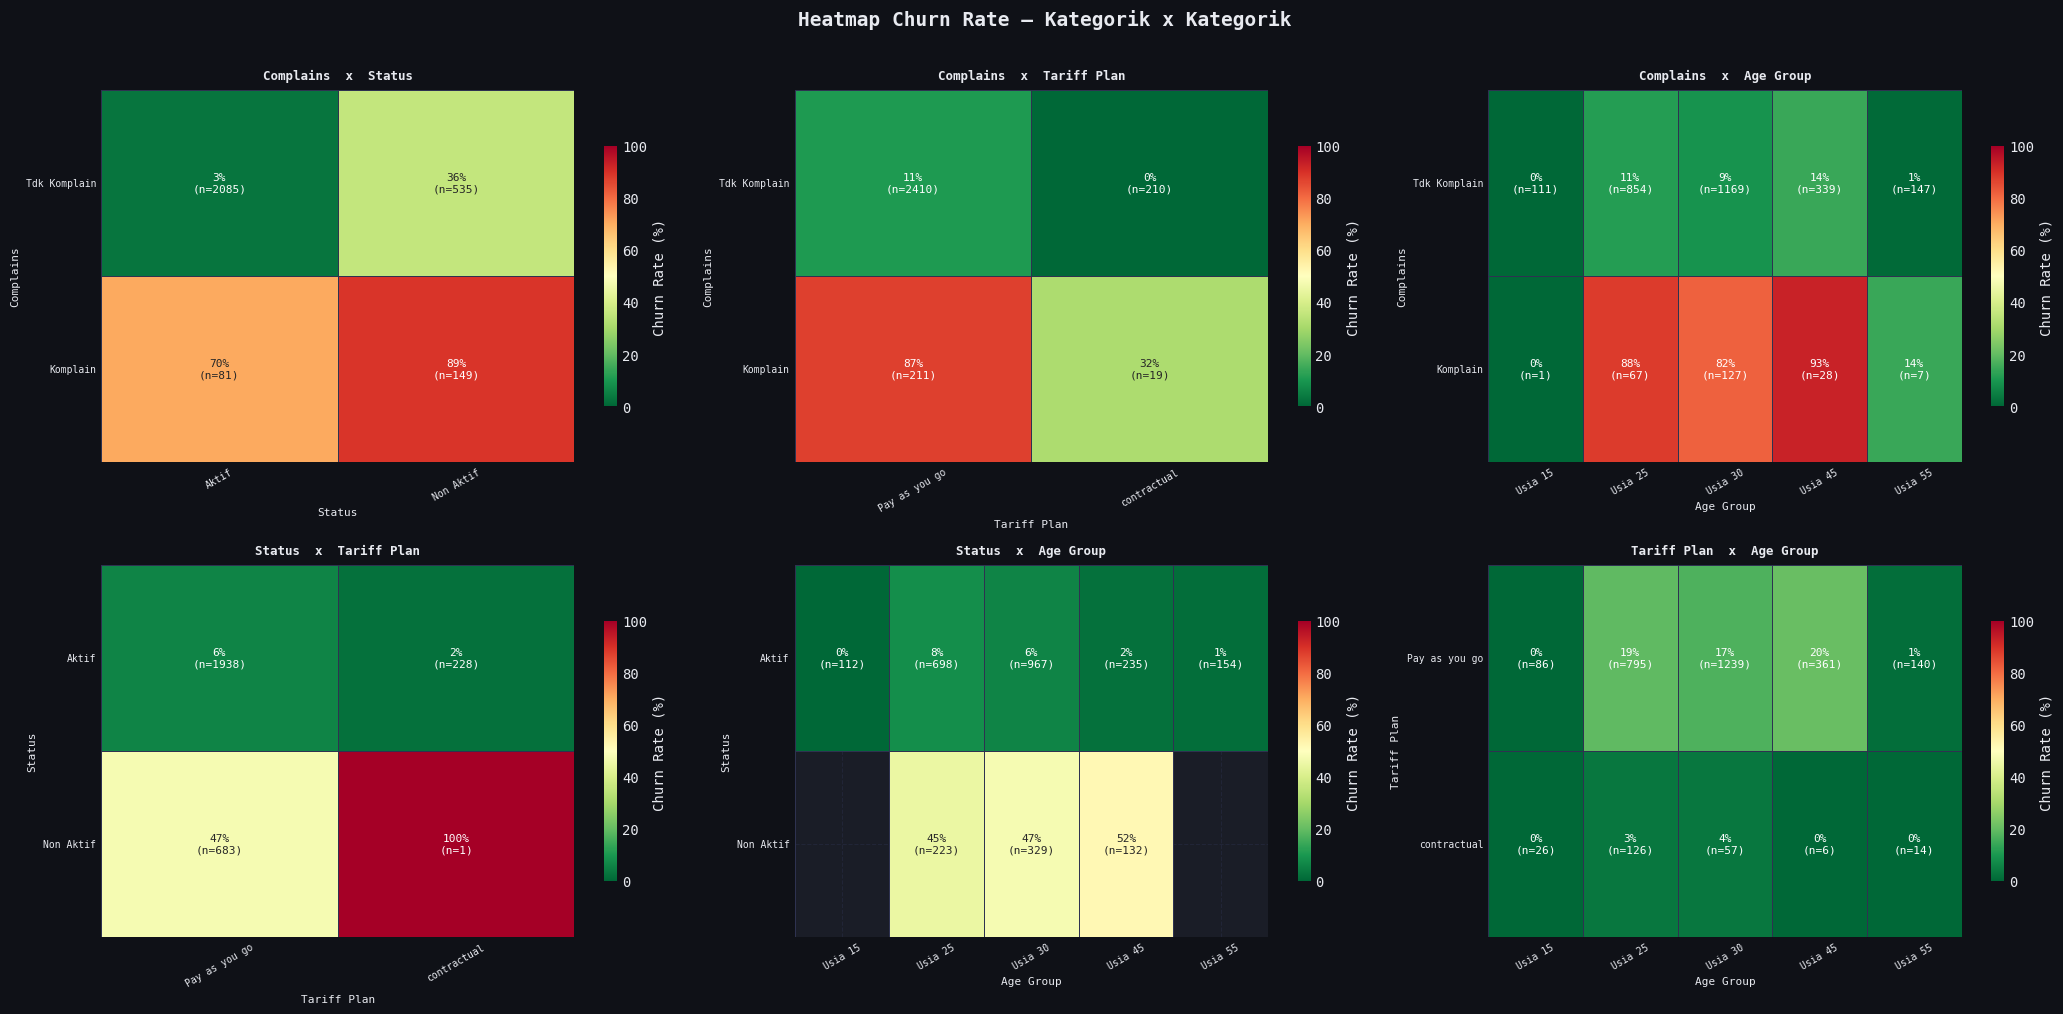

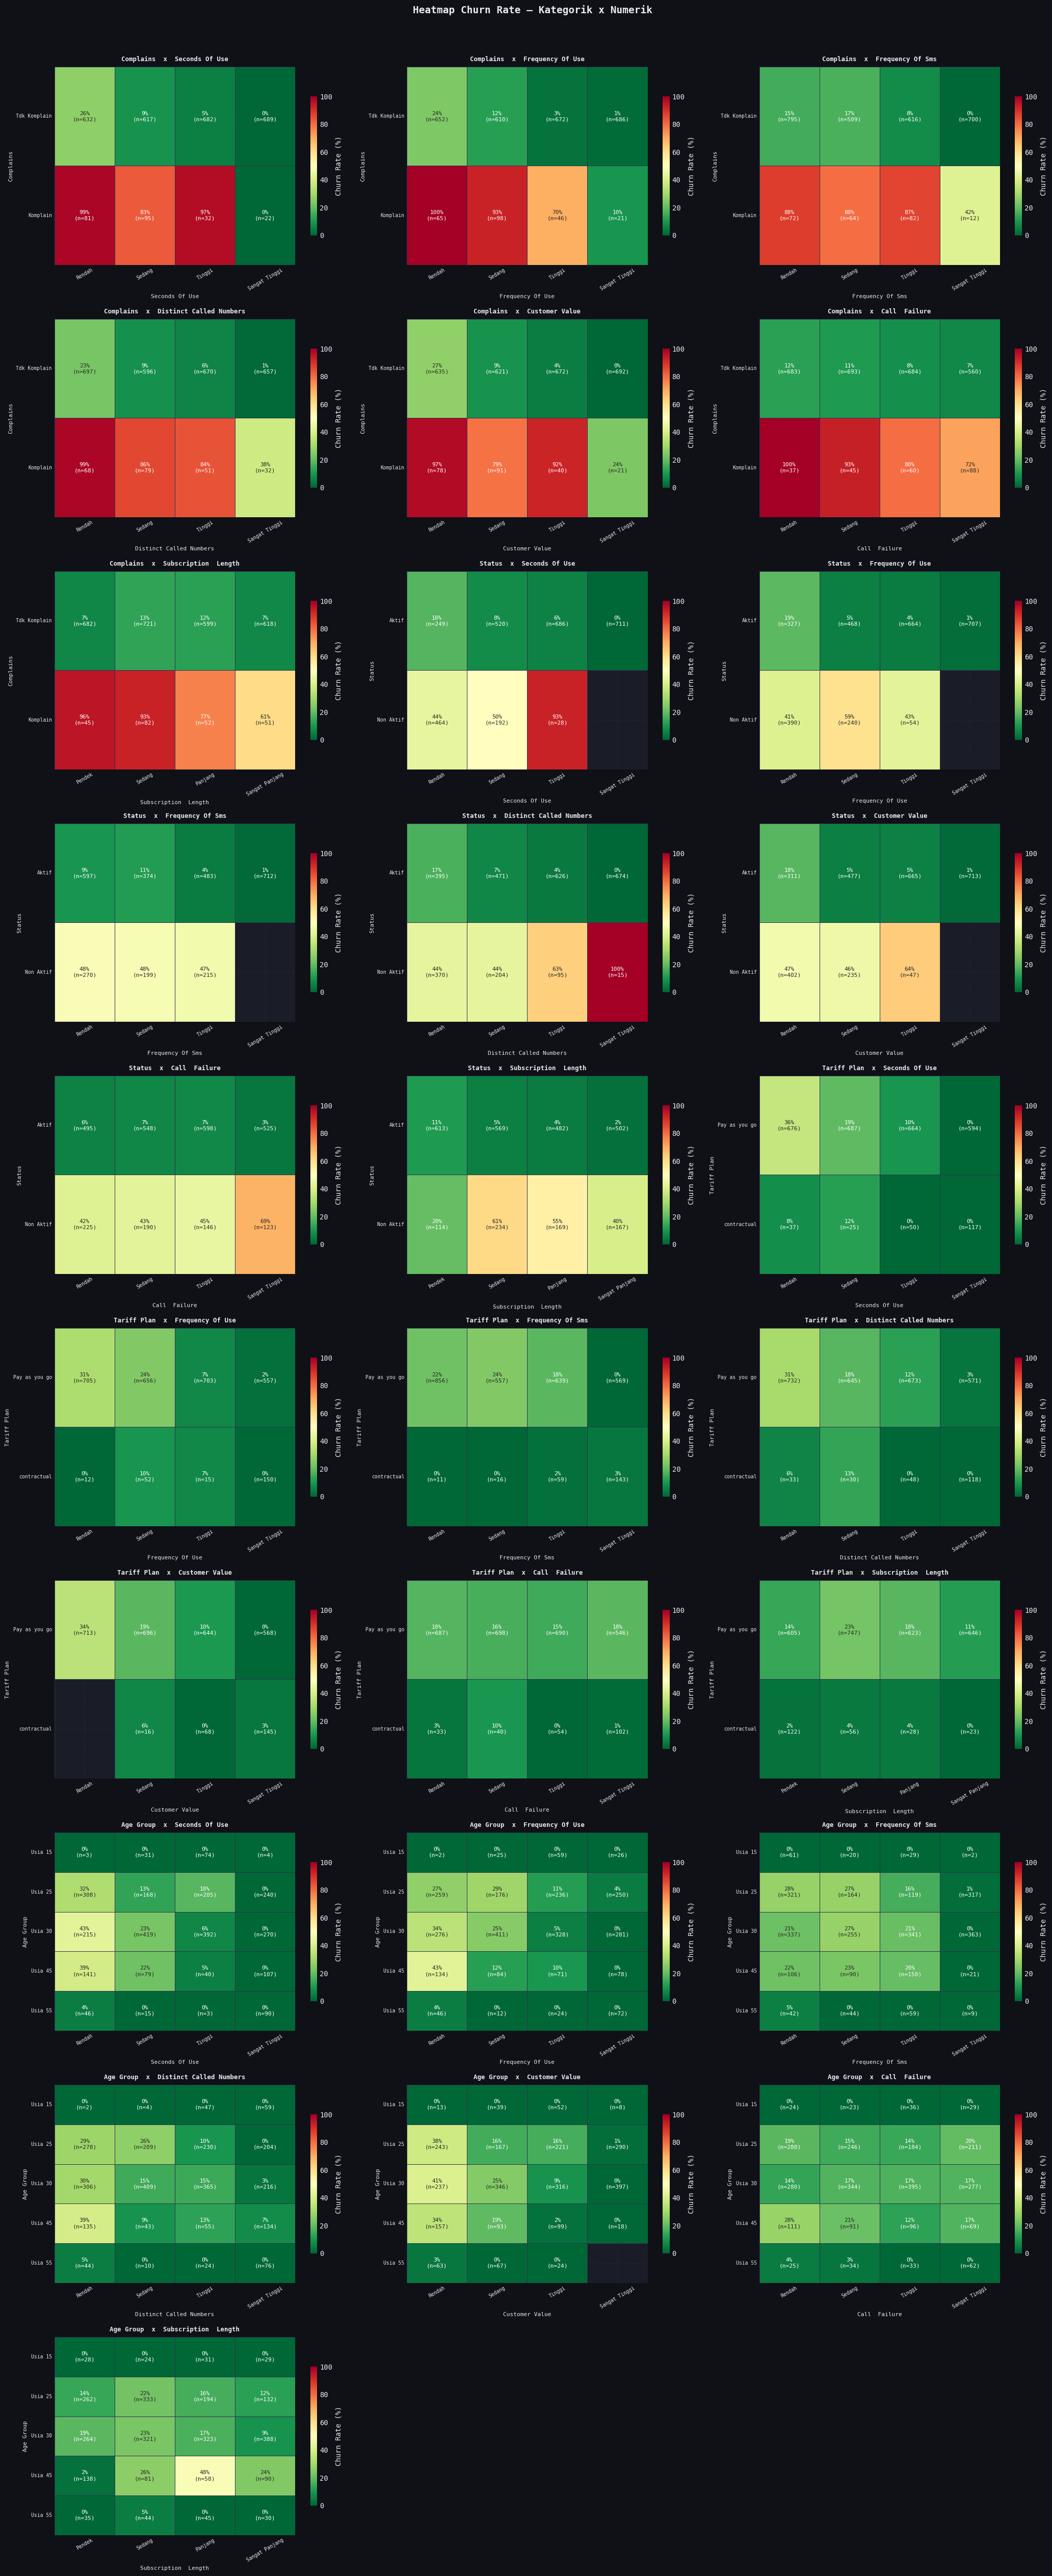

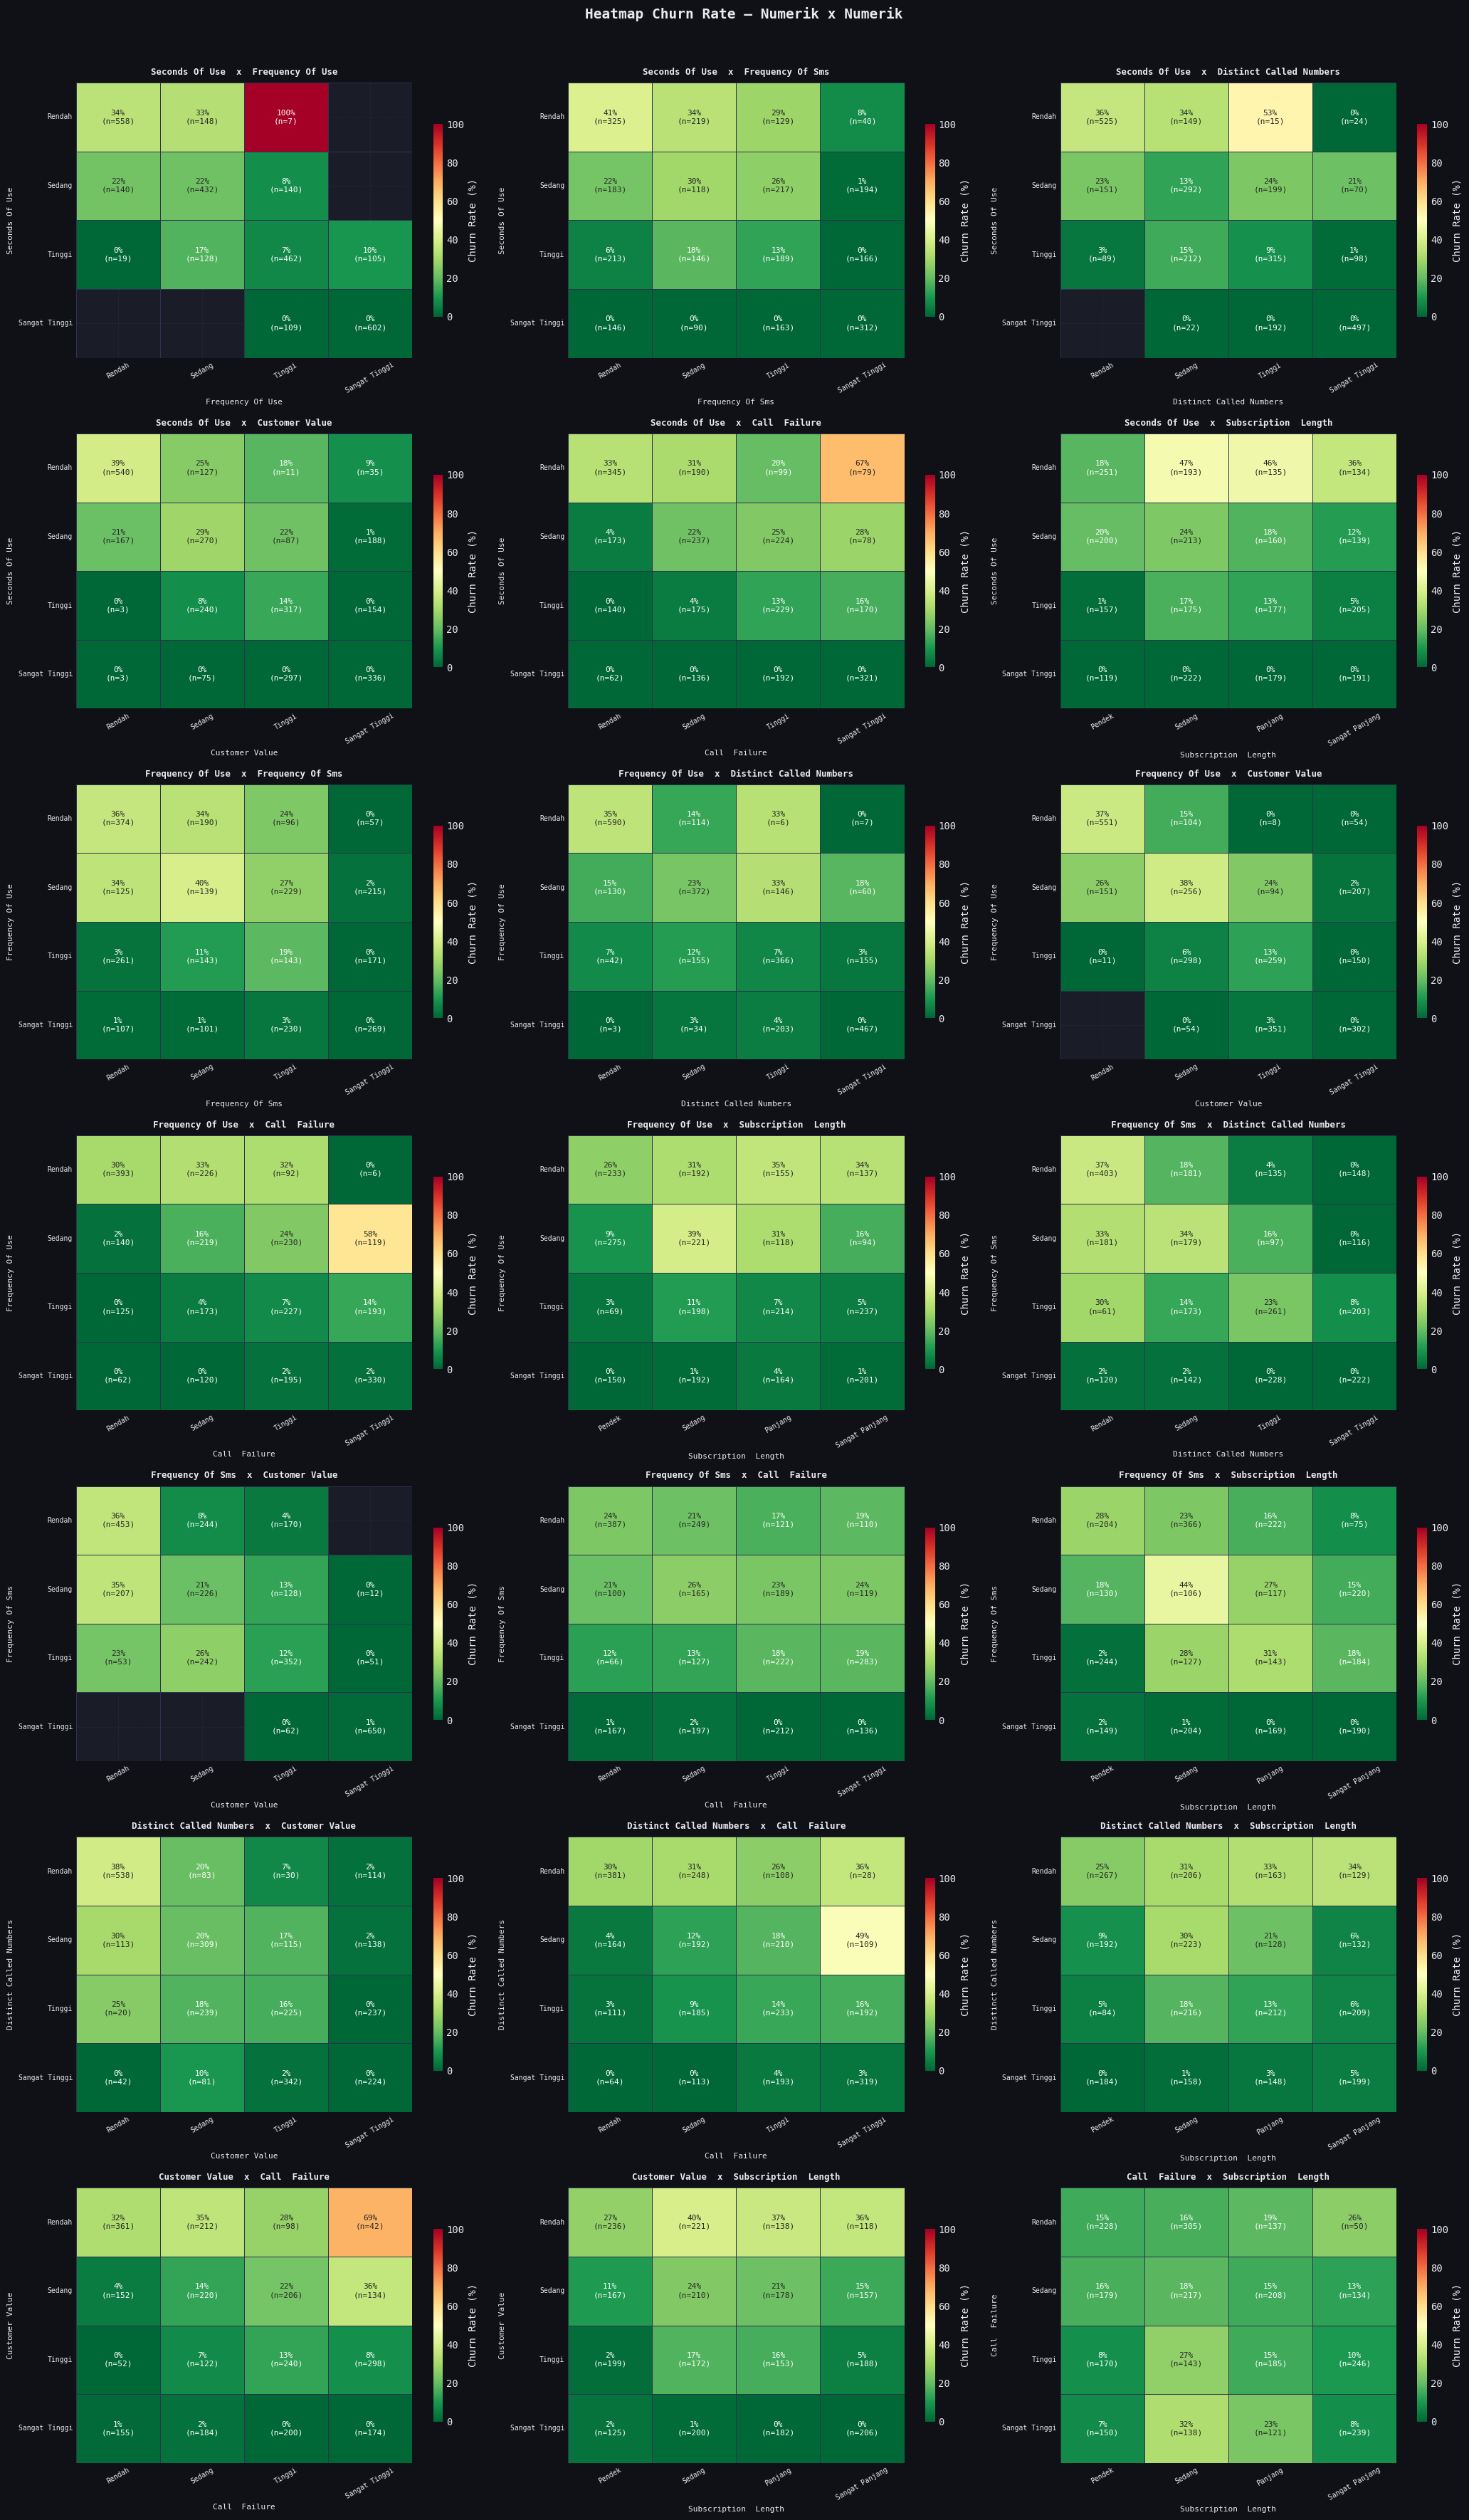

  TOP 20 KOMBINASI DUA FITUR DENGAN CHURN RATE TERTINGGI
  Minimum sampel per sel: 20 | Rata-rata: 15.6%

Fitur A                Nilai A          Fitur B                Nilai B             Rate      n  vs Avg
------------------------------------------------------------------------------------------------
  Complains            Komplain         Call  Failure        Rendah            100.0%     37    6.4x
  Complains            Komplain         Frequency Of Use     Rendah            100.0%     65    6.4x
  Complains            Komplain         Seconds Of Use       Rendah             98.8%     81    6.3x
  Complains            Komplain         Distinct Called Numbers Rendah             98.5%     68    6.3x
  Complains            Komplain         Customer Value       Rendah             97.4%     78    6.2x
  Complains            Komplain         Seconds Of Use       Tinggi             96.9%     32    6.2x
  Complains            Komplain         Subscription  Length Pendek             95.6%

In [ ]:
# Analisis: Multivariate Kombinasi Semua Fitur vs Churn
import itertools
from math import ceil

TARGET       = 'Churn'
overall_churn = df[TARGET].mean()

COLOR_0      = "#4fc3f7"
COLOR_1      = "#ef9a9a"
CMAP_HEATMAP = "RdYlGn_r"


BG_COLOR, PANEL_COLOR, TEXT_COLOR, GRID_COLOR = apply_dark_theme()

# Siapkan kolom bin untuk semua fitur numerik
df_mv = df.copy()

BIN_COLS = {
    'Seconds_of_Use':          ['Rendah','Sedang','Tinggi','Sangat Tinggi'],
    'Frequency_of_use':        ['Rendah','Sedang','Tinggi','Sangat Tinggi'],
    'Frequency_of_SMS':        ['Rendah','Sedang','Tinggi','Sangat Tinggi'],
    'Distinct_Called_Numbers': ['Rendah','Sedang','Tinggi','Sangat Tinggi'],
    'Customer_Value':          ['Rendah','Sedang','Tinggi','Sangat Tinggi'],
    'Call__Failure':           ['Rendah','Sedang','Tinggi','Sangat Tinggi'],
    'Subscription__Length':    ['Pendek','Sedang','Panjang','Sangat Panjang'],
}

for col, labels in BIN_COLS.items():
    if col not in df_mv.columns:
        continue
    new_col = col + '_bin'
    try:
        df_mv[new_col] = pd.qcut(df_mv[col], q=4, labels=labels, duplicates='drop')
    except Exception:
        df_mv[new_col] = pd.cut(df_mv[col], bins=4, labels=labels[:4])

# Label kategorik
CAT_LABELS = {
    'Complains':   {0: 'Tdk Komplain', 1: 'Komplain'},
    'Status':      {1: 'Aktif',      2: 'Non Aktif'},
    'Tariff_Plan': {1: 'Pay as you go',         2: 'contractual'},
    'Age_Group':   {1:'Usia 15', 2:'Usia 25', 3:'Usia 30',
                    4:'Usia 45', 5:'Usia 55'},
}
for col, mapping in CAT_LABELS.items():
    if col in df_mv.columns:
        df_mv[col + '_lbl'] = df_mv[col].map(mapping)

# Semua kolom yang akan dikombinasikan
ALL_COLS = (
    [c + '_lbl' for c in CAT_LABELS if c in df_mv.columns] +
    [c + '_bin' for c in BIN_COLS   if c in df_mv.columns]
)
ALL_COLS = [c for c in ALL_COLS if c in df_mv.columns]

# Nama bersih untuk label
def clean_name(col):
    return (col.replace('_lbl','').replace('_bin','')
               .replace('_',' ').title())


# ══════════════════════════════════════════════════════
# BAGIAN A: Heatmap semua kombinasi dua fitur
# (dikelompokkan: kat x kat, kat x num, num x num)
# ══════════════════════════════════════════════════════

cat_cols = [c for c in ALL_COLS if '_lbl' in c]
num_cols = [c for c in ALL_COLS if '_bin' in c]

GROUPS = {
    'Kategorik x Kategorik': list(itertools.combinations(cat_cols, 2)),
    'Kategorik x Numerik':   [(a, b) for a in cat_cols for b in num_cols],
    'Numerik x Numerik':     list(itertools.combinations(num_cols, 2)),
}

for group_name, pairs in GROUPS.items():
    if not pairs:
        continue

    n_cols_plot = 3
    n_rows_plot = ceil(len(pairs) / n_cols_plot)
    fig, axes   = plt.subplots(
        n_rows_plot, n_cols_plot,
        figsize=(7 * n_cols_plot, 5 * n_rows_plot),
        facecolor=BG_COLOR
    )
    axes = np.array(axes).flatten()
    fig.suptitle(f'Heatmap Churn Rate — {group_name}',
                 fontsize=14, fontweight='bold', y=1.01)

    for idx, (col_a, col_b) in enumerate(pairs):
        ax = axes[idx]
        pivot = df_mv.pivot_table(
            values=TARGET, index=col_a,
            columns=col_b, aggfunc='mean',
            observed=True
        ) * 100

        # Tampilkan jumlah sampel tiap sel di bawah persentase
        pivot_n = df_mv.pivot_table(
            values=TARGET, index=col_a,
            columns=col_b, aggfunc='count',
            observed=True
        )

        annot_labels = np.empty(pivot.shape, dtype=object)
        for i in range(pivot.shape[0]):
            for j in range(pivot.shape[1]):
                val = pivot.iloc[i, j]
                n   = pivot_n.iloc[i, j] if not pd.isna(pivot_n.iloc[i, j]) else 0
                if pd.isna(val):
                    annot_labels[i, j] = 'n/a'
                else:
                    annot_labels[i, j] = f'{val:.0f}%\n(n={int(n)})'

        sns.heatmap(
            pivot, annot=annot_labels, fmt='',
            cmap=CMAP_HEATMAP, ax=ax,
            linewidths=0.4, linecolor='#2e3250',
            vmin=0, vmax=100,
            cbar_kws={'shrink': 0.7, 'label': 'Churn Rate (%)'},
            annot_kws={'size': 8}
        )
        ax.set_title(f'{clean_name(col_a)}  x  {clean_name(col_b)}',
                     fontsize=9, fontweight='bold', pad=8)
        ax.set_xlabel(clean_name(col_b), fontsize=8)
        ax.set_ylabel(clean_name(col_a), fontsize=8)
        ax.tick_params(axis='x', rotation=30, labelsize=7)
        ax.tick_params(axis='y', rotation=0,  labelsize=7)

    for idx in range(len(pairs), len(axes)):
        axes[idx].set_visible(False)

    plt.tight_layout()
    plt.show()


# ══════════════════════════════════════════════════════
# BAGIAN B: Tabel kombinasi dengan churn rate tertinggi
# ══════════════════════════════════════════════════════

print('=' * 72)
print('  TOP 20 KOMBINASI DUA FITUR DENGAN CHURN RATE TERTINGGI')
print(f'  Minimum sampel per sel: 20 | Rata-rata: {overall_churn*100:.1f}%')
print('=' * 72)

all_pairs = list(itertools.combinations(ALL_COLS, 2))
combo_results = []

for col_a, col_b in all_pairs:
    grp = (df_mv.groupby([col_a, col_b], observed=True)[TARGET]
           .agg(['mean', 'count'])
           .reset_index())
    grp.columns = [col_a, col_b, 'Rate', 'n']
    grp = grp[grp['n'] >= 20]  # filter sel dengan sampel terlalu kecil

    for _, row in grp.iterrows():
        combo_results.append({
            'Fitur A':    clean_name(col_a),
            'Nilai A':    str(row[col_a]),
            'Fitur B':    clean_name(col_b),
            'Nilai B':    str(row[col_b]),
            'Churn Rate': round(row['Rate'] * 100, 1),
            'n':          int(row['n']),
            'Multiplier': round(row['Rate'] / overall_churn, 1),
        })

combo_df = pd.DataFrame(combo_results).sort_values('Churn Rate', ascending=False)
top20    = combo_df.head(20)

print(f'\n{"Fitur A":<22} {"Nilai A":<16} {"Fitur B":<22} {"Nilai B":<16} '
      f'{"Rate":>7} {"n":>6} {"vs Avg":>7}')
print('-' * 96)
for _, r in top20.iterrows():
    print(f'  {r["Fitur A"]:<20} {r["Nilai A"]:<16} '
          f'{r["Fitur B"]:<20} {r["Nilai B"]:<16} '
          f'{r["Churn Rate"]:>6.1f}%  {r["n"]:>5,}  '
          f'{r["Multiplier"]:>5.1f}x')


# ══════════════════════════════════════════════════════
# BAGIAN C: Kombinasi dengan churn rate TERENDAH
# (segmen paling loyal)
# ══════════════════════════════════════════════════════

print('\n' + '=' * 72)
print('  TOP 10 KOMBINASI DENGAN CHURN RATE TERENDAH (Segmen Paling Loyal)')
print('=' * 72)

bottom10 = combo_df[combo_df['n'] >= 50].tail(10).iloc[::-1]
print(f'\n{"Fitur A":<22} {"Nilai A":<16} {"Fitur B":<22} {"Nilai B":<16} '
      f'{"Rate":>7} {"n":>6}')
print('-' * 90)
for _, r in bottom10.iterrows():
    print(f'  {r["Fitur A"]:<20} {r["Nilai A"]:<16} '
          f'{r["Fitur B"]:<20} {r["Nilai B"]:<16} '
          f'{r["Churn Rate"]:>6.1f}%  {r["n"]:>5,}')

## Uji Validitas Kombinasi Dua Fitur: Stabilitas, Signifikansi, dan Proporsi Sampel

In [ ]:
# ── Validasi Otomatis Semua Temuan Ekstrem

from scipy.stats import chi2_contingency, fisher_exact
from sklearn.model_selection import train_test_split
import itertools
import warnings; warnings.filterwarnings('ignore')

TARGET        = 'Churn'
overall_churn = df[TARGET].mean()
N_TOTAL       = len(df)

# ── Parameter validasi (bisa diubah)
MIN_SAMPEL        = 50        # minimum sampel per sel
MIN_PCT_DATA      = 1.0       # minimum % dari total data
EKSTREM_THRESHOLD = 0.80      # churn rate >= 80% dianggap ekstrem tinggi
LOYAL_THRESHOLD   = 0.05      # churn rate <= 5% dianggap ekstrem rendah
DELTA_STABIL      = 0.10      # maksimum selisih train vs test
P_VALUE           = 0.05      # threshold signifikansi statistik

print('=' * 72)
print('  VALIDASI OTOMATIS TEMUAN EKSTREM')
print(f'  Total data    : {N_TOTAL:,} baris')
print(f'  Churn rate    : {overall_churn*100:.1f}%')
print(f'  Threshold     : ekstrem >= {EKSTREM_THRESHOLD*100:.0f}% '
      f'| loyal <= {LOYAL_THRESHOLD*100:.0f}%')
print(f'  Min sampel    : {MIN_SAMPEL} baris ({MIN_PCT_DATA}% data)')
print('=' * 72)


# ══════════════════════════════════════════════════════
# LANGKAH 1: Siapkan semua kolom (kategorik + bin)
# ══════════════════════════════════════════════════════

df_val = df.copy()

BIN_COLS = {
    'Seconds_of_Use':          ['Rendah','Sedang','Tinggi','Sangat Tinggi'],
    'Frequency_of_use':        ['Rendah','Sedang','Tinggi','Sangat Tinggi'],
    'Frequency_of_SMS':        ['Rendah','Sedang','Tinggi','Sangat Tinggi'],
    'Distinct_Called_Numbers': ['Rendah','Sedang','Tinggi','Sangat Tinggi'],
    'Customer_Value':          ['Rendah','Sedang','Tinggi','Sangat Tinggi'],
    'Call__Failure':           ['Rendah','Sedang','Tinggi','Sangat Tinggi'],
    'Subscription__Length':    ['Pendek','Sedang','Panjang','Sangat Panjang'],
}

for col, labels in BIN_COLS.items():
    if col not in df_val.columns:
        continue
    try:
        df_val[col+'_bin'] = pd.qcut(
            df_val[col], q=4, labels=labels, duplicates='drop'
        )
    except Exception:
        df_val[col+'_bin'] = pd.cut(
            df_val[col], bins=4, labels=labels
        )

CAT_LABELS = {
    'Complains':   {0:'Tdk Komplain', 1:'Komplain'},
    'Status':      {1:'Status 1',     2:'Status 2'},
    'Tariff_Plan': {1:'Plan 1',       2:'Plan 2'},
    'Age_Group':   {1:'Usia 15', 2:'Usia 25', 3:'Usia 30',
                    4:'Usia 45', 5:'Usia 55'},
}
for col, mapping in CAT_LABELS.items():
    if col in df_val.columns:
        df_val[col+'_lbl'] = df_val[col].map(mapping)

ALL_FEAT = (
    [c+'_lbl' for c in CAT_LABELS  if c in df_val.columns] +
    [c+'_bin' for c in BIN_COLS    if c in df_val.columns]
)
ALL_FEAT = [c for c in ALL_FEAT if c in df_val.columns]

def clean_name(col):
    return col.replace('_lbl','').replace('_bin','').replace('_',' ').title()


# ══════════════════════════════════════════════════════
# LANGKAH 2: Scan semua kombinasi, deteksi yang ekstrem
# ══════════════════════════════════════════════════════

print('\n[1/4] Scanning semua kombinasi dua fitur...')

kandidat = []
all_pairs = list(itertools.combinations(ALL_FEAT, 2))

for col_a, col_b in all_pairs:
    grp = (df_val.groupby([col_a, col_b], observed=True)[TARGET]
           .agg(['mean','count'])
           .reset_index())
    grp.columns = [col_a, col_b, 'rate', 'n']
    grp = grp[grp['n'] >= MIN_SAMPEL]

    for _, row in grp.iterrows():
        rate = row['rate']
        n    = int(row['n'])
        pct  = n / N_TOTAL * 100
        if pct < MIN_PCT_DATA:
            continue
        if rate >= EKSTREM_THRESHOLD or rate <= LOYAL_THRESHOLD:
            kandidat.append({
                'col_a':  col_a,
                'val_a':  row[col_a],
                'col_b':  col_b,
                'val_b':  row[col_b],
                'rate':   rate,
                'n':      n,
                'pct':    round(pct, 2),
                'tipe':   'TINGGI' if rate >= EKSTREM_THRESHOLD else 'RENDAH',
            })

kandidat_df = pd.DataFrame(kandidat).sort_values('rate', ascending=False)
print(f'   Ditemukan {len(kandidat_df)} kombinasi ekstrem '
      f'(>{EKSTREM_THRESHOLD*100:.0f}% atau <{LOYAL_THRESHOLD*100:.0f}%) '
      f'dengan sampel >= {MIN_SAMPEL}')


# ══════════════════════════════════════════════════════
# LANGKAH 3: Validasi otomatis tiap kandidat
# ══════════════════════════════════════════════════════

print('\n[2/4] Menjalankan validasi 3 dimensi...\n')

df_train, df_test = train_test_split(
    df_val, test_size=0.2, random_state=42,
    stratify=df_val[TARGET]
)

hasil_validasi = []

for _, row in kandidat_df.iterrows():
    col_a, val_a = row['col_a'], row['val_a']
    col_b, val_b = row['col_b'], row['val_b']

    # ── A: Proporsi sampel
    n     = row['n']
    pct   = row['pct']
    ok_n  = n >= MIN_SAMPEL and pct >= MIN_PCT_DATA

    # ── B: Stabilitas train vs test
    mask_tr = (df_train[col_a].astype(str) == str(val_a)) & \
              (df_train[col_b].astype(str) == str(val_b))
    mask_te = (df_test[col_a].astype(str)  == str(val_a)) & \
              (df_test[col_b].astype(str)  == str(val_b))

    n_tr = mask_tr.sum()
    n_te = mask_te.sum()

    if n_tr >= 10 and n_te >= 5:
        rate_tr = df_train[mask_tr][TARGET].mean()
        rate_te = df_test[mask_te][TARGET].mean()
        delta   = abs(rate_tr - rate_te)
        ok_stab = delta <= DELTA_STABIL
        stab_str = f'{rate_tr*100:.0f}% vs {rate_te*100:.0f}% (Δ{delta*100:.0f}%)'
    else:
        ok_stab  = None   # tidak cukup sampel untuk split
        stab_str = 'n/a (sampel terlalu kecil di salah satu split)'

    # ── C: Signifikansi statistik (fitur individual vs churn)
    # Cek fitur A
    col_a_orig = col_a.replace('_lbl','').replace('_bin','')
    col_b_orig = col_b.replace('_lbl','').replace('_bin','')

    def uji_signifikansi(col_orig):
        if col_orig not in df.columns:
            return None, None
        ct = pd.crosstab(df[col_orig], df[TARGET])
        if ct.shape == (2, 2):
            odds, p = fisher_exact(ct)
            return odds, p
        else:
            chi2, p, _, _ = chi2_contingency(ct)
            return chi2, p

    stat_a, p_a = uji_signifikansi(col_a_orig)
    stat_b, p_b = uji_signifikansi(col_b_orig)

    ok_sig_a = (p_a < P_VALUE) if p_a is not None else None
    ok_sig_b = (p_b < P_VALUE) if p_b is not None else None

    # ── Verdict akhir
    checks       = [ok_n, ok_stab, ok_sig_a, ok_sig_b]
    checks_valid = [c for c in checks if c is not None]

    if not checks_valid:
        verdict = '⚠  TIDAK CUKUP DATA untuk divalidasi'
    elif not ok_n:
        verdict = '❌ TOLAK — sampel tidak cukup'
    elif ok_stab is False:
        verdict = '⚠  HATI-HATI — tidak stabil di test set'
    elif ok_sig_a is False or ok_sig_b is False:
        verdict = '⚠  HATI-HATI — fitur tidak signifikan'
    elif all(checks_valid):
        verdict = '✅ VALID'
    else:
        verdict = '⚠  HATI-HATI — perlu investigasi lebih lanjut'

    hasil_validasi.append({
        'Fitur A':     clean_name(col_a),
        'Nilai A':     str(val_a),
        'Fitur B':     clean_name(col_b),
        'Nilai B':     str(val_b),
        'Tipe':        row['tipe'],
        'Rate':        round(row['rate'] * 100, 1),
        'n':           n,
        '% Data':      pct,
        'Stabil?':     stab_str,
        'Sig A?':      f'p={p_a:.4f}' if p_a is not None else 'n/a',
        'Sig B?':      f'p={p_b:.4f}' if p_b is not None else 'n/a',
        'Verdict':     verdict,
    })

hasil_df = pd.DataFrame(hasil_validasi)


# ══════════════════════════════════════════════════════
# LANGKAH 4: Tampilkan ringkasan per verdict
# ══════════════════════════════════════════════════════

print('[3/4] Hasil validasi:\n')

for verdict_grp in ['✅ VALID', '⚠  HATI-HATI — tidak stabil di test',
                    '⚠  HATI-HATI — fitur tidak signifikan',
                    '❌ TOLAK — sampel tidak cukup']:
    subset = hasil_df[hasil_df['Verdict'] == verdict_grp]
    if len(subset) == 0:
        continue

    print(f'\n{"="*72}')
    print(f'  {verdict_grp}  ({len(subset)} kombinasi)')
    print(f'{"="*72}')
    print(f'  {"Fitur A":<18} {"Nilai A":<14} {"Fitur B":<22} '
          f'{"Nilai B":<16} {"Rate":>6} {"n":>5} {"Stabil"}')
    print('  ' + '-' * 90)

    for _, r in subset.sort_values('Rate', ascending=(verdict_grp != '✅ VALID')).iterrows():
        print(f'  {r["Fitur A"]:<18} {r["Nilai A"]:<14} '
              f'{r["Fitur B"]:<22} {r["Nilai B"]:<16} '
              f'{r["Rate"]:>5.1f}%  {r["n"]:>4}  {r["Stabil?"]}')


# ══════════════════════════════════════════════════════
# RINGKASAN AKHIR
# ══════════════════════════════════════════════════════

print('\n\n[4/4] Ringkasan akhir:\n')
print(f'  Total kandidat ekstrem  : {len(hasil_df):>4}')
for v in hasil_df['Verdict'].unique():
    n = (hasil_df['Verdict'] == v).sum()
    print(f'  {v:<45}: {n:>4}')

valid_tinggi = hasil_df[(hasil_df['Verdict'] == '✅ VALID') &
                         (hasil_df['Tipe'] == 'TINGGI')]
valid_rendah = hasil_df[(hasil_df['Verdict'] == '✅ VALID') &
                        (hasil_df['Tipe'] == 'RENDAH')].sort_values(['Rate', 'n'], ascending=[True, False])

print(f'\n  Kombinasi VALID berisiko tinggi : {len(valid_tinggi)}')
print(f'  Kombinasi VALID paling loyal    : {len(valid_rendah)}')

print('\n  Top 10 kombinasi VALID berisiko tertinggi:')
for _, r in valid_tinggi.head(10).iterrows():
    print(f'    {r["Fitur A"]} [{r["Nilai A"]}] x '
          f'{r["Fitur B"]} [{r["Nilai B"]}] '
          f'→ {r["Rate"]}% (n={r["n"]})')

print('\n  Top 15 kombinasi VALID paling loyal:')
for _, r in valid_rendah.head(15).iterrows():
    print(f'    {r["Fitur A"]} [{r["Nilai A"]}] x '
          f'{r["Fitur B"]} [{r["Nilai B"]}] '
          f'→ {r["Rate"]}% (n={r["n"]})')

  VALIDASI OTOMATIS TEMUAN EKSTREM
  Total data    : 2,850 baris
  Churn rate    : 15.6%
  Threshold     : ekstrem >= 80% | loyal <= 5%
  Min sampel    : 50 baris (1.0% data)

[1/4] Scanning semua kombinasi dua fitur...
   Ditemukan 202 kombinasi ekstrem (>80% atau <5%) dengan sampel >= 50

[2/4] Menjalankan validasi 3 dimensi...

[3/4] Hasil validasi:


  ✅ VALID  (88 kombinasi)
  Fitur A            Nilai A        Fitur B                Nilai B            Rate     n Stabil
  ------------------------------------------------------------------------------------------
  Complains          Komplain       Frequency Of Use       Rendah           100.0%    65  100% vs 100% (Δ0%)
  Complains          Komplain       Seconds Of Use         Rendah            98.8%    81  98% vs 100% (Δ2%)
  Complains          Komplain       Distinct Called Numbers Rendah            98.5%    68  98% vs 100% (Δ2%)
  Complains          Komplain       Frequency Of Use       Sedang            92.9%    98  92% vs 96% (

## **Validasi Analisis Multivariat: Kombinasi Dua Fitur**

Analisis ini memperluas segmentasi sebelumnya dengan mengkombinasikan
dua fitur sekaligus untuk mengungkap pola interaksi yang tidak terlihat
dari analisis satu fitur. Setiap sel data telah divalidasi dengan
standar statistik yang ketat: mengeliminasi kombinasi dengan sampel di
bawah 50 pelanggan (n < 50) dan melewati uji stabilitas distribusi
(Train/Test Split) untuk memastikan temuan ini adalah pola nyata,
bukan sekadar noise kebetulan.

---

### **Kombinasi Kategorik x Kategorik**

Temuan dari kelompok ini mengkonfirmasi dan memperdalam analisis
segmentasi sebelumnya dengan angka yang lebih spesifik.

**`Complains` x `Status`:** Kedua fitur ini saling memperkuat secara
dramatis. Pelanggan yang tidak komplain dan berstatus 1 hanya memiliki
churn rate 3.1% (n=2.085), sedangkan yang komplain dan berstatus 2
mencapai 89.3% (n=149). Ini adalah rentang probabilitas terlebar di
kategori ini dan mengkonfirmasi bahwa kedua fitur ini bekerja secara
sinergis terhadap risiko churn.

**`Complains` x `Tariff Plan`:** Pelanggan Plan 2 yang tidak komplain
memiliki churn rate absolut 0.0% (n=210), menjadikannya segmen paling
loyal di kategori ini. Di sisi lain, pelanggan Plan 1 yang komplain
mencatat churn rate 87.2% (n=211). Catatan: kombinasi Plan 2 x Komplain
tidak masuk threshold validasi sehingga angka pastinya tidak tersedia
dari output ini dan tidak dapat dibandingkan secara langsung.

**`Complains` x `Age Group`:** Efek komplain sangat konsisten di
berbagai kelompok usia. Pelanggan yang komplain di usia 25 dan 30 tahun
mencatat churn rate ekstrem masing-masing 88.1% (n=67) dan 81.9%
(n=127), menunjukkan bahwa faktor usia tidak meredam risiko churn
ketika pelanggan sudah mengajukan komplain.

**`Status` x `Tariff Plan`:** Status 1 dengan Plan 2 merupakan
perpaduan dengan tingkat churn sangat rendah di angka 2.2% (n=228),
menjadikannya salah satu segmen paling aman di kelompok kombinasi
kategorik.

**`Status` x `Age Group`:** Status 1 secara konsisten menghasilkan
churn rate rendah di seluruh kelompok usia. Sebaliknya, kombinasi
yang melibatkan Status 2 secara konsisten mendorong churn rate lebih
tinggi, membuktikan bahwa status pelanggan memiliki pengaruh kuat yang
berjalan lintas kelompok usia.

---

### **Kombinasi Kategorik x Numerik**

Kelompok ini menghasilkan temuan paling krusial karena menggabungkan
sinyal tajam dari fitur kategorik dengan profil perilaku numerik.

**`Complains` x Kluster Panggilan Suara (`Frequency of Use`,
`Seconds of Use`):** Ditemukan pola dengan churn rate tertinggi di
seluruh dataset. Pelanggan dengan tingkat penggunaan Rendah yang
mengajukan komplain mencetak churn rate 100.0% (n=65) dan 98.8%
(n=81), keduanya terbukti stabil di train dan test set. Logika
bisnisnya: pelanggan yang jarang menggunakan layanan dan kemudian
komplain tidak memiliki alasan kuat untuk bertahan. Sebaliknya,
pelanggan yang tidak komplain konsisten memiliki churn rate mendekati
0% di segmen penggunaan Tinggi dan Sangat Tinggi.

**`Complains` x `Subscription Length`:** Pelanggan yang komplain
dengan masa langganan Sedang memiliki churn rate 92.7% (n=82).
Temuan ini menunjukkan bahwa durasi langganan yang lebih panjang
tidak memberikan efek protektif yang berarti ketika pelanggan sudah
mengajukan komplain.

**`Status` x Fitur Usage:** Status 1 yang dikombinasikan dengan
penggunaan Sangat Tinggi secara konsisten menghasilkan churn rate
0.0% di berbagai kombinasi dengan jumlah sampel besar (n=664 hingga
n=711). Ini adalah salah satu pola paling konsisten dan terkuat di
seluruh dataset.

---

### **Kombinasi Numerik x Numerik**

Kelompok ini mengungkap hubungan antar fitur usage dan pola perilaku
yang terbentuk dari kombinasinya.

**Kluster Panggilan Suara (`Seconds of Use` x `Frequency of Use` x
`Distinct Called Numbers`):** Pola gradien terlihat jelas. Semakin
tinggi penggunaan di dimensi ini, churn rate semakin mendekati 0%.
Dari heatmap korelasi diketahui Seconds of Use dan Frequency of Use
berkorelasi sangat tinggi (r=0.95), sedangkan Distinct Called Numbers
memiliki korelasi lebih rendah dengan keduanya (r=0.67 dan r=0.73),
menunjukkan ketiga fitur ini membawa informasi yang sebagian tumpang
tindih namun tidak identik. Kombinasi Sangat Tinggi di ketiga fitur
ini secara konsisten menghasilkan churn rate 0.0% dengan sampel besar.

**Kluster Pendapatan Teks (`Customer Value` x `Frequency of SMS`):**
Dari heatmap korelasi, Customer Value berkorelasi sangat tinggi dengan
Frequency of SMS (r=0.92). Kombinasi pelanggan dengan Customer Value
Sangat Tinggi terbukti konsisten berada di rentang churn rate terendah
(0.0%) di berbagai kombinasi dengan fitur lain, mengkonfirmasi bahwa
pelanggan bernilai tinggi adalah segmen paling loyal di dataset ini.

**`Distinct Called Numbers` x `Subscription Length`:** Kombinasi
penggunaan Rendah dengan masa langganan Pendek cenderung memiliki
churn rate lebih tinggi dibanding kombinasi lainnya di kelompok ini,
menunjukkan bahwa pelanggan baru dengan jaringan kontak yang sedikit
memiliki risiko churn yang lebih besar.

---

### **Temuan dari Ranking Kombinasi Ekstrem**

**Top Kombinasi Churn Rate Tertinggi (Risiko Tinggi):** Dari 11
kombinasi valid berisiko tinggi, 10 di antaranya melibatkan Complains
= Komplain. Satu-satunya kombinasi tanpa Complains yang masuk kategori
ini adalah Status 2 x Seconds of Use Tinggi dengan churn rate 92.9%.
Temuan ini menunjukkan bahwa Complains adalah faktor yang paling
dominan dalam mendorong churn rate ke level ekstrem, meskipun bukan
satu-satunya.

**Top Kombinasi Churn Rate Terendah (Segmen Paling Loyal):** Profil
pelanggan paling loyal didominasi oleh perpaduan Status 1, Seconds of
Use Sangat Tinggi, dan Frequency of Use Sangat Tinggi. Kombinasi ini
secara konsisten mencatat churn rate 0.0% dengan ukuran sampel yang
besar (n=467 hingga n=711), menjadikannya temuan yang paling dapat
diandalkan secara statistik di seluruh analisis ini.

---

## **Kesimpulan dan Rekomendasi Bisnis**

Menggabungkan temuan dari analisis satu fitur (Section A) dan analisis kombinasi dua fitur yang tervalidasi (Section B), terdapat tiga kelompok pelanggan yang paling berasosiasi dengan risiko churn, serta satu profil yang paling berasosiasi dengan loyalitas.

### **Kelompok Berisiko Tinggi**

**`Complains` adalah sinyal tunggal paling dominan.** Pelanggan yang pernah komplain memiliki churn rate 82.6% pada level individu, dan dari 11 kombinasi dua fitur yang tervalidasi sebagai berisiko ekstrem, 10 di antaranya melibatkan `Complains`. Ketika komplain berpadu dengan penggunaan rendah, churn rate mencapai 100% (n=65, stabil di train maupun test set). Asosiasi ini konsisten di berbagai kelompok usia dan jenis paket, sehingga `Complains` layak menjadi kriteria utama dalam menyusun program retensi, meski data ini tidak bisa memastikan arah waktu antara komplain dan keputusan churn (lihat keterbatasan cross-sectional di bagian akhir).

**`Status` non-aktif berasosiasi kuat secara independen dari `Complains`.** Pelanggan Status 2 memiliki churn rate 47.5%, dan kombinasi Status 2 x Seconds of Use Tinggi tetap mencatat churn rate 92.9% tanpa keterlibatan komplain sama sekali. Ini mengindikasikan Status menangkap sinyal risiko yang berbeda dari sekadar ketidakpuasan yang terucap lewat komplain. Penting dicatat, 149 dari 230 pelanggan yang komplain (65%) juga berstatus non-aktif, sehingga kedua kelompok ini tumpang tindih signifikan dan sebaiknya diperlakukan sebagai satu populasi berisiko gabungan (union, bukan penjumlahan terpisah) saat menghitung skala program retensi.

**Intensitas penggunaan rendah berasosiasi dengan churn di semua kombinasi yang diuji.** `Seconds of Use`, `Frequency of Use`, dan `Distinct Called Numbers` (klaster dengan korelasi internal 0.75-0.93) secara konsisten menunjukkan churn rate mendekati 0% pada kuartil tertinggi dan meningkat tajam pada kuartil terendah, di seluruh kombinasi yang divalidasi.

### **Profil Paling Loyal**

Dari 77 kombinasi tervalidasi dengan churn rate terendah, profil yang mendominasi adalah pelanggan dengan `Status` Aktif, tidak pernah `Complains`, dan penggunaan Sangat Tinggi (`Seconds of Use`, `Frequency of Use`), dengan sampel besar (n=467 hingga n=711) dan churn rate mendekati atau tepat 0.0%. Profil ini menjadi acuan untuk mengidentifikasi segmen yang sebaiknya dijaga lewat program loyalitas, bukan retensi darurat.

---
### **Catatan Metodologis: Cakupan Validasi**

Proses validasi dirancang khusus untuk memvalidasi kombinasi **ekstrem** (churn rate ≥80% atau ≤5%) dengan tiga syarat:
- minimum 50 sampel,
- stabilitas train/test (Δ≤10%), dan
- signifikansi statistik fitur pembentuknya.

Dua implikasi penting dari cakupan ini:

1. **Ditolak karena sampel tidak cukup (n<50):**

> Tiga temuan yang sempat muncul di eksplorasi awal yakni `Complains` x `Call Failure` rendah (100%, n=37), `Complains` x `Age Group` Usia 45 (92.9%, n=28), dan `Complains` x `Subscription Length` Pendek (95.6%, n=45). Mereka tidak lolos validasi murni karena ukuran sampelnya di bawah ambang minimum. Untuk `Call Failure` secara khusus, ini konsisten dengan temuan FASE 3 bahwa fitur ini memang tidak informatif terhadap churn (MI=0.000000, p=0.4996), sehingga tidak ada kerugian analitis dari pengecualiannya. Untuk dua temuan lainnya, ini murni keterbatasan ukuran sampel, bukan indikasi fitur tidak relevan (`Age_Group` dan `Subscription Length` tetap terbukti relevan lewat kombinasi lain yang lolos validasi).

2. **Di luar cakupan validasi (bukan ditolak):**

> Kombinasi `Status` x `Tariff Plan` (Status Non Aktif + Plan 1, churn 47.4%) dan `Status` x `Age Group` (Status Non Aktif, churn 44-52% di berbagai usia) tidak muncul di daftar tervalidasi bukan karena gagal uji, melainkan karena churn rate-nya berada di rentang menengah, di luar ambang "ekstrem" (≥80%) yang menjadi fokus validasi ini. Temuan-temuan ini tetap valid sebagai bagian dari analisis segmentasi satu-fitur dan kombinasi kategorik-kategorik di awal Section B, hanya saja tidak termasuk dalam scoring "ekstrem" khusus ini.

---
## **Keterbatasan**

> Seluruh temuan di atas bersifat asosiatif, diambil dari data cross-sectional 9 bulan pertama dengan churn diukur di bulan ke-12. Data ini tidak dapat memastikan urutan waktu atau hubungan sebab-akibat antara `Complains`, `Status`, intensitas penggunaan, dan keputusan churn pelanggan. Rekomendasi program retensi berbasis temuan ini sebaiknya divalidasi lebih lanjut melalui uji coba terkontrol (misalnya A/B testing pada segmen berisiko) sebelum diterapkan secara luas.
---

# C. Value at Risk Analysis

### Catatan Metodologi: Interpretasi `Customer_Value`

Dokumentasi resmi dataset (UCI ML Repository, *Iranian Churn Dataset*, id=563) mendefinisikan `Customer_Value` hanya sebagai *"the calculated value of customer"*, tanpa merinci formula, komponen penyusun, atau satuan currency. Berbeda dengan `Charge_Amount` yang eksplisit didefinisikan sebagai atribut ordinal (skala 0-9), `Customer_Value` tidak memiliki spesifikasi satuan yang jelas dari sumber data.

Oleh karena itu, analisis *Value at Risk* berikut dibaca sebagai **proporsi kontribusi nilai relatif** antar segmen, bukan estimasi kerugian finansial dalam mata uang tertentu.

Tujuan analisis ini adalah mendemonstrasikan bagaimana temuan statistik EDA dapat diterjemahkan menjadi metrik yang relevan untuk pengambilan keputusan bisnis, menggunakan `Customer_Value` sebagai *proxy* nilai pelanggan.

**Sumber:** Jafari-Marandi, R., Denton, J., Idris, A., Smith, B. K., & Keramati, A. (2020). *Iranian Churn Dataset*. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/563/iranian+churn+dataset

In [ ]:
# ============================================================
# VALUE AT RISK: UNION SEGMENT (Complains=1 OR Status=2)
# Versi deskriptif, menghindari double-count dari overlap segmen
# ============================================================

def value_at_risk_union(df, conditions, target_col='Churn',
                          value_col='Customer_Value', label='Union Segment'):
    """
    conditions: list of boolean Series, digabung dengan OR
    """
    total_pop        = len(df)
    total_value_pop  = df[value_col].sum()
    total_churn_pop  = df[target_col].sum()
    overall_churn_rate = total_churn_pop / total_pop

    mask = conditions[0]
    for c in conditions[1:]:
        mask = mask | c

    segment    = df[mask]
    n_total    = len(segment)
    n_churn    = segment[target_col].sum()
    churn_rate = n_churn / n_total

    total_value_segment   = segment[value_col].sum()
    churned_value_segment = segment[segment[target_col] == 1][value_col].sum()
    avg_value_churned     = segment[segment[target_col] == 1][value_col].mean()

    return {
        'segment': label,
        'n_total': n_total,
        'pct_of_population': round(n_total / total_pop * 100, 1),
        'n_churn': int(n_churn),
        'churn_rate': round(churn_rate * 100, 1),
        'vs_avg_multiplier': round(churn_rate / overall_churn_rate, 1),
        'pct_of_total_churners': round(n_churn / total_churn_pop * 100, 1),
        'total_customer_value_segment': round(total_value_segment, 0),
        'pct_of_total_customer_value': round(total_value_segment / total_value_pop * 100, 1),
        'value_lost_to_churn_segment': round(churned_value_segment, 0),
        'avg_value_per_churned_customer': round(avg_value_churned, 1) if not pd.isna(avg_value_churned) else 0,
    }

# ============================================================
# Persiapan: generate kolom bin Seconds_of_Use (kalau belum ada di df)
# ============================================================

if 'Seconds_of_Use_bin' not in df.columns:
    df['Seconds_of_Use_bin'] = pd.qcut(
        df['Seconds_of_Use'],
        q=4,
        labels=['Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi'],
        duplicates='drop'
    )

# ============================================================
# VALUE AT RISK — UNION SEGMENT (4 kondisi)
# Complains=1 OR Status=2 OR Seconds_of_Use Rendah OR Subscription pendek
# ============================================================

union_result = value_at_risk_union(
    df,
    conditions=[
        df['Complains'] == 1.0,
        df['Status'] == 2.0,
        df['Seconds_of_Use_bin'] == 'Rendah',
        df['Subscription__Length'] < 15.50,
    ],
    label='Complains=1 OR Status=2 OR Pemakaian Rendah OR Tenure Pendek'
)

pd.DataFrame([union_result])

,segment,n_total,pct_of_population,n_churn,churn_rate,vs_avg_multiplier,pct_of_total_churners,total_customer_value_segment,pct_of_total_customer_value,value_lost_to_churn_segment,avg_value_per_churned_customer
0,Complains=1 OR Status=2 OR Pemakaian Rendah OR...,1145,40.2,417,36.4,2.3,93.5,240177.0,17.7,50122.0,120.2


In [ ]:
# ============================================================
# VALUE AT RISK — INTERSECTION SEGMENT (irisan/AND)
# Pelanggan yang memenuhi SEMUA kriteria risiko sekaligus
# ============================================================

def value_at_risk_intersection(df, conditions, target_col='Churn',
                                 value_col='Customer_Value', label='Intersection Segment'):
    """
    conditions: list of boolean Series, digabung dengan AND
    """
    total_pop        = len(df)
    total_value_pop  = df[value_col].sum()
    total_churn_pop  = df[target_col].sum()
    overall_churn_rate = total_churn_pop / total_pop

    mask = conditions[0]
    for c in conditions[1:]:
        mask = mask & c

    segment = df[mask]
    n_total = len(segment)

    if n_total == 0:
        print(f"Peringatan: tidak ada pelanggan yang memenuhi seluruh kriteria sekaligus untuk '{label}'.")
        return None

    n_churn    = segment[target_col].sum()
    churn_rate = n_churn / n_total

    total_value_segment   = segment[value_col].sum()
    churned_value_segment = segment[segment[target_col] == 1][value_col].sum()
    avg_value_churned     = segment[segment[target_col] == 1][value_col].mean()

    return {
        'segment': label,
        'n_total': n_total,
        'pct_of_population': round(n_total / total_pop * 100, 2),
        'n_churn': int(n_churn),
        'churn_rate': round(churn_rate * 100, 1),
        'vs_avg_multiplier': round(churn_rate / overall_churn_rate, 1),
        'pct_of_total_churners': round(n_churn / total_churn_pop * 100, 1),
        'total_customer_value_segment': round(total_value_segment, 0),
        'pct_of_total_customer_value': round(total_value_segment / total_value_pop * 100, 2),
        'value_lost_to_churn_segment': round(churned_value_segment, 0),
        'avg_value_per_churned_customer': round(avg_value_churned, 1) if not pd.isna(avg_value_churned) else 0,
    }

# ============================================================
# Persiapan: generate kolom bin Seconds_of_Use (kalau belum ada di df)
# ============================================================

if 'Seconds_of_Use_bin' not in df.columns:
    df['Seconds_of_Use_bin'] = pd.qcut(
        df['Seconds_of_Use'],
        q=4,
        labels=['Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi'],
        duplicates='drop'
    )

# ============================================================
# Panggil dengan 4 kondisi yang sama seperti union
# ============================================================

intersection_result = value_at_risk_intersection(
    df,
    conditions=[
        df['Complains'] == 1.0,
        df['Status'] == 2.0,
        df['Seconds_of_Use_bin'] == 'Rendah',
        df['Subscription__Length'] < 15.50,
    ],
    label='Complains=1 AND Status=2 AND Pemakaian Rendah AND Tenure Pendek'
)

if intersection_result is not None:
    display(pd.DataFrame([intersection_result]))

,segment,n_total,pct_of_population,n_churn,churn_rate,vs_avg_multiplier,pct_of_total_churners,total_customer_value_segment,pct_of_total_customer_value,value_lost_to_churn_segment,avg_value_per_churned_customer
0,Complains=1 AND Status=2 AND Pemakaian Rendah ...,2,0.07,2,100.0,6.4,0.4,105.0,0.01,105.0,52.4


#### **Catatan interpretasi:**

>Irisan keempat kriteria risiko sekaligus (`Complains=1` **AND** `Status=2` **AND** `Seconds_of_Use` Rendah **AND** `Subscription__Length` < 15.5 bulan) hanya ditemukan pada **2 pelanggan** (0.07% dari populasi). Sampel sekecil ini tidak layak dijadikan dasar klaim statistik apa pun, angka churn rate 100% di atas semata-mata mencerminkan bahwa keduanya kebetulan churn, bukan bukti pola yang bisa digeneralisasi.
>
> Justru sebaliknya, ukuran sampel yang sangat kecil ini adalah temuan tersendiri: keempat sinyal risiko (komplain, status non-aktif, pemakaian rendah, tenure pendek) **jarang muncul bersamaan pada individu yang sama**. Sinyal-sinyal ini lebih sering muncul secara terpisah pada segmen pelanggan yang berbeda-beda, ketimbang menumpuk pada satu kelompok kecil pelanggan "berisiko ekstrem". Interpretasi lebih lengkap ada di **Executive Summary, Section 5 (Estimasi Dampak / Value at Risk)**.

# D. Executive Summary - EDA Customer Churn (Iranian Telecom Dataset)

**Konteks data:** Dataset berisi 3.150 pelanggan telekomunikasi Iran. Seluruh fitur perilaku diagregasi dari **9 bulan pertama**, sedangkan label `Churn` diukur pada **akhir bulan ke-12**. Dengan demikian, seluruh insight berikut bersifat **asosiatif (korelasional), bukan kausal**, validasi arah sebab-akibat memerlukan data time-series bulanan atau eksperimen retensi terkontrol.

---

## 1. Complains adalah sinyal risiko dominan tunggal
Pelanggan yang pernah mengajukan komplain churn pada **82.6%** kasus, dibanding **9.8%** pada pelanggan tanpa komplain, selisih 67 poin persentase (5.3x rata-rata keseluruhan 15.6%).

`Complains` juga mendominasi hampir seluruh kombinasi dua fitur berisiko tertinggi: **18 dari 20 baris** pada tabel top churn rate melibatkan `Complains=Komplain`. Ini perlu dibaca sebagai **satu insight dominan yang berulang**, bukan 18 temuan independen, fitur kedua pada tiap kombinasi (Frequency of Use rendah, Call Failure rendah, dst) hanya menambah efek marjinal kecil di atas baseline 82.6%.

*Catatan kehati-hatian: sebagian kombinasi memiliki n kecil (n=28-45) sehingga rate 90-100% pada sel tersebut bersifat indikatif, belum cukup robust untuk klaim pasti.*

## 2. Status non-aktif adalah sinyal kuat kedua, sebagian independen dari Complains
`Status=2` (non-aktif) churn pada **47.5%** (3.0x rata-rata). Sinyal ini tidak sepenuhnya tumpang tindih dengan Complains, kombinasi `Status Non Aktif x Seconds of Use Tinggi` tetap churn 92.9% (n=28) meski volume pemakaian tinggi, menunjukkan `Status` menangkap risiko yang tidak terjelaskan oleh metrik penggunaan semata.

**Namun**, 149 dari 230 pelanggan yang komplain (65%) juga berstatus non-aktif, overlap yang signifikan (korelasi 0.28). Union kedua segmen ini (`Complains=1 OR Status=2`, n=765) memiliki churn rate 49.9% (3.2x rata-rata).

## 3. Intensitas pemakaian rendah berasosiasi dengan churn, tervalidasi via clustering korelasi
Analisis clustering fitur (distance threshold 0.3) mengonfirmasi `Seconds of Use`, `Frequency of Use`, dan `Distinct Called Numbers` membentuk satu cluster dengan korelasi internal sangat kuat (0.75-0.93). Ketiganya menunjukkan pola **monoton dan konsisten**: kuartil pemakaian terendah churn 2.0-2.2x rata-rata, kuartil tertinggi mendekati 0%.

`Frequency of SMS` **tidak masuk cluster ini** secara statistik (korelasi hanya 0.29-0.30 terhadap ketiganya) dan menunjukkan pola non-monoton (Sedang 23.7% lebih tinggi dari Rendah 21.5%), lebih berkorelasi dengan `Customer Value` (0.78) sehingga dianalisis terpisah.

### 3B. Tenure pendek sebagai sinyal risiko tambahan
Pelanggan dengan masa berlangganan di bawah 15.5 bulan (batas bawah IQR) menunjukkan churn rate 28.4%, dibanding 14.6% pada pelanggan dengan tenure normal (Odds Ratio 2.307, p<0.0001). Sinyal ini mengindikasikan pelanggan baru berada pada periode kritis, kemungkinan sebelum loyalitas terhadap layanan terbentuk, dan menjadi kandidat sasaran program onboarding atau retensi dini.

## 4. Segmen paling loyal
Sepuluh kombinasi churn terendah didominasi pelanggan dengan `Customer Value=Sangat Tinggi`, `Complains=Tdk Komplain`, atau `Status=Aktif`, dengan sampel besar (n=689-711) sehingga cukup dipercaya sebagai segmen retensi aman.

## 5. Estimasi dampak (Value at Risk)
Menggunakan union empat sinyal risiko (`Complains=1 OR Status=2 OR Seconds_of_Use Rendah OR Subscription_Length < 15.5 bulan`), digabungkan untuk menghindari double count dari overlap antar segmen:

| Metrik | Nilai |
|---|---|
| Total pelanggan pada segmen berisiko | 1.145 (40.2% dari total populasi) |
| Churn rate segmen | 36.4% (2.3x rata-rata) |
| Kontribusi terhadap total pelanggan churn populasi | 93.5% |
| Kontribusi terhadap total Customer Value populasi | 17.7% |
| Unit Customer Value hilang akibat churn di segmen ini | 50.122 unit |
| Rata-rata Customer Value per pelanggan churn | 120.2 unit |

Meski segmen ini hanya mencakup 40.2% dari total populasi pelanggan, ia menyumbang 93.5% dari seluruh kasus churn di dataset ini. Keempat sinyal (komplain, status non-aktif, intensitas pemakaian rendah, dan tenure pendek) bersama sama menangkap hampir seluruh kasus churn yang ada, menjadikannya dasar prioritas utama untuk fokus strategi retensi secara proporsional.

*Catatan satuan: `Customer Value` adalah skor komposit hasil kalkulasi dari sumber dataset (UCI ID 563; Jafari-Marandi et al., 2020), bukan nilai moneter langsung, sehingga dilaporkan dalam "unit", bukan mata uang. Angka pada tabel di atas bersifat deskriptif, menggambarkan kontribusi dan proporsi aktual segmen terhadap populasi, bukan proyeksi atau estimasi hasil dari suatu intervensi.*

*Catatan tambahan: irisan dari keempat kriteria risiko sekaligus (pelanggan yang memenuhi semua syarat, komplain, status non-aktif, pemakaian rendah, dan tenure pendek secara bersamaan) hanya ditemukan pada 2 pelanggan (0.07% populasi), sehingga tidak layak dijadikan dasar klaim statistik. Sampel yang sangat kecil ini justru mengindikasikan bahwa keempat sinyal risiko jarang muncul bersamaan pada individu yang sama, melainkan lebih sering muncul sebagai sinyal yang saling melengkapi pada segmen pelanggan yang berbeda beda. Temuan ini mengindikasikan bahwa strategi retensi kemungkinan perlu disesuaikan per jenis sinyal risiko yang dominan, bukan satu pendekatan yang sama untuk seluruh segmen berisiko.*

## 6. Fitur dengan sinyal lemah
`Charge Amount` dan `Tariff Plan` menunjukkan asosiasi churn rendah dan tampak sebagai proxy dari volume pemakaian (level tinggi menyebabkan n mengecil, churn mendekati 0%, banyak sel n<30). Kandidat untuk didrop pada tahap feature selection.

---

## Limitasi
- **Cross-sectional, bukan time-series**: fitur diagregasi dari 9 bulan, churn diukur di titik waktu tunggal (bulan 12). Tidak dapat dipastikan apakah pemakaian rendah adalah penyebab atau gejala niat churn yang sudah terbentuk lebih awal.
- **Asosiatif, bukan kausal**: seluruh insight di atas adalah korelasi observasional. Rekomendasi bisnis definitif memerlukan validasi lanjut (misal eksperimen A/B pada program retensi).
- **Beberapa temuan bertumpu pada sampel kecil** (n<50) dan perlu ditandai sebagai indikatif, bukan robust.